In [ ]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load dataset

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Diabetics/dataset Update.csv')

In [ ]:
df

,Timestamp,1. What is your age group? (আপনার বয়স কত?),2. What is your gender? (আপনার লিঙ্গ কী?),3. What is your occupation? ( আপনার পেশা কী?),4.What is your weight range? ( আপনার ওজনের সীমা কত?),5.What is your height? ( আপনার উচ্চতা কত?),6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?),7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?),8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?),9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?),...,18. How many hours do you sleep daily? ( আপনি প্রতিদিন কত ঘন্টা ঘুমান?),19. How would you describe your stress level? ( আপনার মানসিক চাপের মাত্রা কেমন?),20. Do you feel tired frequently? ( আপনি কি প্রায়ই ক্লান্ত বোধ করেন?),21. Do you feel sleepy after meals? ( খাবার পর কি আপনার ঘুম পায়?),22. Do you urinate frequently? (আপনার কি ঘন ঘন প্রস্রাব হয়? ),23. Do you feel very thirsty? (আপনার কি বেশি পিপাসা লাগে?),24. Do you feel hungry frequently?( আপনার কি ঘন ঘন ক্ষুধা লাগে?),25. Have you lost or gained weight in the last 3 months? (গত ৩ মাসে আপনার কি ওজন কমেছে বা বেড়েছে ?),26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?),27.Have you ever tested your blood sugar level? ( আপনি কি কখনো আপনার রক্তে শর্করার মাত্রা পরীক্ষা করেছেন?)
0,5/18/2026 19:54,18-25,Female,Student,100 +,5.6 --6 (Inches),Never,Sometimes,1–2 times per week,3-4 Liter,...,7-8 Hours,Very High,Never,Sometimes,No,Yes,No,No,Yes,Yes
1,5/19/2026 10:17,18-25,Female,Student,100 +,5 --5.5 (Inches),Never,Often,Sometimes,3-4 Liter,...,More than 8 hours,Very High,Often,Often,Yes,Yes,Yes,No,Yes,No
2,5/17/2026 23:32,18-25,Male,Student,71-80 kg,5 --5.5 (Inches),Never,Never,3–4 times per week,1-2 Liter,...,More than 8 hours,High,Sometimes,Sometimes,No,Yes,No,Yes,Yes,No
3,5/19/2026 20:41,18-25,Female,Student,71-80 kg,5 --5.5 (Inches),Never,Always,3–4 times per week,1-2 Liter,...,7-8 Hours,High,Sometimes,Always,No,Yes,No,No,Yes,No
4,5/18/2026 23:49,Under 18,Male,Student,71-80 kg,5.6 --6 (Inches),1-2 Days,Often,Never,Less than 1 liter,...,More than 8 hours,High,Sometimes,Rarely,Yes,No,Yes,Yes,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,5/23/2026 16:01,26-35,Male,Office worker,Below 50 kg,5 --5.5 (Inches),3-4 Days,Always,1–2 times per week,3-4 Liter,...,5 -6 Hours,Moderate,Sometimes,Sometimes,No,No,No,Yes,No,No
996,5/21/2026 23:01,Under 18,Male,Other,Below 50 kg,5.6 --6 (Inches),Daily,Never,Never,1-2 Liter,...,7-8 Hours,Low,Often,Sometimes,No,Yes,No,Yes,No,No
997,5/22/2026 9:34,18-25,Male,Student,Below 50 kg,5.6 --6 (Inches),3-4 Days,Rarely,Sometimes,1-2 Liter,...,7-8 Hours,Low,Sometimes,Rarely,Yes,No,Yes,No,No,No
998,5/18/2026 16:52,18-25,Female,Student,61–70 kg,5 --5.5 (Inches),3-4 Days,Never,Never,1-2 Liter,...,7-8 Hours,Low,Rarely,Never,No,No,No,No,No,Not sure


In [ ]:
df.head()

,Timestamp,1. What is your age group? (আপনার বয়স কত?),2. What is your gender? (আপনার লিঙ্গ কী?),3. What is your occupation? ( আপনার পেশা কী?),4.What is your weight range? ( আপনার ওজনের সীমা কত?),5.What is your height? ( আপনার উচ্চতা কত?),6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?),7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?),8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?),9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?),...,18. How many hours do you sleep daily? ( আপনি প্রতিদিন কত ঘন্টা ঘুমান?),19. How would you describe your stress level? ( আপনার মানসিক চাপের মাত্রা কেমন?),20. Do you feel tired frequently? ( আপনি কি প্রায়ই ক্লান্ত বোধ করেন?),21. Do you feel sleepy after meals? ( খাবার পর কি আপনার ঘুম পায়?),22. Do you urinate frequently? (আপনার কি ঘন ঘন প্রস্রাব হয়? ),23. Do you feel very thirsty? (আপনার কি বেশি পিপাসা লাগে?),24. Do you feel hungry frequently?( আপনার কি ঘন ঘন ক্ষুধা লাগে?),25. Have you lost or gained weight in the last 3 months? (গত ৩ মাসে আপনার কি ওজন কমেছে বা বেড়েছে ?),26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?),27.Have you ever tested your blood sugar level? ( আপনি কি কখনো আপনার রক্তে শর্করার মাত্রা পরীক্ষা করেছেন?)
0,5/18/2026 19:54,18-25,Female,Student,100 +,5.6 --6 (Inches),Never,Sometimes,1–2 times per week,3-4 Liter,...,7-8 Hours,Very High,Never,Sometimes,No,Yes,No,No,Yes,Yes
1,5/19/2026 10:17,18-25,Female,Student,100 +,5 --5.5 (Inches),Never,Often,Sometimes,3-4 Liter,...,More than 8 hours,Very High,Often,Often,Yes,Yes,Yes,No,Yes,No
2,5/17/2026 23:32,18-25,Male,Student,71-80 kg,5 --5.5 (Inches),Never,Never,3–4 times per week,1-2 Liter,...,More than 8 hours,High,Sometimes,Sometimes,No,Yes,No,Yes,Yes,No
3,5/19/2026 20:41,18-25,Female,Student,71-80 kg,5 --5.5 (Inches),Never,Always,3–4 times per week,1-2 Liter,...,7-8 Hours,High,Sometimes,Always,No,Yes,No,No,Yes,No
4,5/18/2026 23:49,Under 18,Male,Student,71-80 kg,5.6 --6 (Inches),1-2 Days,Often,Never,Less than 1 liter,...,More than 8 hours,High,Sometimes,Rarely,Yes,No,Yes,Yes,Yes,No


In [ ]:
import pandas as pd



# Show all features and their classes
for col in df.columns:
    print("\n================================")
    print("Feature:", col)
    print("Number of Classes:", df[col].nunique())
    print("Classes:")
    print(df[col].unique())


Feature: Timestamp
Number of Classes: 84
Classes:
['5/18/2026 19:54' '5/19/2026 10:17' '5/17/2026 23:32' '5/19/2026 20:41'
 '5/18/2026 23:49' '5/19/2026 15:07' '5/23/2026 16:00' '5/19/2026 20:07'
 '5/19/2026 9:19' '5/17/2026 23:55' '5/18/2026 11:57' '5/23/2026 16:05'
 '5/18/2026 23:19' '5/18/2026 17:24' '5/19/2026 22:21' '5/19/2026 21:50'
 '5/19/2026 10:51' '5/25/2026 1:12' '5/18/2026 0:11' '5/18/2026 11:36'
 '5/19/2026 21:30' '5/20/2026 10:04' '5/20/2026 22:05' '5/19/2026 12:54'
 '5/22/2026 22:55' '5/18/2026 23:55' '5/21/2026 22:50' '5/22/2026 21:23'
 '5/19/2026 13:21' '5/19/2026 17:53' '5/19/2026 21:39' '5/18/2026 12:59'
 '5/21/2026 23:02' '5/21/2026 12:40' '5/18/2026 13:28' '5/18/2026 23:35'
 '5/13/2026 16:43' '5/19/2026 22:15' '5/18/2026 14:42' '5/18/2026 18:26'
 '5/19/2026 11:54' '5/21/2026 23:12' '5/21/2026 16:53' '5/18/2026 23:23'
 '5/18/2026 9:06' '5/18/2026 23:40' '5/18/2026 20:23' '5/24/2026 1:24'
 '5/18/2026 11:42' '5/18/2026 23:24' '5/20/2026 13:55' '5/19/2026 23:15'
 '5/1

In [ ]:
df.shape

(1000, 28)

In [ ]:
df.dtypes

,0
Timestamp,object
1. What is your age group? (আপনার বয়স কত?),object
2. What is your gender? (আপনার লিঙ্গ কী?),object
3. What is your occupation? ( আপনার পেশা কী?),object
4.What is your weight range? ( আপনার ওজনের সীমা কত?),object
5.What is your height? ( আপনার উচ্চতা কত?),object
6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?),object
7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?),object
8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?),object
9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?),object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                                                                                                                                                                     Non-Null Count  Dtype 
---  ------                                                                                                                                                                     --------------  ----- 
 0   Timestamp                                                                                                                                                                  1000 non-null   object
 1   1. What is your age group?   (আপনার বয়স কত?)                                                                                                                              1000 non-null   object
 2   2. What is your gender?  (আপনার লিঙ্গ কী?)                                                   

In [ ]:
drop_cols = [
    "Timestamp"
]

df.drop(
    columns=drop_cols,
    inplace=True
)

In [ ]:
# check the columns of dataset
df.columns

Index(['1. What is your age group?   (আপনার বয়স কত?)',
       '2. What is your gender?  (আপনার লিঙ্গ কী?)',
       '3. What is your occupation?  ( আপনার পেশা কী?)',
       '4.What is your weight range?  (  আপনার ওজনের সীমা কত?)',
       '5.What is your height?  ( আপনার উচ্চতা কত?)',
       '6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)',
       '7 .Do you often crave sweets?   (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)',
       '8. How often do you eat fast food or junk food?  ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)',
       '9.How much water do you drink daily?  ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)',
       '10.Do you smoke?  ( আপনি কি ধূমপান করেন?)',
       '11.  How much do you walk daily?  ( আপনি প্রতিদিন কত সময় হাঁটেন? )',
       '12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)?  ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)',
       '13. How many hours do you use y

In [ ]:
df.shape

(1000, 27)

Preprocessing

null value

In [ ]:
# checking the null values in dataset
df.isnull().sum()

,0
1. What is your age group? (আপনার বয়স কত?),0
2. What is your gender? (আপনার লিঙ্গ কী?),0
3. What is your occupation? ( আপনার পেশা কী?),0
4.What is your weight range? ( আপনার ওজনের সীমা কত?),0
5.What is your height? ( আপনার উচ্চতা কত?),0
6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?),0
7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?),0
8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?),0
9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?),0
10.Do you smoke? ( আপনি কি ধূমপান করেন?),0


In [ ]:
# Remove rows with missing values
df.dropna(inplace=True)

In [ ]:
# checking the null values in dataset
df.isnull().sum()

,0
1. What is your age group? (আপনার বয়স কত?),0
2. What is your gender? (আপনার লিঙ্গ কী?),0
3. What is your occupation? ( আপনার পেশা কী?),0
4.What is your weight range? ( আপনার ওজনের সীমা কত?),0
5.What is your height? ( আপনার উচ্চতা কত?),0
6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?),0
7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?),0
8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?),0
9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?),0
10.Do you smoke? ( আপনি কি ধূমপান করেন?),0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 27 columns):
 #   Column                                                                                                                                                                     Non-Null Count  Dtype 
---  ------                                                                                                                                                                     --------------  ----- 
 0   1. What is your age group?   (আপনার বয়স কত?)                                                                                                                              1000 non-null   object
 1   2. What is your gender?  (আপনার লিঙ্গ কী?)                                                                                                                                 1000 non-null   object
 2   3. What is your occupation?  ( আপনার পেশা কী?)                                               

duplicate

In [ ]:
# checking the duplicated values in datasets
df.duplicated().sum()

np.int64(6)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 994 entries, 0 to 999
Data columns (total 27 columns):
 #   Column                                                                                                                                                                     Non-Null Count  Dtype 
---  ------                                                                                                                                                                     --------------  ----- 
 0   1. What is your age group?   (আপনার বয়স কত?)                                                                                                                              994 non-null    object
 1   2. What is your gender?  (আপনার লিঙ্গ কী?)                                                                                                                                 994 non-null    object
 2   3. What is your occupation?  ( আপনার পেশা কী?)                                                     

In [ ]:
# statistical summary of dataset
df.describe()

,1. What is your age group? (আপনার বয়স কত?),2. What is your gender? (আপনার লিঙ্গ কী?),3. What is your occupation? ( আপনার পেশা কী?),4.What is your weight range? ( আপনার ওজনের সীমা কত?),5.What is your height? ( আপনার উচ্চতা কত?),6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?),7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?),8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?),9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?),10.Do you smoke? ( আপনি কি ধূমপান করেন?),...,18. How many hours do you sleep daily? ( আপনি প্রতিদিন কত ঘন্টা ঘুমান?),19. How would you describe your stress level? ( আপনার মানসিক চাপের মাত্রা কেমন?),20. Do you feel tired frequently? ( আপনি কি প্রায়ই ক্লান্ত বোধ করেন?),21. Do you feel sleepy after meals? ( খাবার পর কি আপনার ঘুম পায়?),22. Do you urinate frequently? (আপনার কি ঘন ঘন প্রস্রাব হয়? ),23. Do you feel very thirsty? (আপনার কি বেশি পিপাসা লাগে?),24. Do you feel hungry frequently?( আপনার কি ঘন ঘন ক্ষুধা লাগে?),25. Have you lost or gained weight in the last 3 months? (গত ৩ মাসে আপনার কি ওজন কমেছে বা বেড়েছে ?),26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?),27.Have you ever tested your blood sugar level? ( আপনি কি কখনো আপনার রক্তে শর্করার মাত্রা পরীক্ষা করেছেন?)
count,994,994,994,994,994,994,994,994,994,994,...,994,994,994,994,994,994,994,994,994,994
unique,4,2,4,7,3,4,6,5,4,3,...,4,4,4,5,2,2,2,2,2,3
top,18-25,Male,Student,61–70 kg,5 --5.5 (Inches),Daily,Sometimes,Sometimes,1-2 Liter,No,...,7-8 Hours,High,Sometimes,Sometimes,No,No,No,No,Yes,No
freq,878,607,900,169,527,272,300,333,500,842,...,457,258,555,515,634,626,610,686,508,580


EDA analysis

In [ ]:
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=['int64','float64']).columns

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: Index(['1. What is your age group?   (আপনার বয়স কত?)',
       '2. What is your gender?  (আপনার লিঙ্গ কী?)',
       '3. What is your occupation?  ( আপনার পেশা কী?)',
       '4.What is your weight range?  (  আপনার ওজনের সীমা কত?)',
       '5.What is your height?  ( আপনার উচ্চতা কত?)',
       '6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)',
       '7 .Do you often crave sweets?   (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)',
       '8. How often do you eat fast food or junk food?  ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)',
       '9.How much water do you drink daily?  ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)',
       '10.Do you smoke?  ( আপনি কি ধূমপান করেন?)',
       '11.  How much do you walk daily?  ( আপনি প্রতিদিন কত সময় হাঁটেন? )',
       '12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)?  ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)',
       '13. How ma

In [ ]:
for col in df.columns:
    print(repr(col))

'1. What is your age group?\xa0 \xa0(আপনার বয়স কত?)'
'2. What is your gender?\xa0 (আপনার লিঙ্গ কী?)'
'3. What is your occupation?\xa0 ( আপনার পেশা কী?)'
'4.What is your weight range?\xa0 (\xa0 আপনার ওজনের সীমা কত?)'
'5.What is your height?\xa0 ( আপনার উচ্চতা কত?)'
'6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)'
'7 .Do you often crave sweets?\xa0\xa0 (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)'
'8. How often do you eat fast food or junk food?\xa0 ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)'
'9.How much water do you drink daily?\xa0 ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)'
'10.Do you smoke?\xa0 ( আপনি কি ধূমপান করেন?)'
'11.\xa0 How much do you walk daily?\xa0 ( আপনি প্রতিদিন কত সময় হাঁটেন? )'
'12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)?\xa0 ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)'
'13. How many hours do you use your phone daily?\xa0 ( আপনি প্রতিদিন কত ঘন্টা আপনার ফোন ব্

In [ ]:
# Clean column names
df.columns = (
    df.columns
    .str.replace('\xa0', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# Check cleaned columns
print(df.columns.tolist())

['1. What is your age group? (আপনার বয়স কত?)', '2. What is your gender? (আপনার লিঙ্গ কী?)', '3. What is your occupation? ( আপনার পেশা কী?)', '4.What is your weight range? ( আপনার ওজনের সীমা কত?)', '5.What is your height? ( আপনার উচ্চতা কত?)', '6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)', '7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)', '8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)', '9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)', '10.Do you smoke? ( আপনি কি ধূমপান করেন?)', '11. How much do you walk daily? ( আপনি প্রতিদিন কত সময় হাঁটেন? )', '12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)? ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)', '13. How many hours do you use your phone daily? ( আপনি প্রতিদিন কত ঘন্টা আপনার ফোন ব্যবহার করেন?)', '14. Do you spend most of your day s

In [ ]:
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=['int64','float64']).columns

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: Index(['1. What is your age group? (আপনার বয়স কত?)',
       '2. What is your gender? (আপনার লিঙ্গ কী?)',
       '3. What is your occupation? ( আপনার পেশা কী?)',
       '4.What is your weight range? ( আপনার ওজনের সীমা কত?)',
       '5.What is your height? ( আপনার উচ্চতা কত?)',
       '6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)',
       '7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)',
       '8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)',
       '9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)',
       '10.Do you smoke? ( আপনি কি ধূমপান করেন?)',
       '11. How much do you walk daily? ( আপনি প্রতিদিন কত সময় হাঁটেন? )',
       '12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)? ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)',
       '13. How many hours do you

In [ ]:
# checking the how many values of the each soil type
df['2. What is your gender? (আপনার লিঙ্গ কী?)'].value_counts()

,count
2. What is your gender? (আপনার লিঙ্গ কী?),
Male,607
Female,387


In [ ]:
df.shape

(994, 27)

In [ ]:
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=['int64','float64']).columns

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: Index(['1. What is your age group? (আপনার বয়স কত?)',
       '2. What is your gender? (আপনার লিঙ্গ কী?)',
       '3. What is your occupation? ( আপনার পেশা কী?)',
       '4.What is your weight range? ( আপনার ওজনের সীমা কত?)',
       '5.What is your height? ( আপনার উচ্চতা কত?)',
       '6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)',
       '7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)',
       '8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)',
       '9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)',
       '10.Do you smoke? ( আপনি কি ধূমপান করেন?)',
       '11. How much do you walk daily? ( আপনি প্রতিদিন কত সময় হাঁটেন? )',
       '12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)? ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)',
       '13. How many hours do you

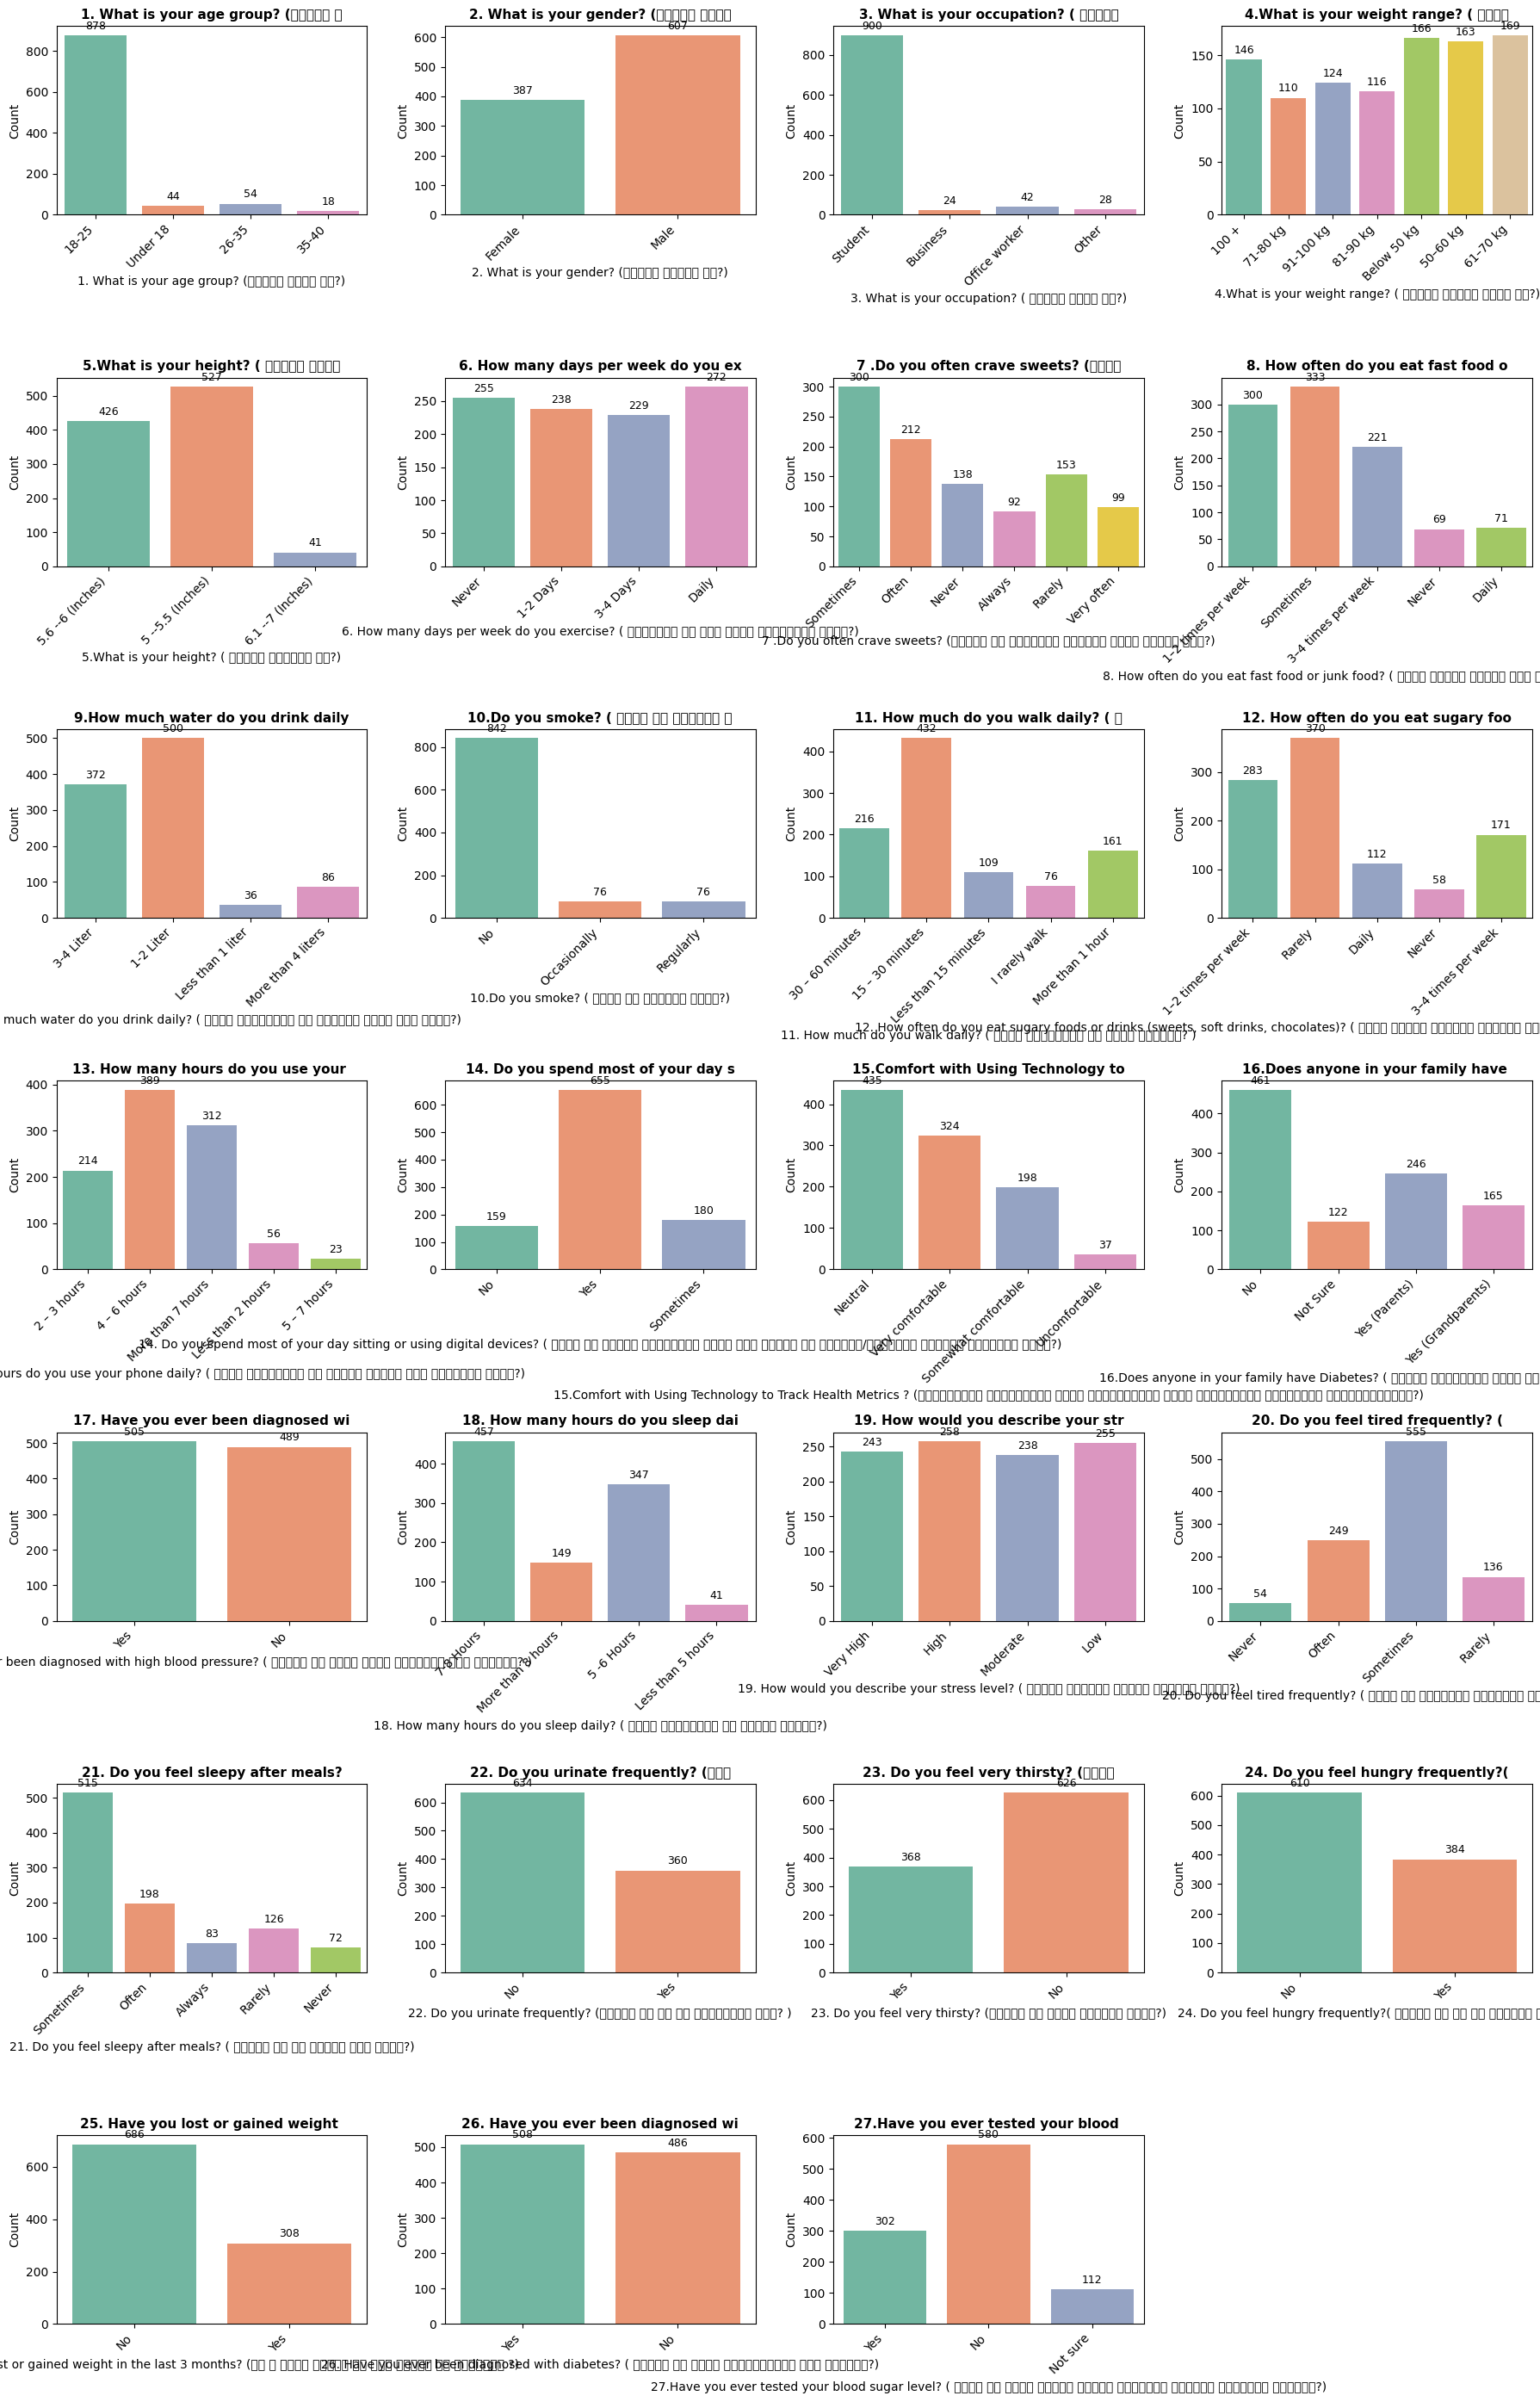

In [ ]:
import math
import matplotlib.pyplot as plt
import seaborn as sns


palette = sns.color_palette("Set2")


n_cols = 4
n_rows = math.ceil(len(categorical_cols) / n_cols)


plt.figure(figsize=(18, n_rows * 4))


for i, col in enumerate(categorical_cols):

    plt.subplot(n_rows, n_cols, i + 1)

    ax = sns.countplot(
        x=col,
        data=df,
        palette=palette
    )


    # Add count labels
    for p in ax.patches:

        height = p.get_height()

        ax.annotate(
            f'{int(height)}',
            (
                p.get_x() + p.get_width()/2,
                height
            ),
            ha='center',
            va='bottom',
            fontsize=9,
            xytext=(0,3),
            textcoords='offset points'
        )


    plt.title(
        col[:35],
        fontsize=11,
        fontweight='bold'
    )

    plt.xticks(
        rotation=45,
        ha='right'
    )

    plt.ylabel("Count")


plt.tight_layout()
plt.show()

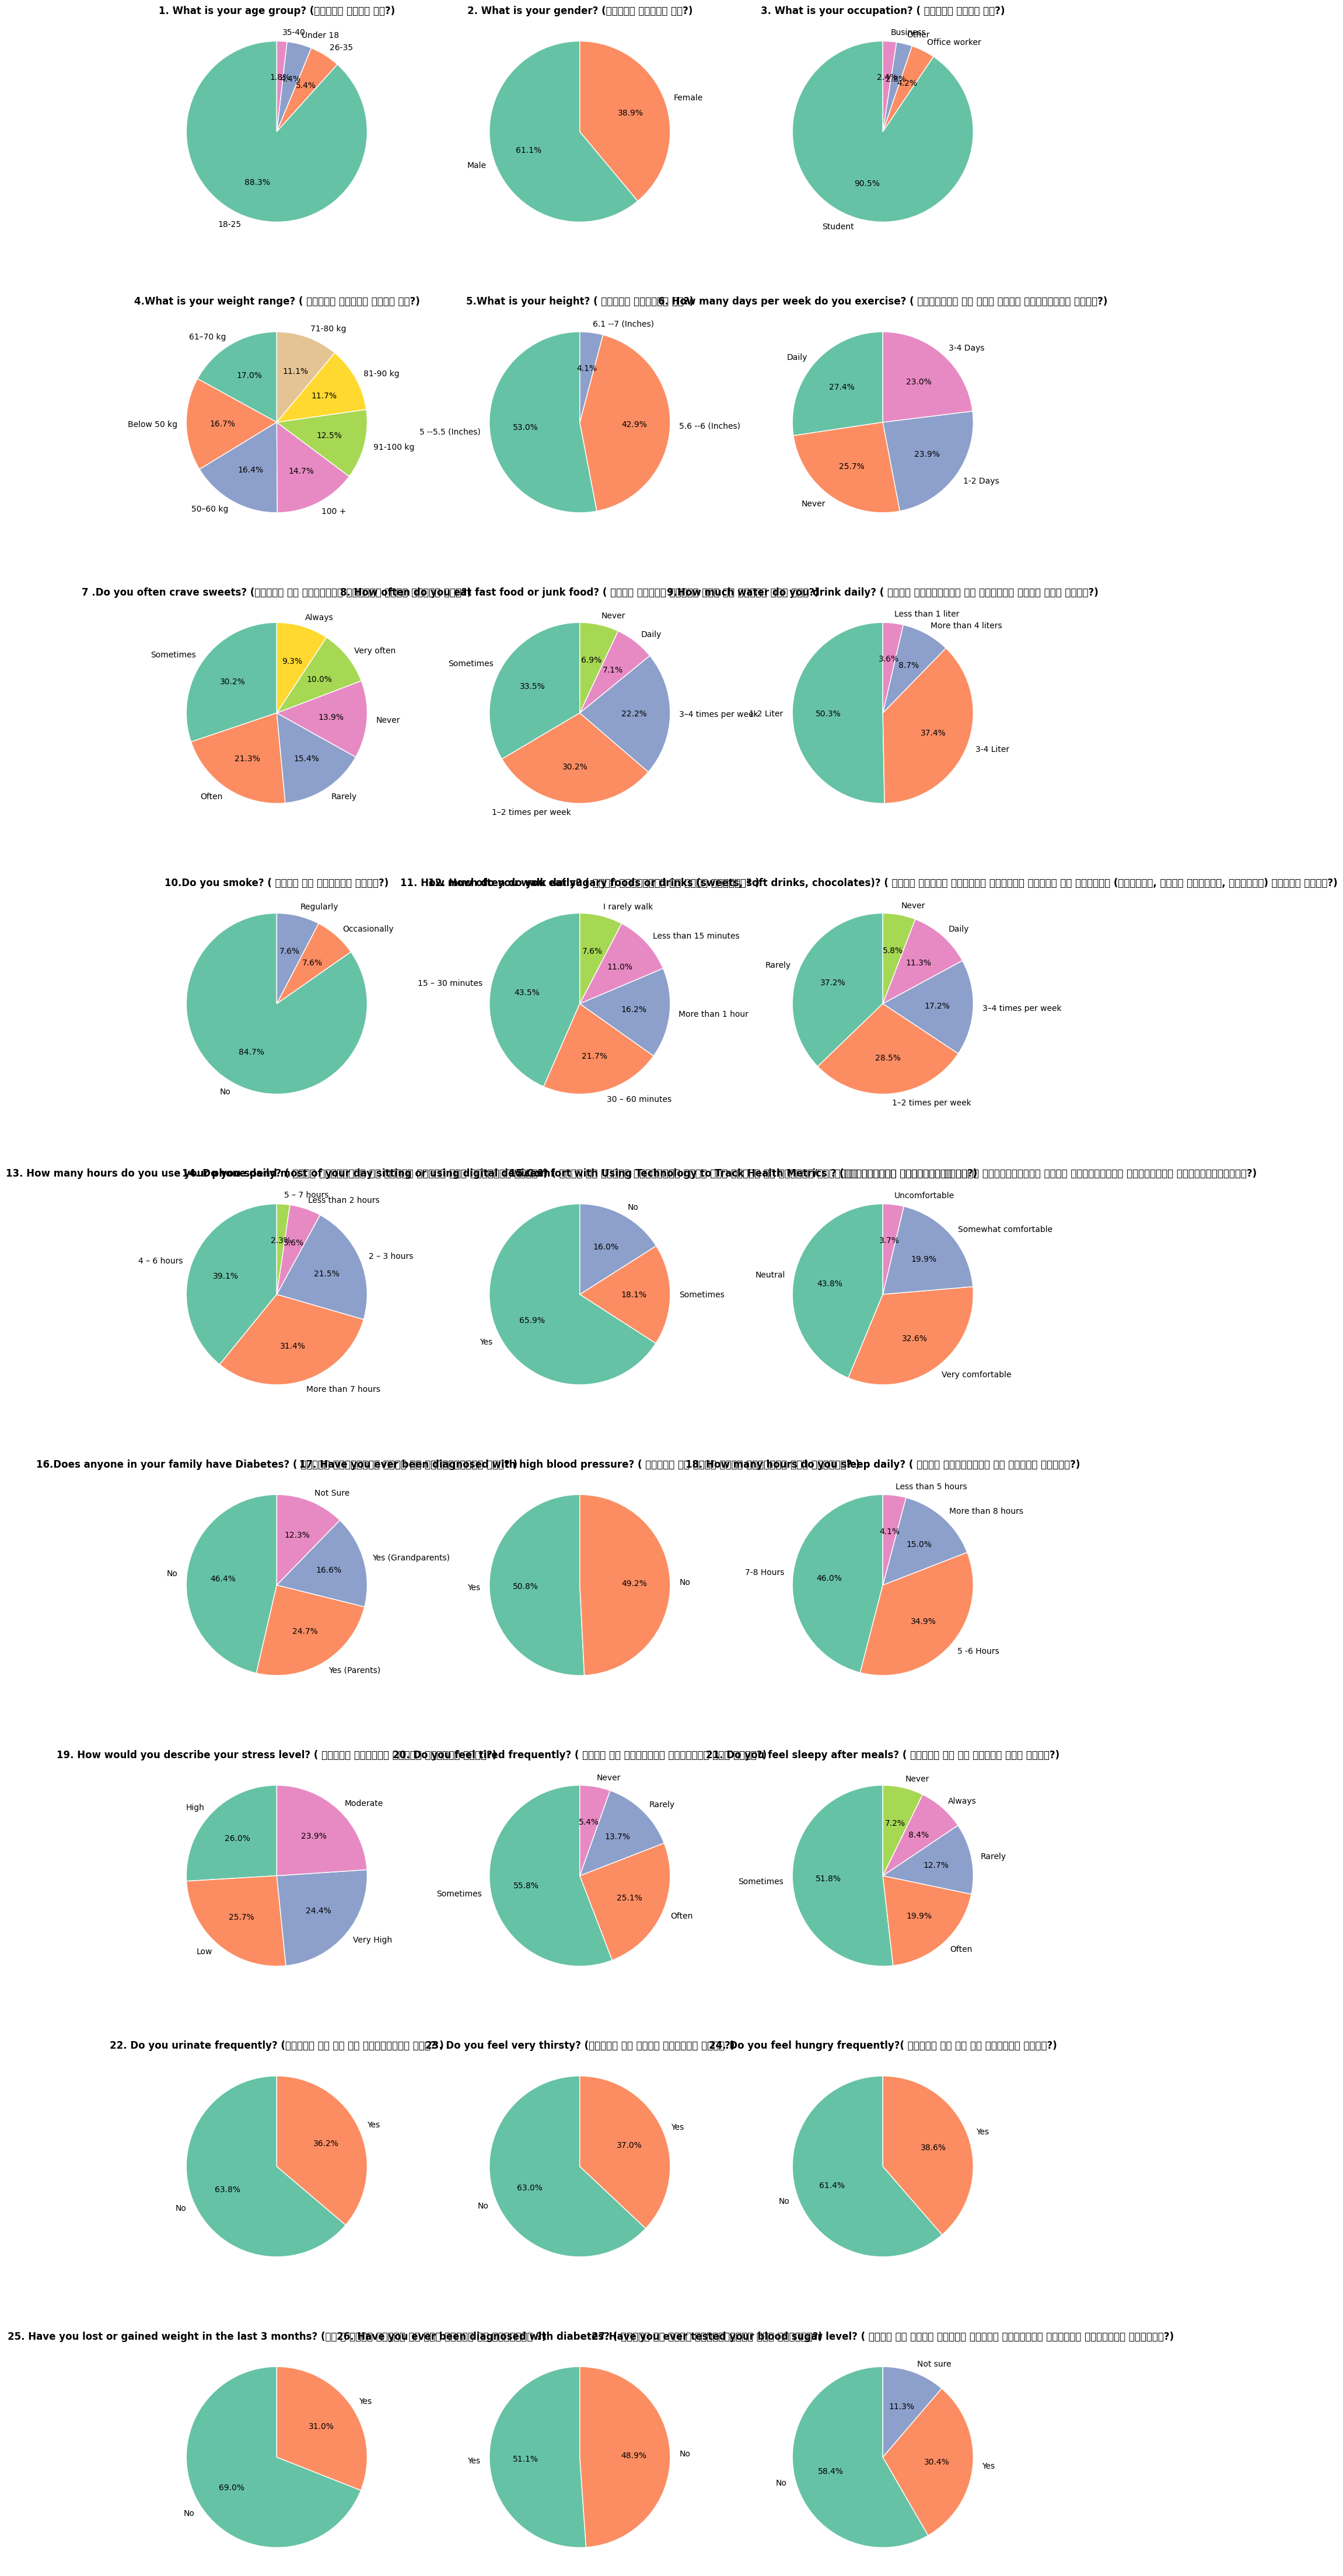

In [ ]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# Soft scientific palette (Seaborn Set2)
PIE_COLORS = sns.color_palette("Set2")

# Number of columns in grid
n_cols = 3

# Calculate required rows automatically
n_rows = math.ceil(len(categorical_cols) / n_cols)

plt.figure(figsize=(16, n_rows * 5))

for i, col in enumerate(categorical_cols):

    plt.subplot(n_rows, n_cols, i + 1)

    count = df[col].value_counts()

    plt.pie(
        count.values,
        labels=count.index,
        colors=PIE_COLORS[:len(count)],
        autopct='%1.1f%%',
        startangle=90,
        wedgeprops={'edgecolor': 'white'}
    )

    plt.title(col, fontsize=12, fontweight='bold')


plt.tight_layout()
plt.show()

In [ ]:
df.columns

Index(['1. What is your age group? (আপনার বয়স কত?)',
       '2. What is your gender? (আপনার লিঙ্গ কী?)',
       '3. What is your occupation? ( আপনার পেশা কী?)',
       '4.What is your weight range? ( আপনার ওজনের সীমা কত?)',
       '5.What is your height? ( আপনার উচ্চতা কত?)',
       '6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)',
       '7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)',
       '8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)',
       '9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)',
       '10.Do you smoke? ( আপনি কি ধূমপান করেন?)',
       '11. How much do you walk daily? ( আপনি প্রতিদিন কত সময় হাঁটেন? )',
       '12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)? ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)',
       '13. How many hours do you use your phone daily

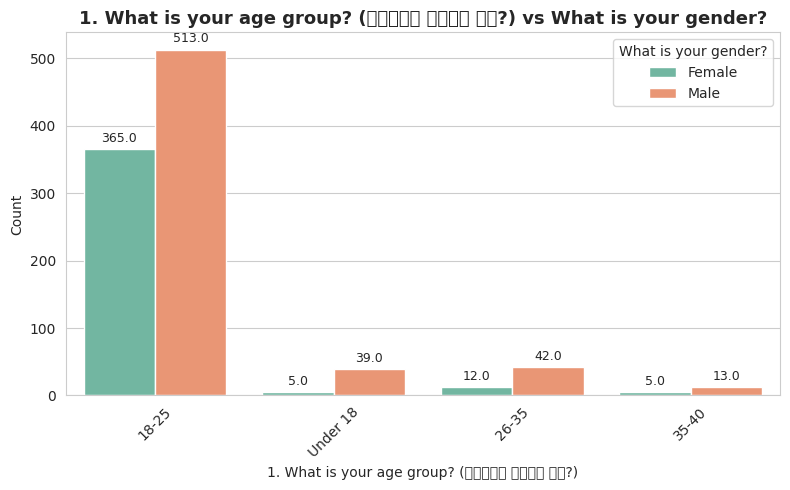

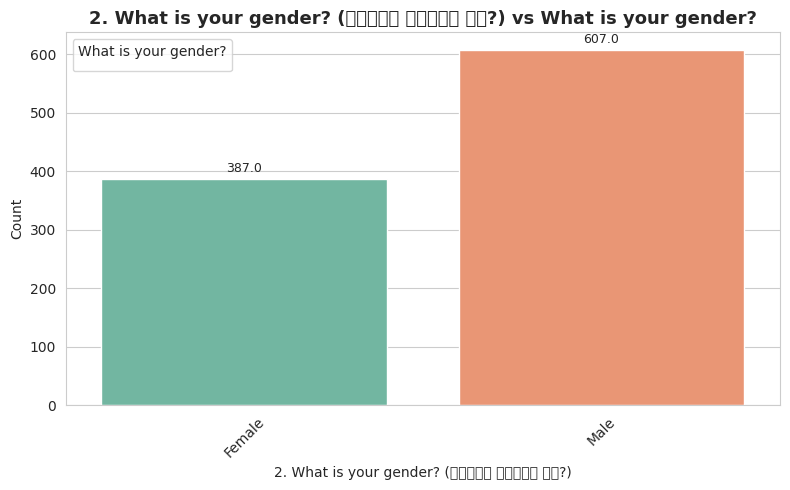

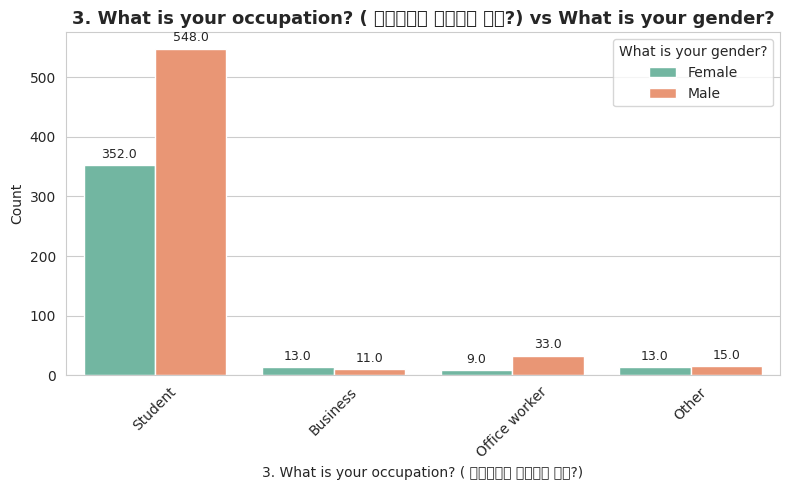

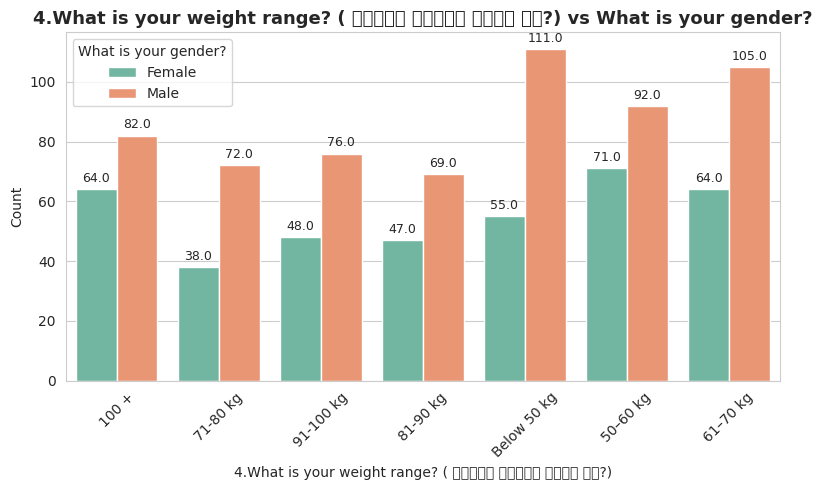

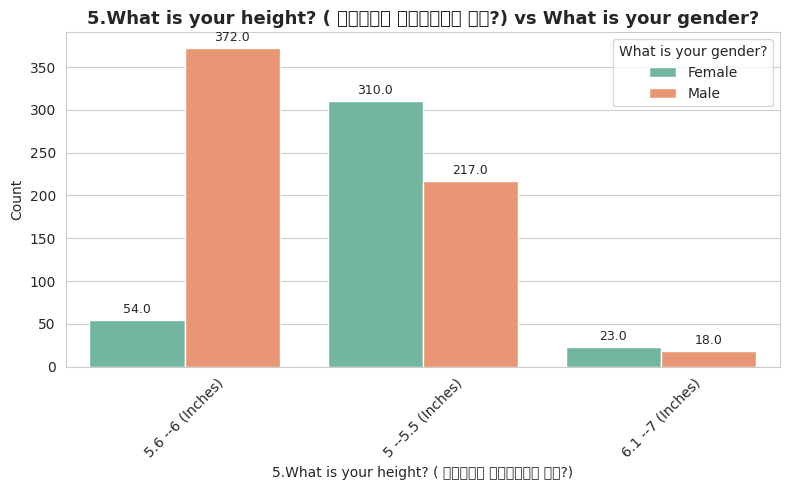

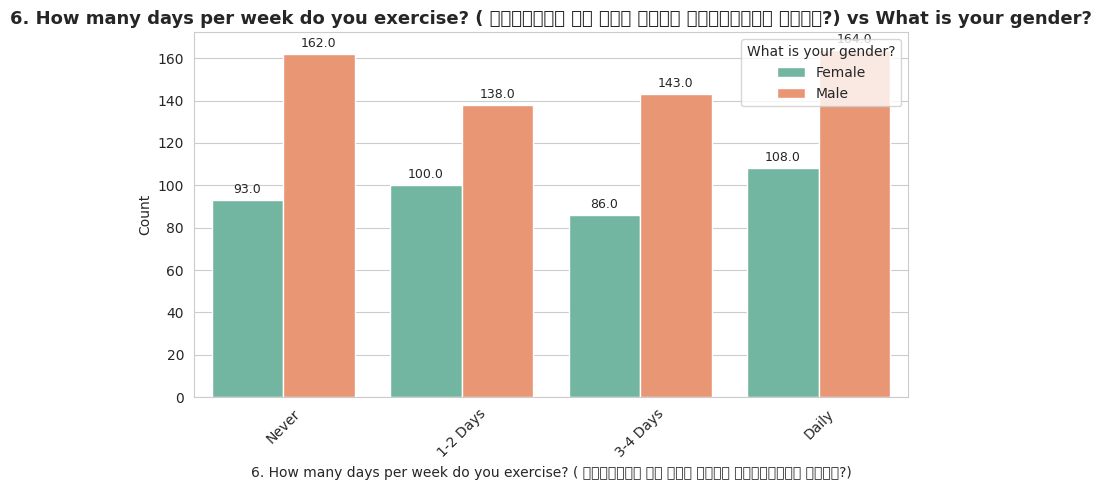

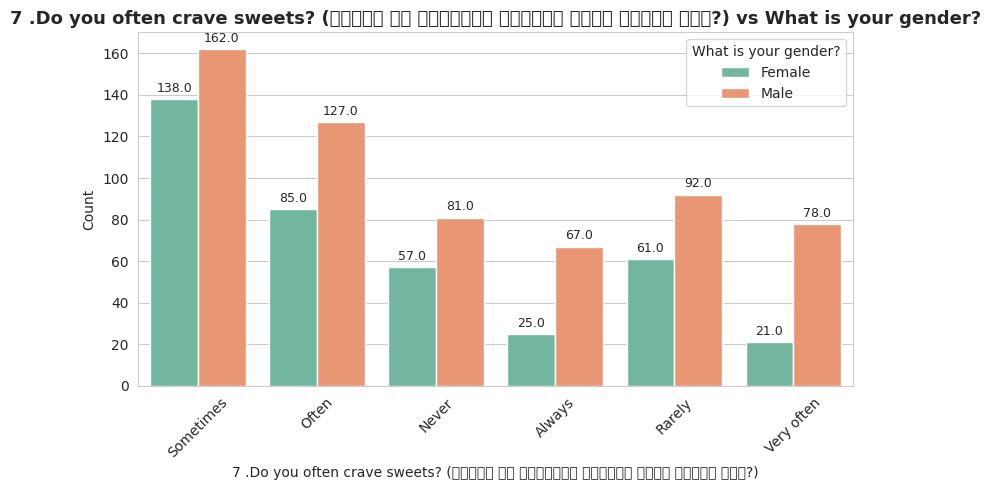

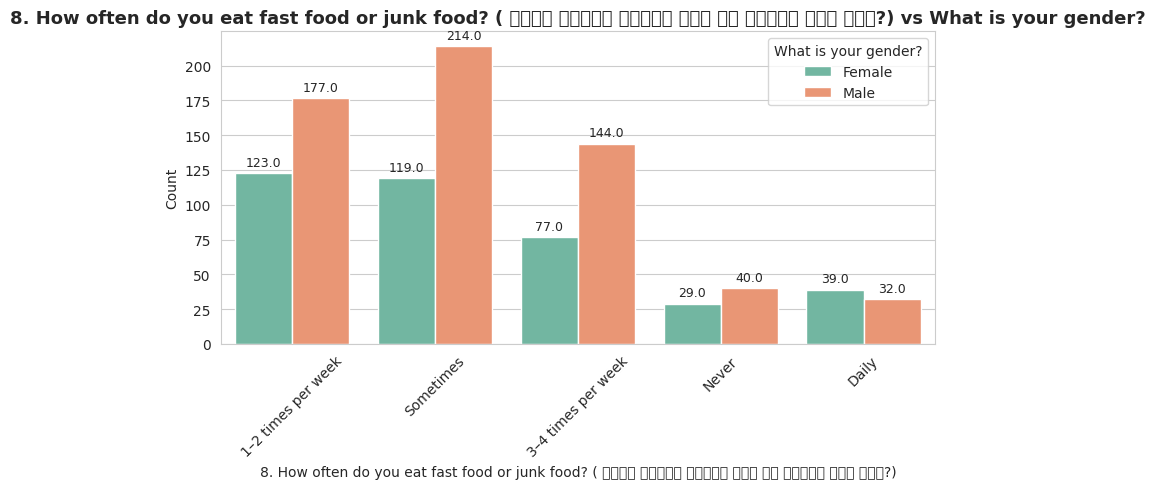

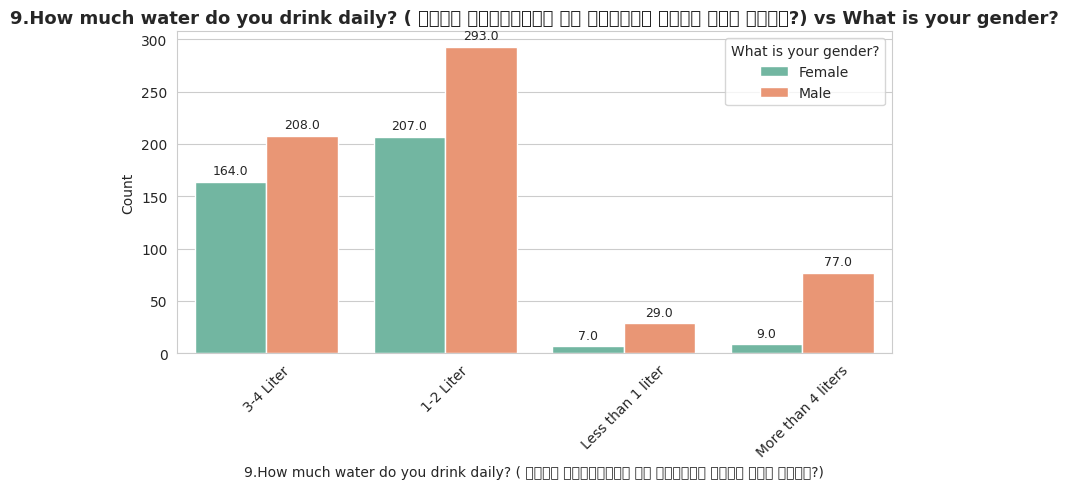

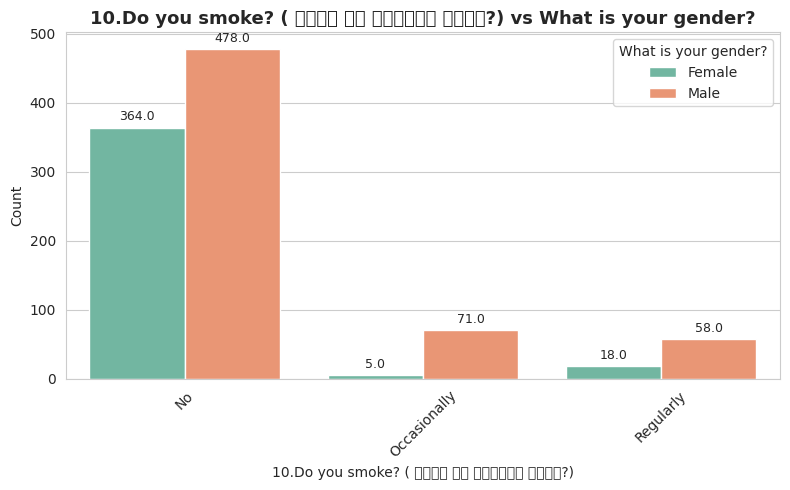

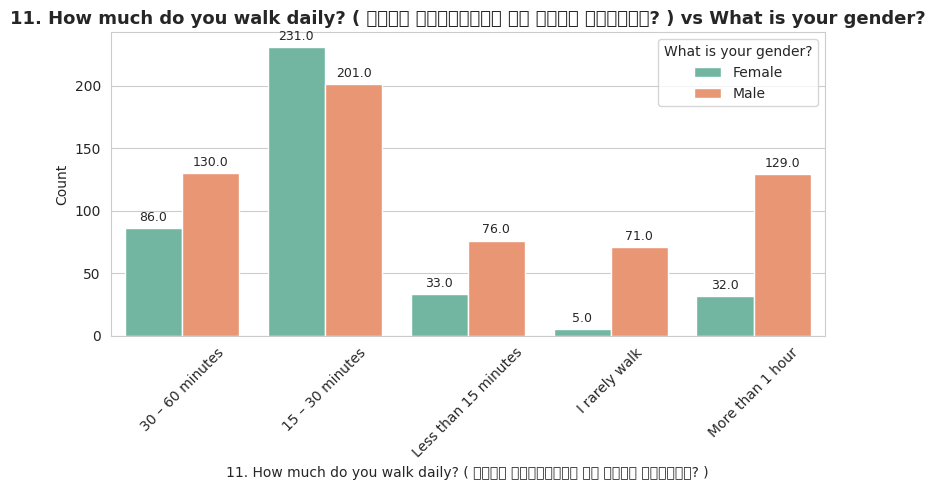

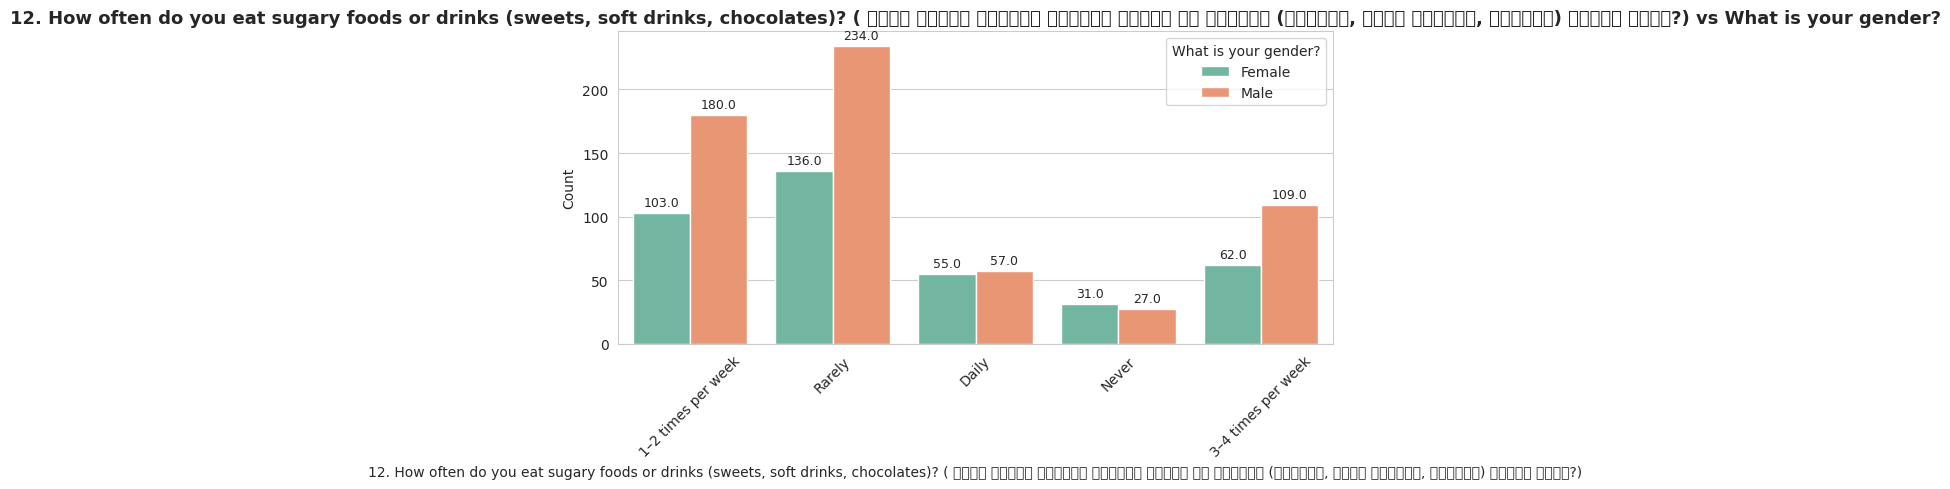

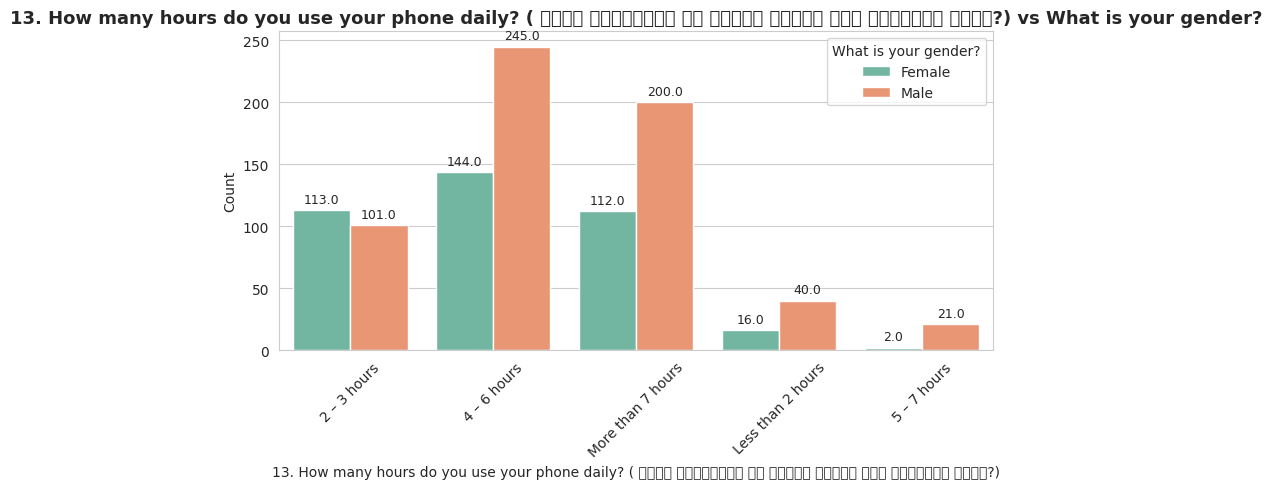

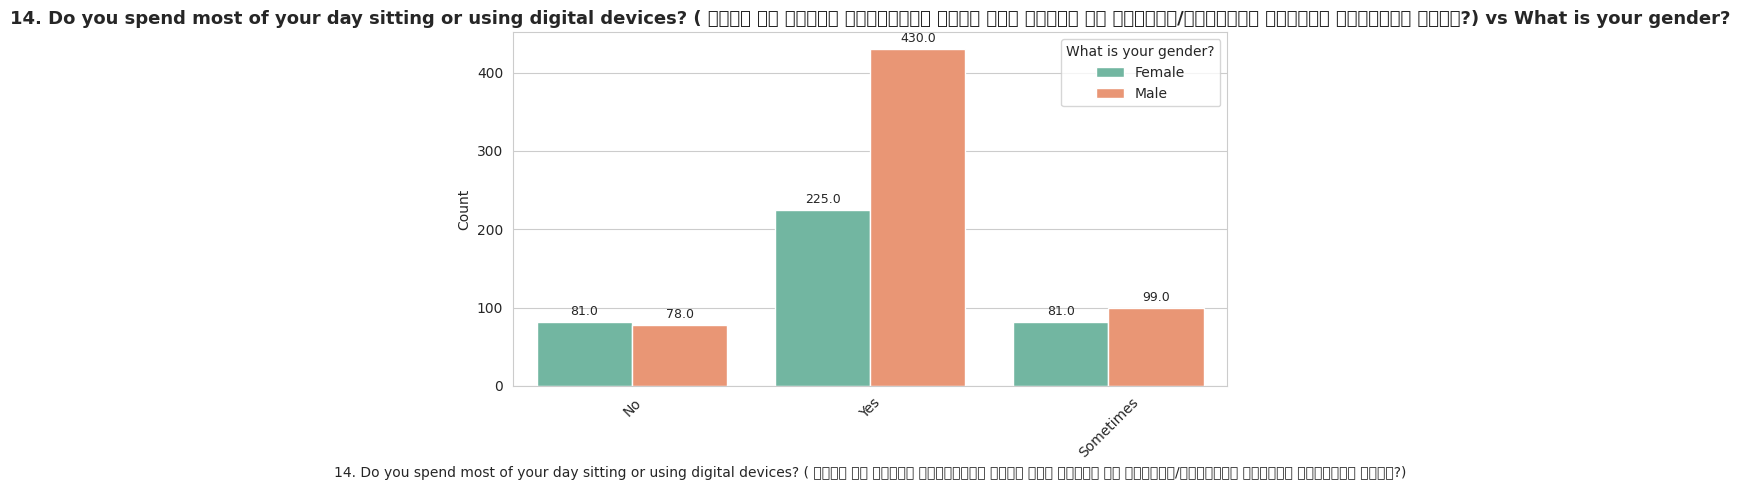

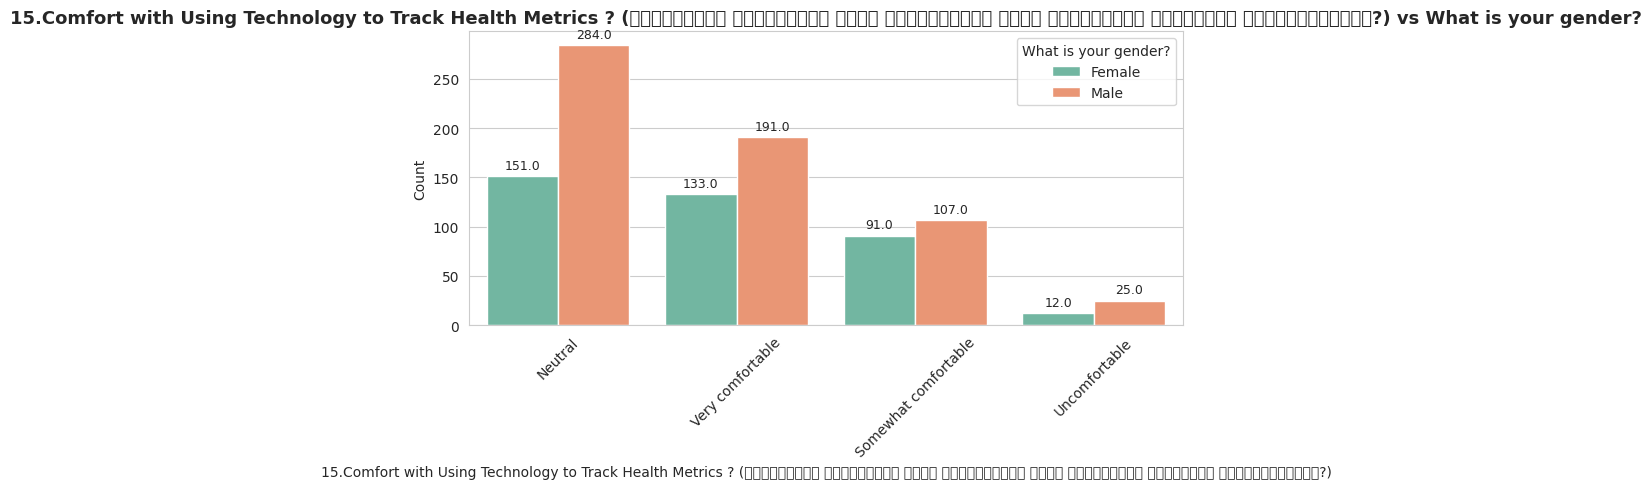

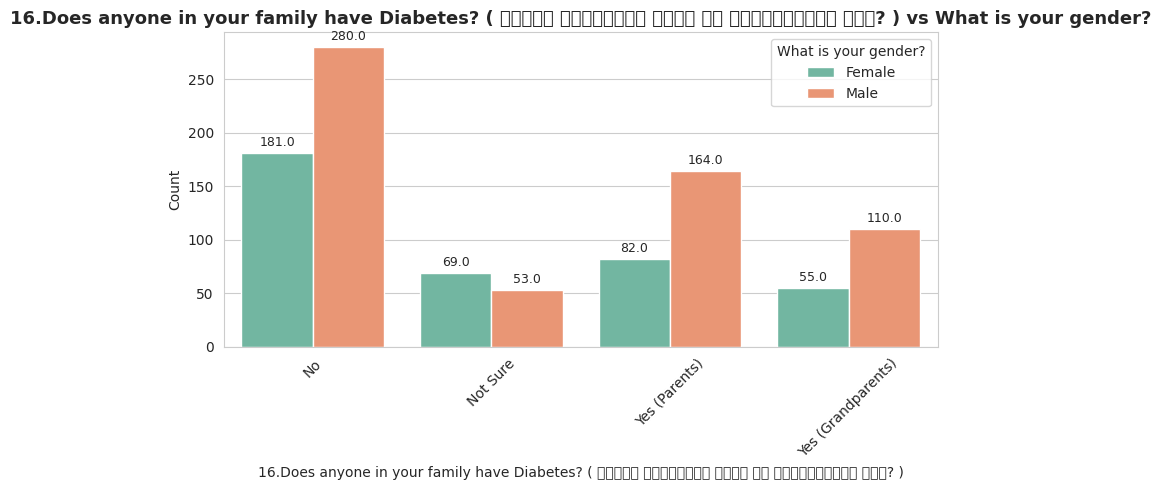

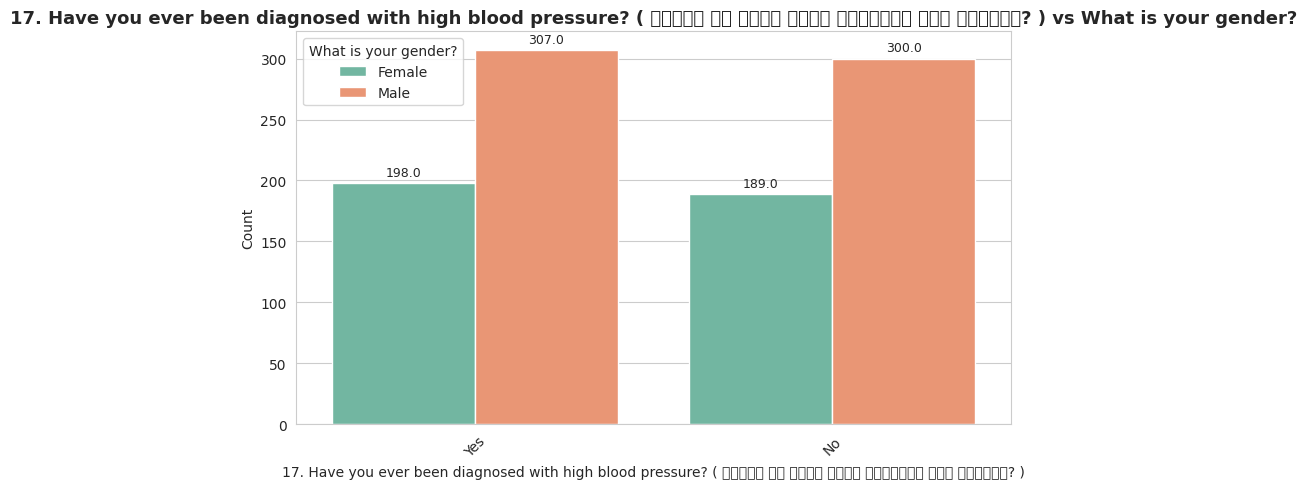

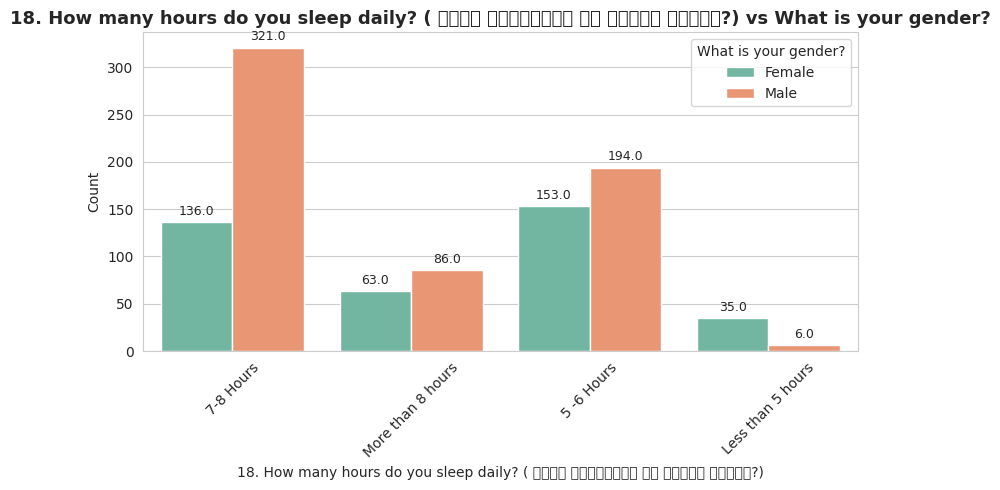

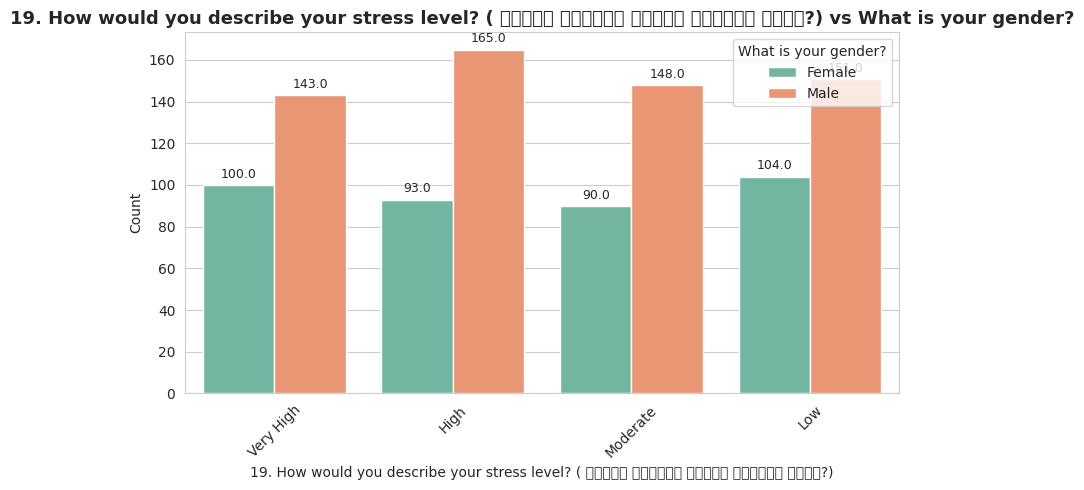

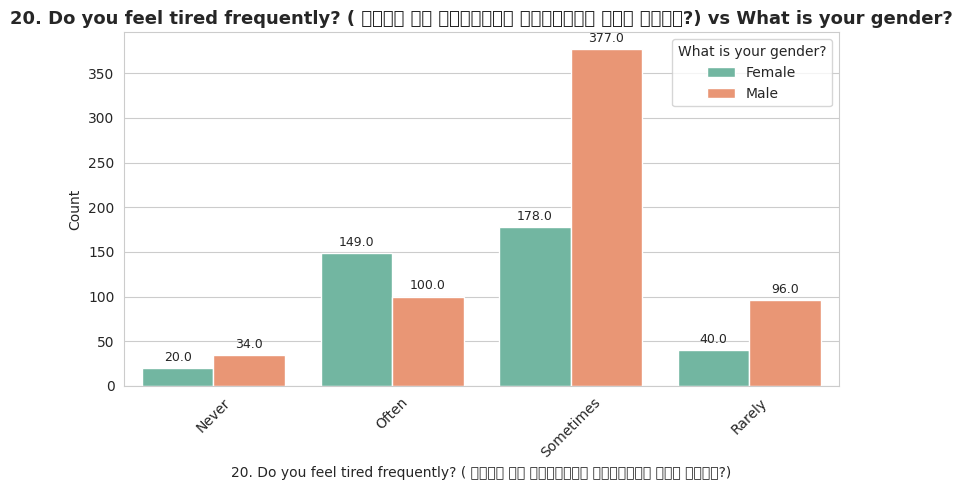

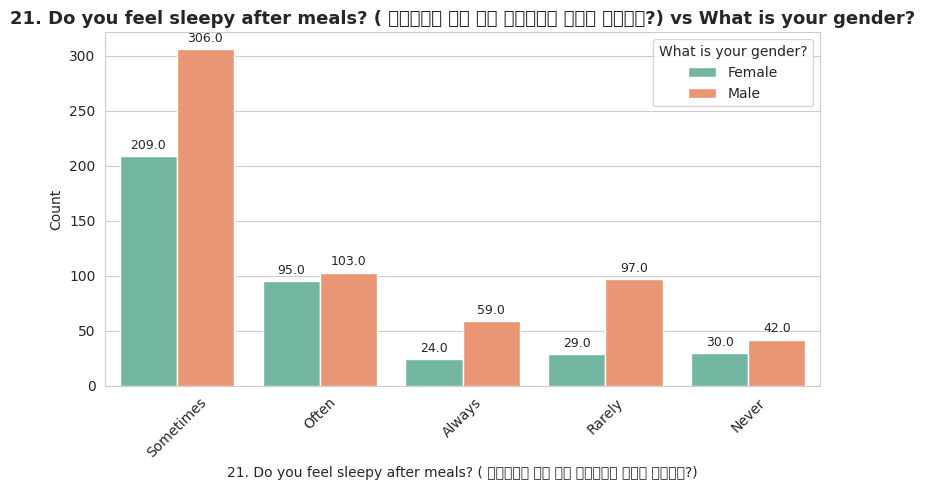

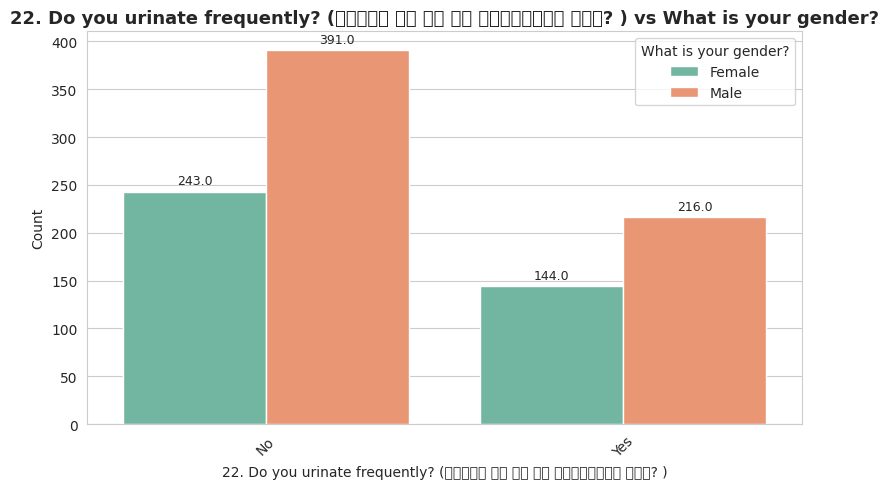

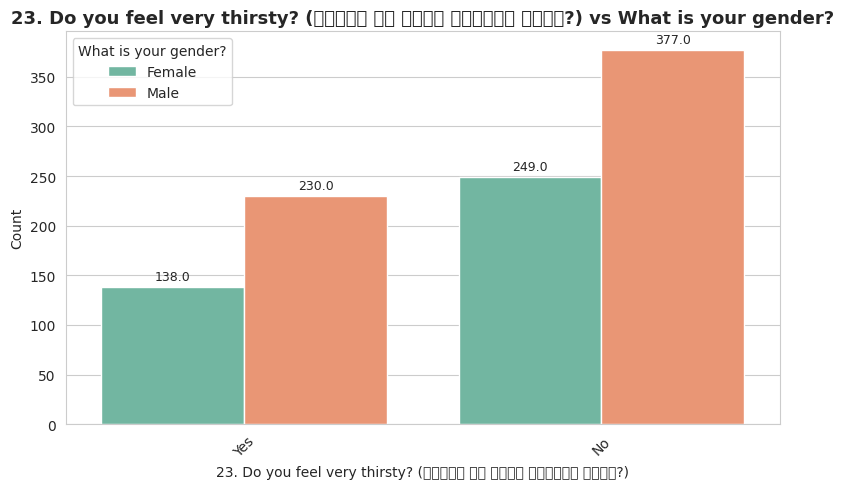

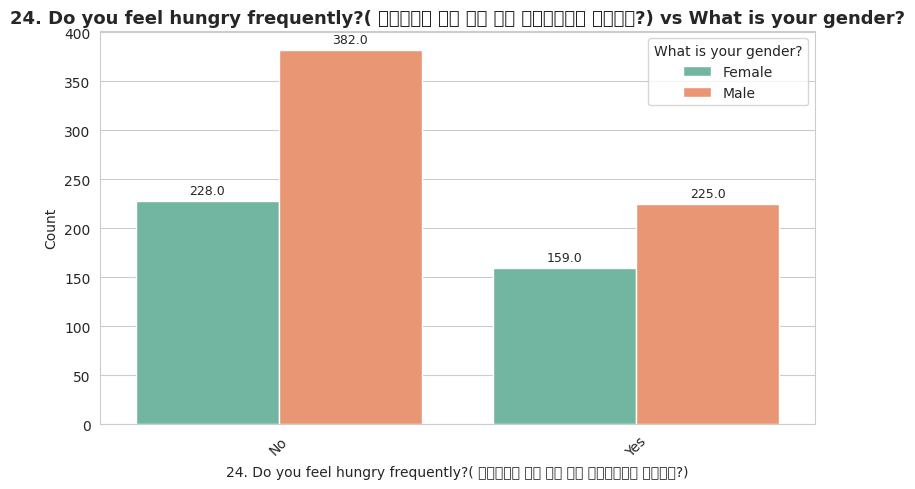

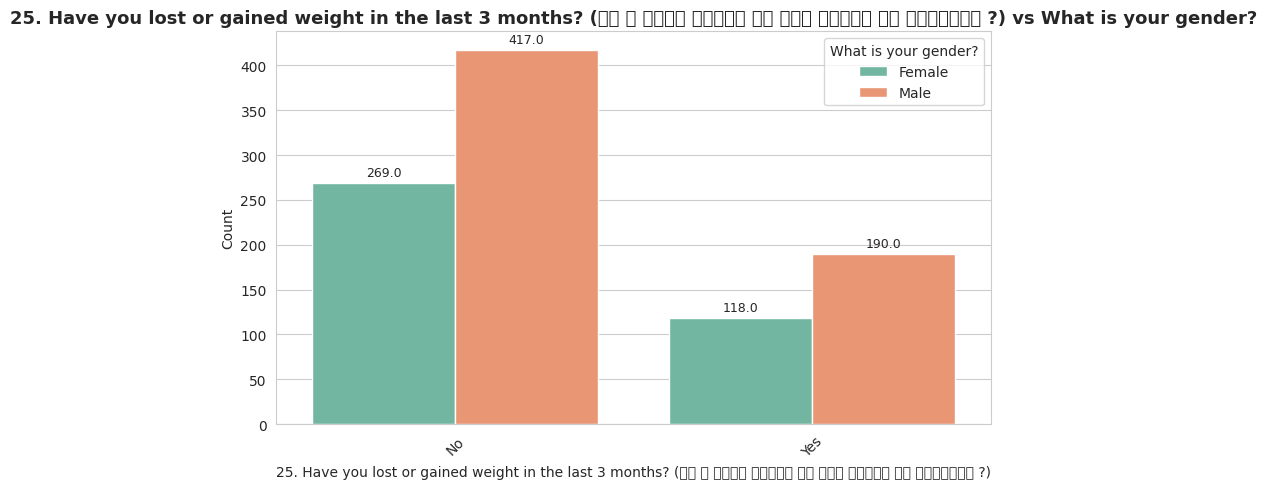

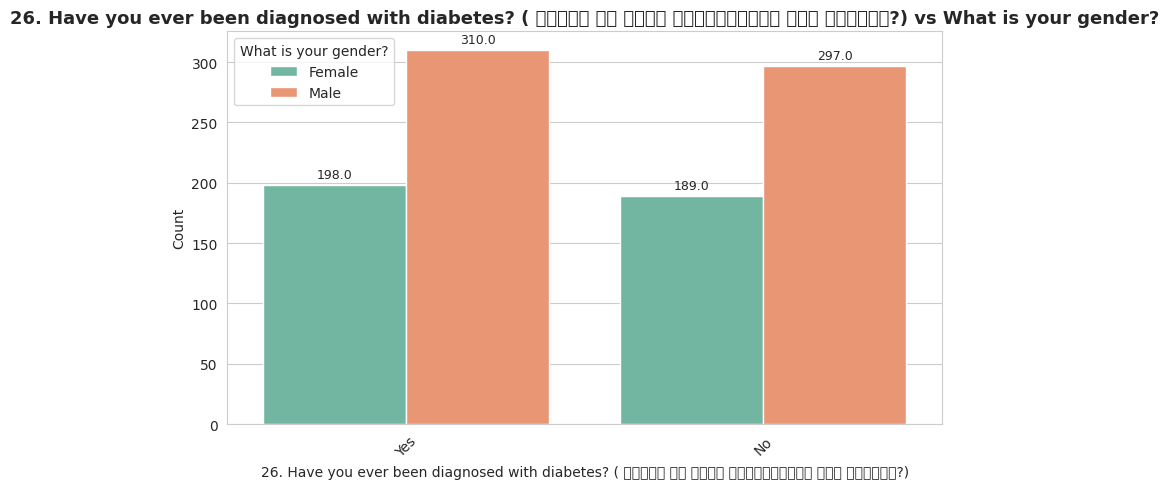

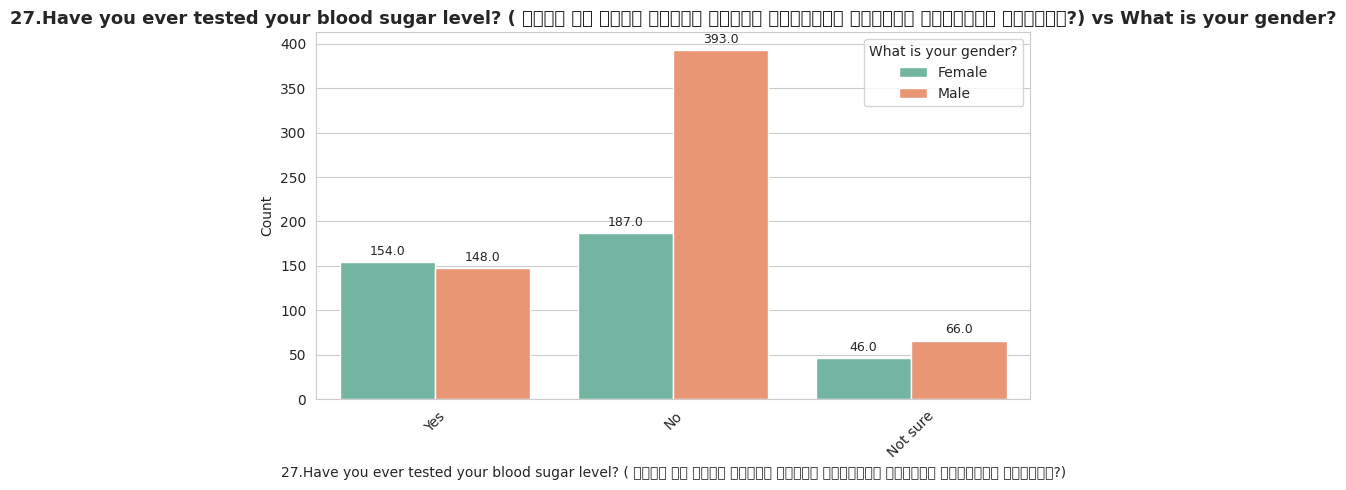

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

for col in categorical_cols:
    plt.figure(figsize=(8,5))

    ax = sns.countplot(
        x=col,
        hue='2. What is your gender? (আপনার লিঙ্গ কী?)',
        data=df,
        palette="Set2"
    )

    # Add count labels on top
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(
                f'{height}',  # <-- just the count
                (p.get_x() + p.get_width()/2., height),
                ha='center',
                va='bottom',
                fontsize=9,
                xytext=(0,3),
                textcoords='offset points'
            )

    plt.xticks(rotation=45)
    plt.title(f"{col} vs What is your gender?", fontsize=13, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.legend(title="What is your gender?")

    plt.tight_layout()
    plt.show()


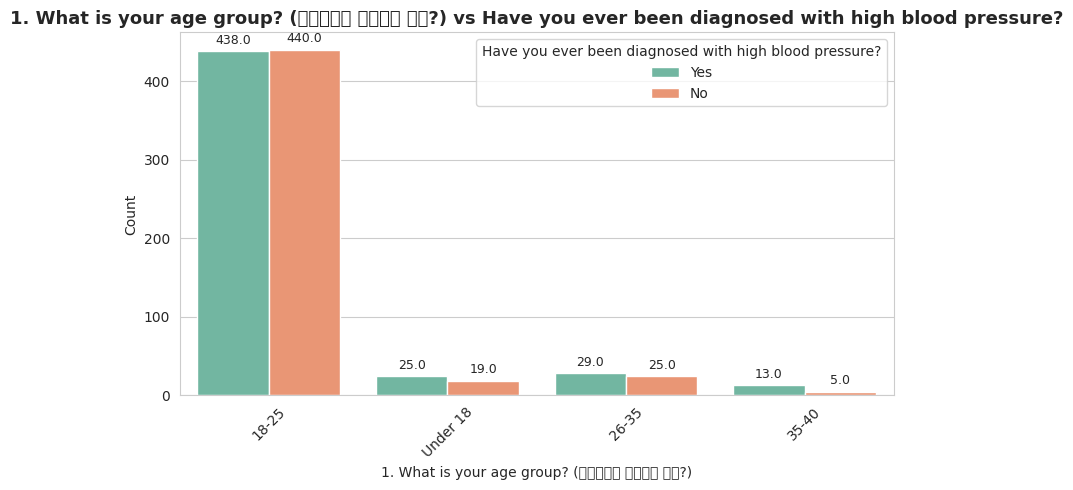

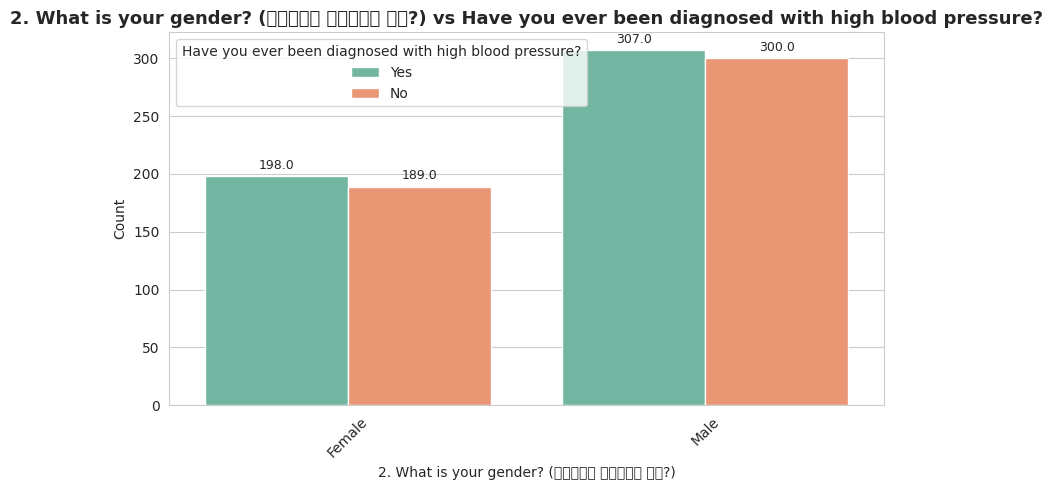

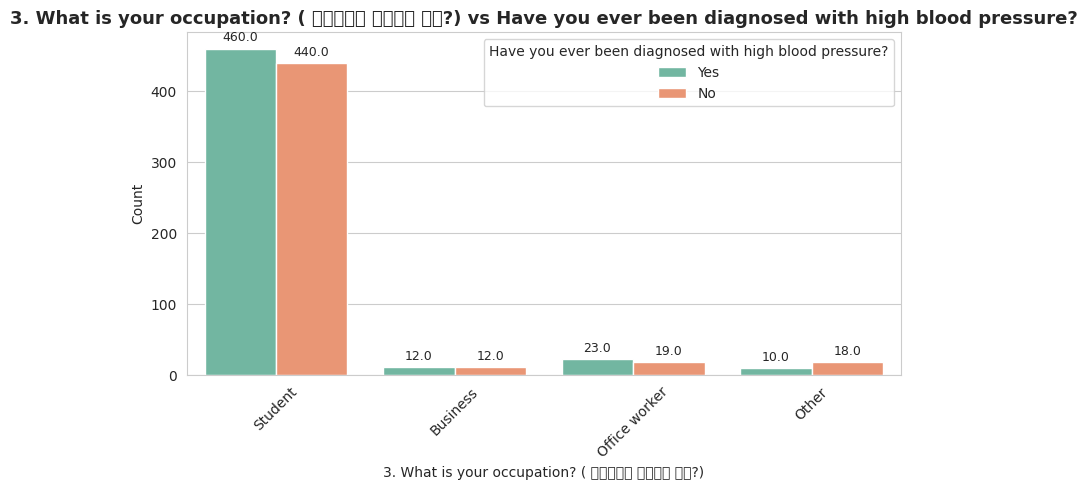

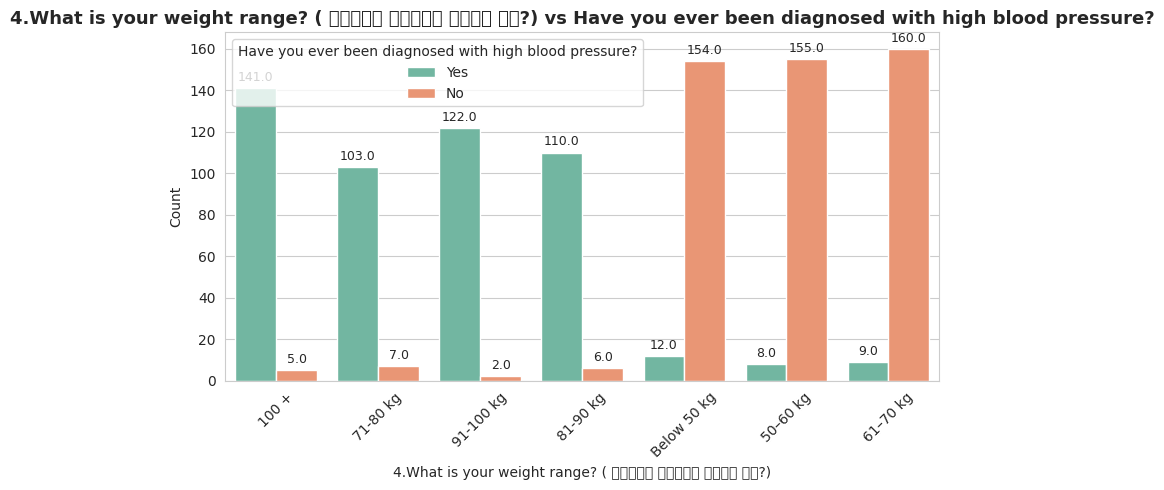

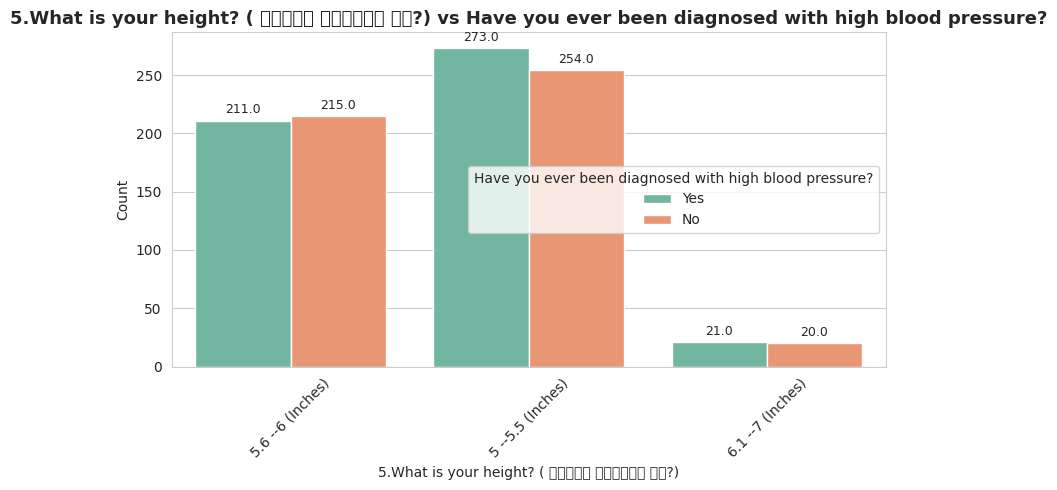

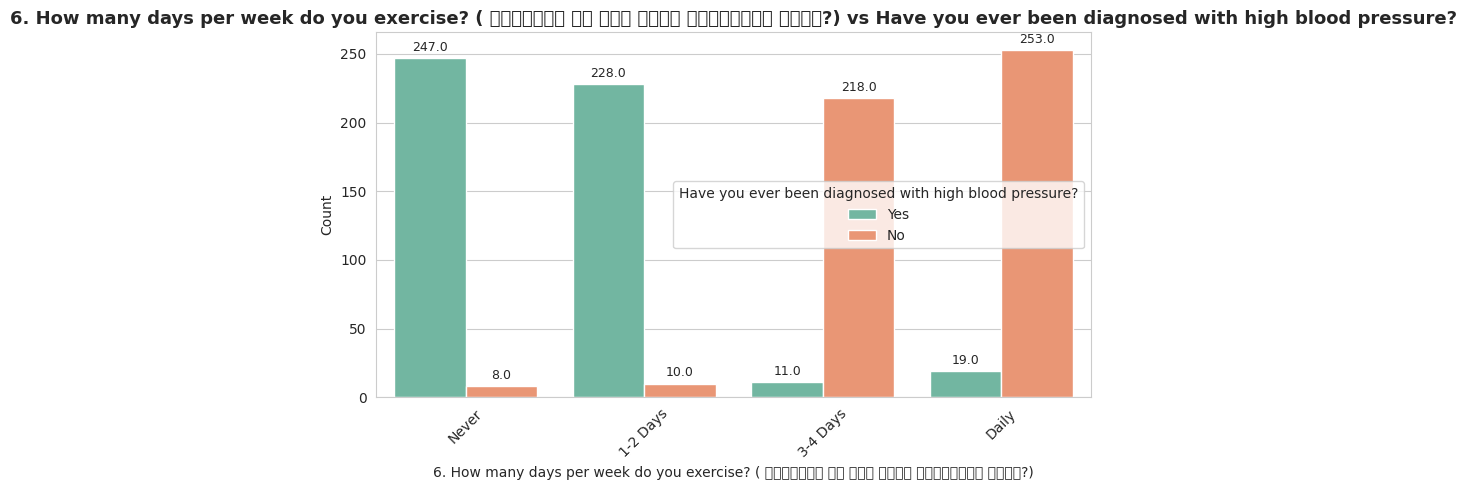

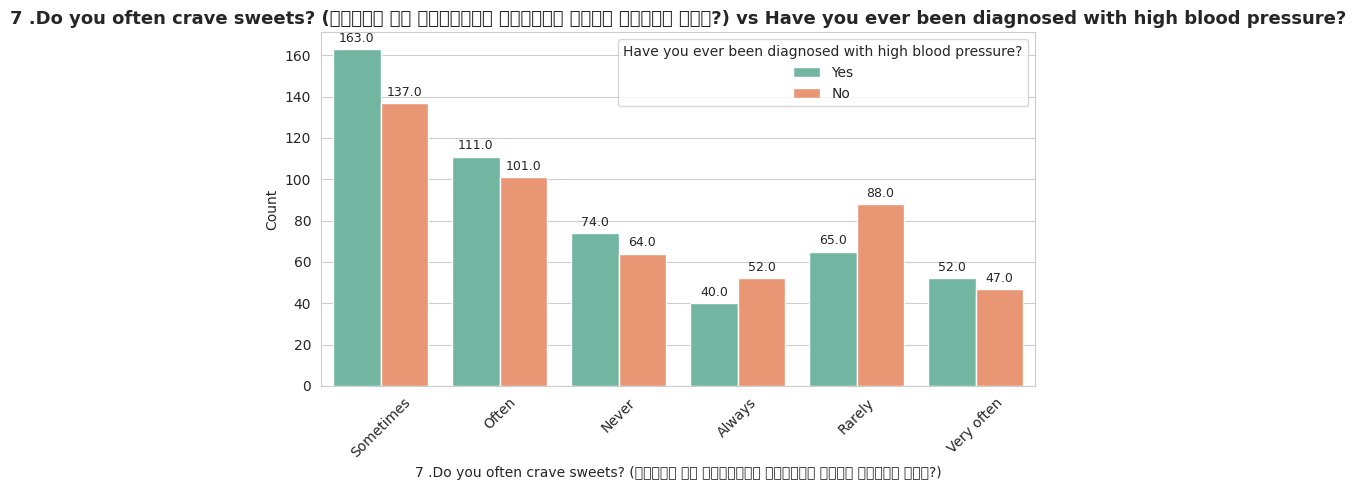

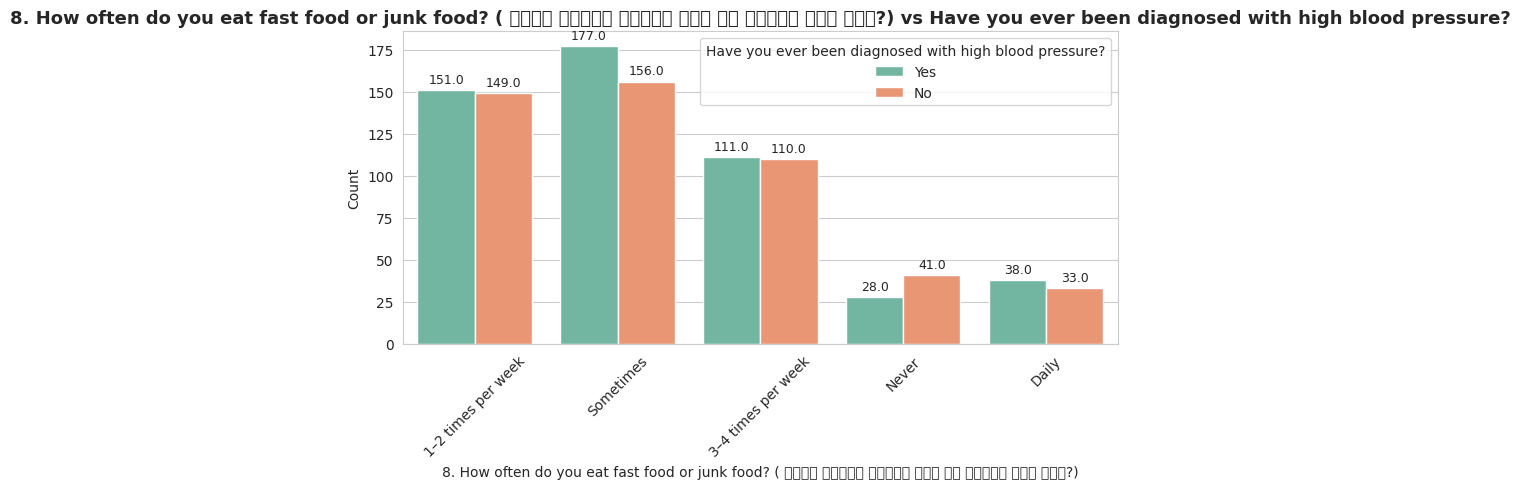

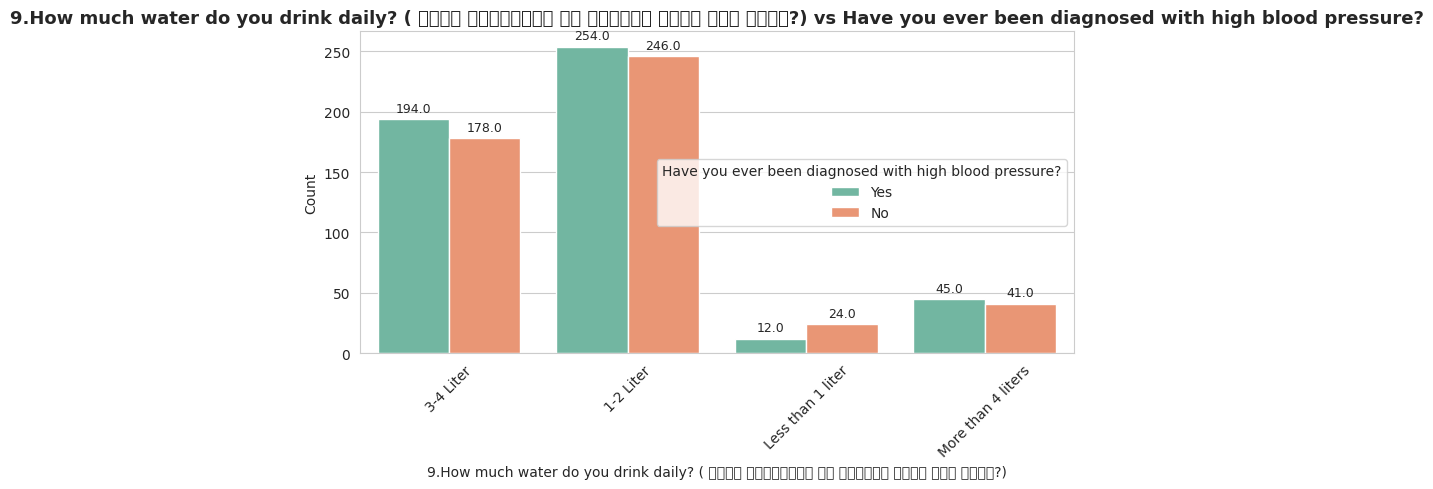

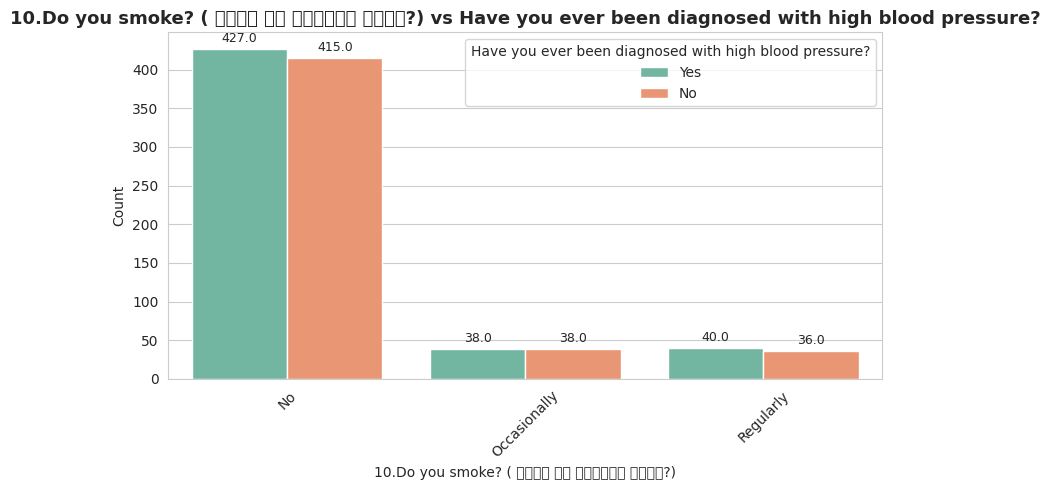

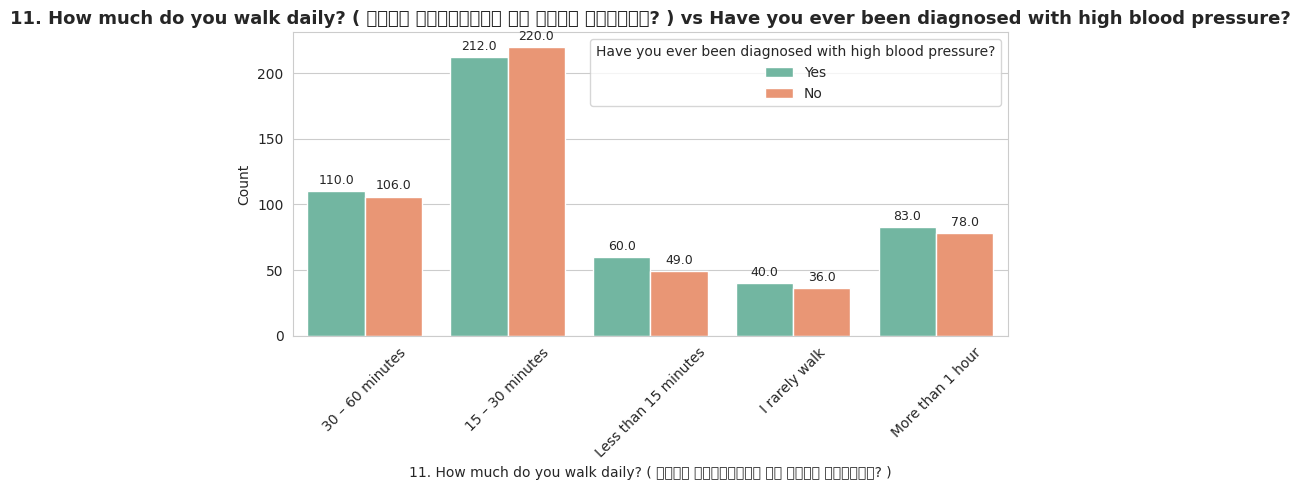

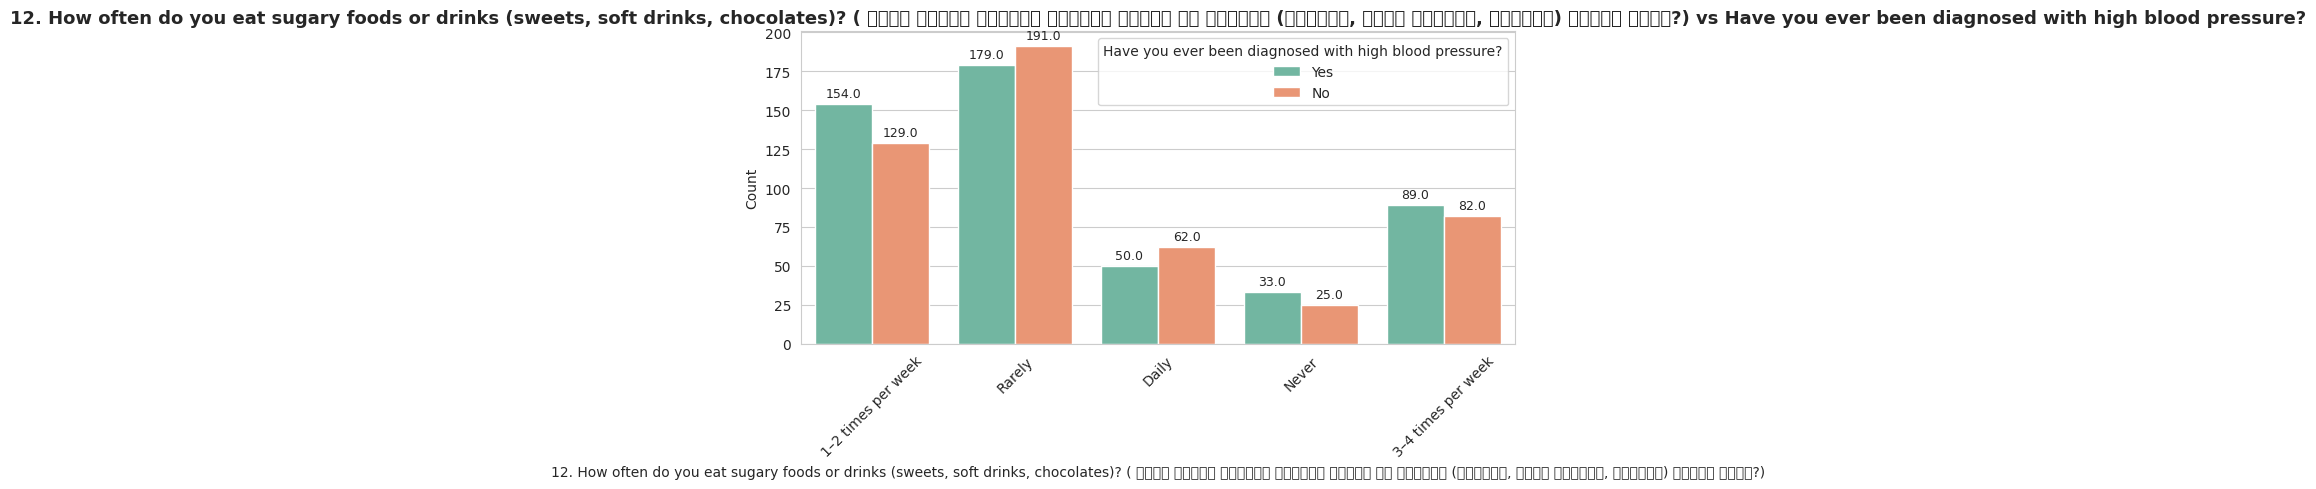

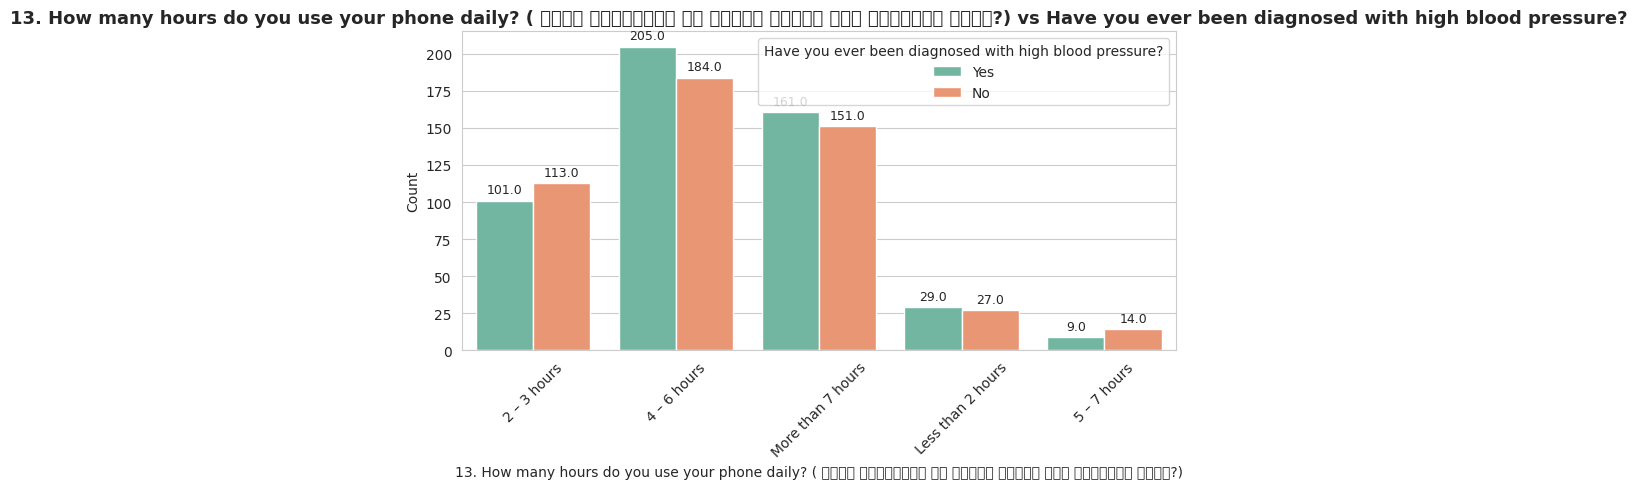

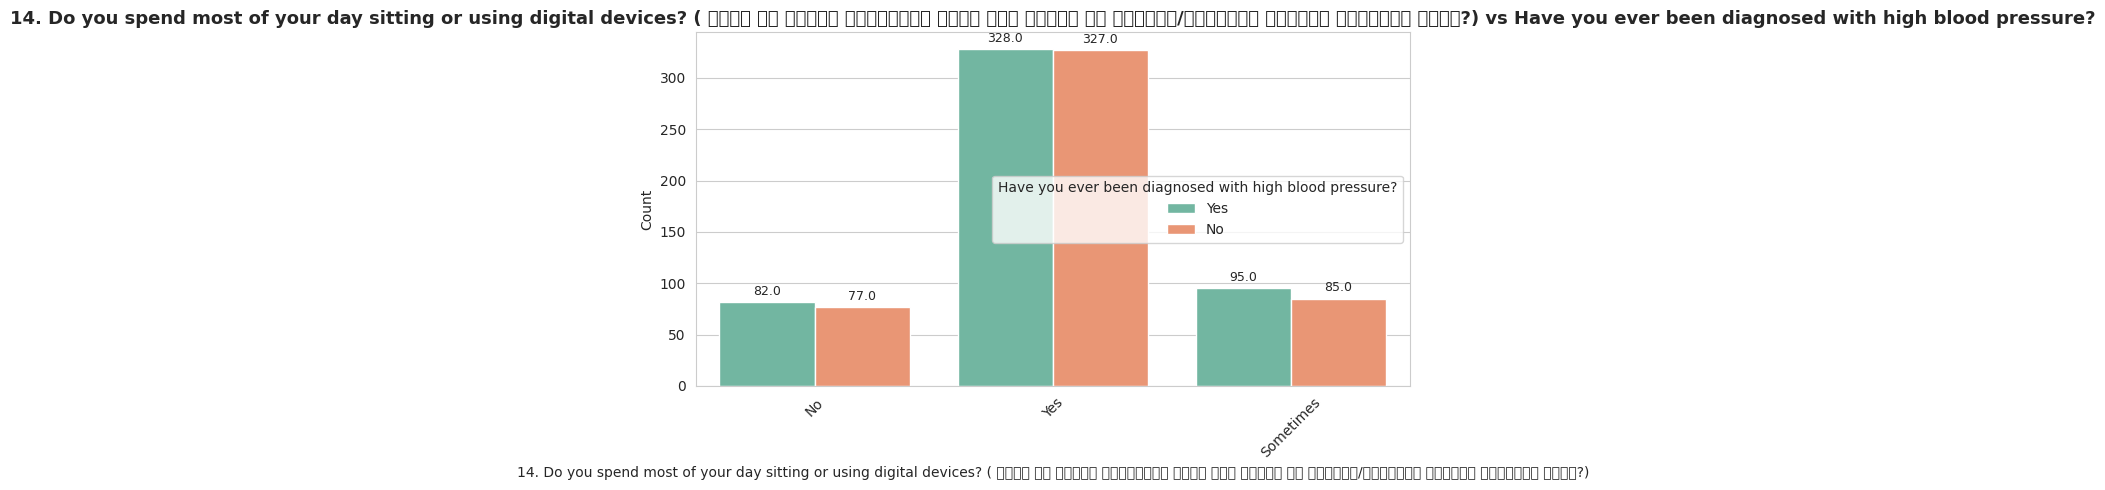

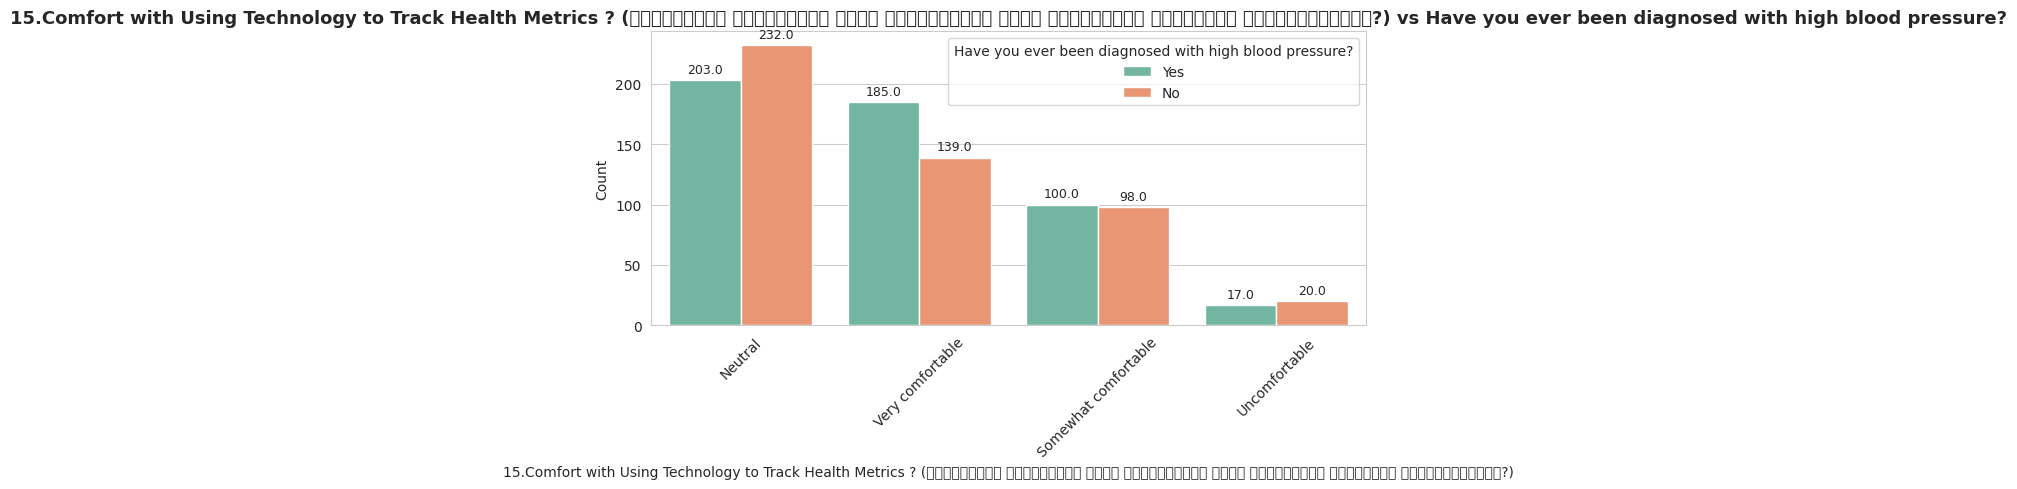

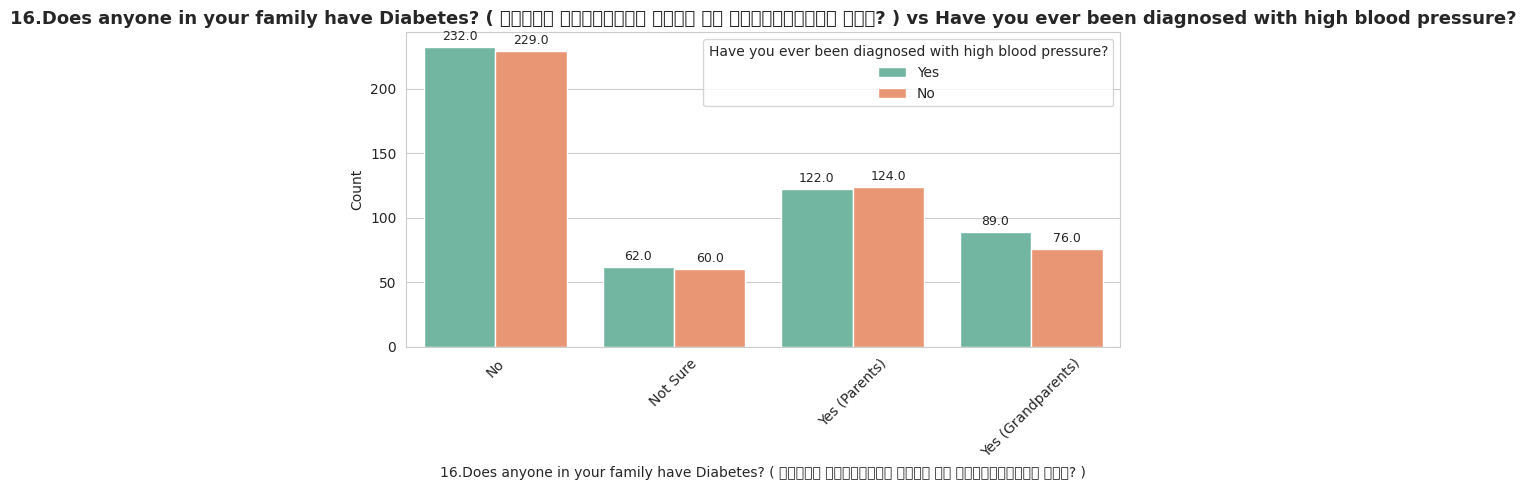

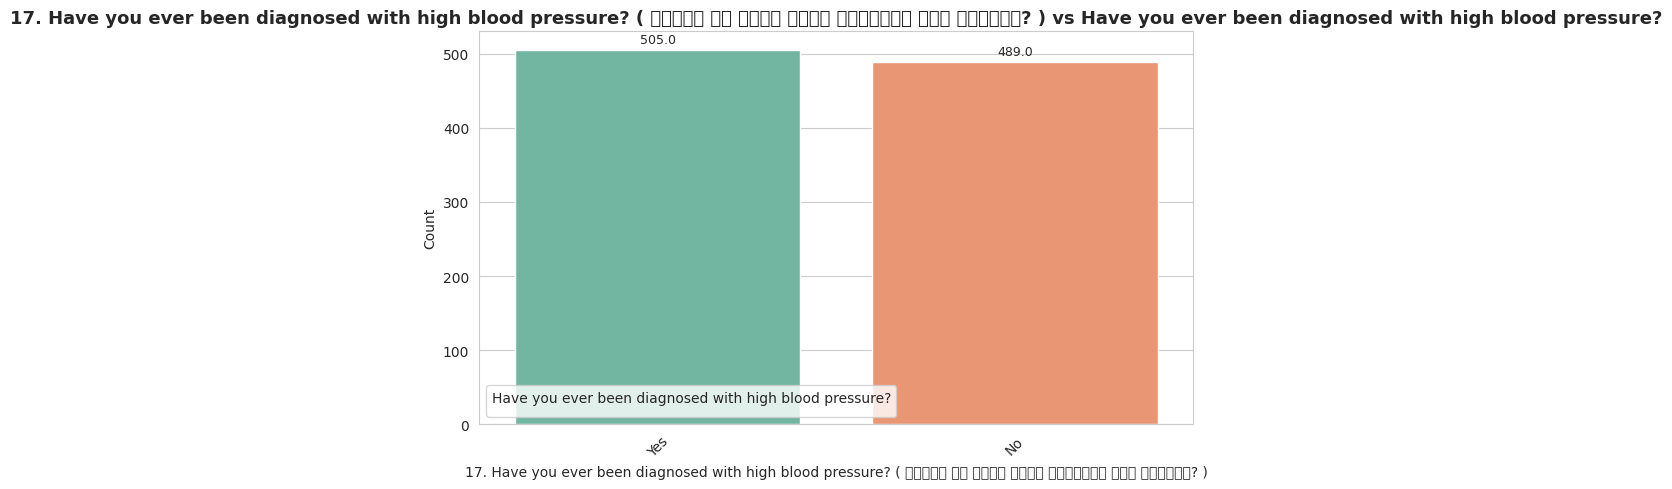

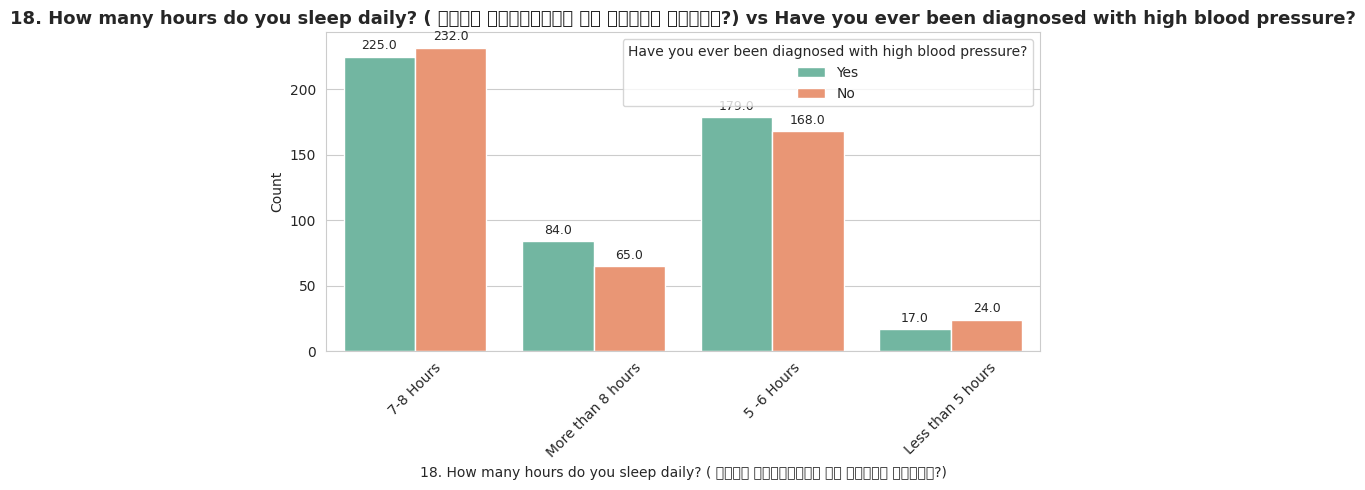

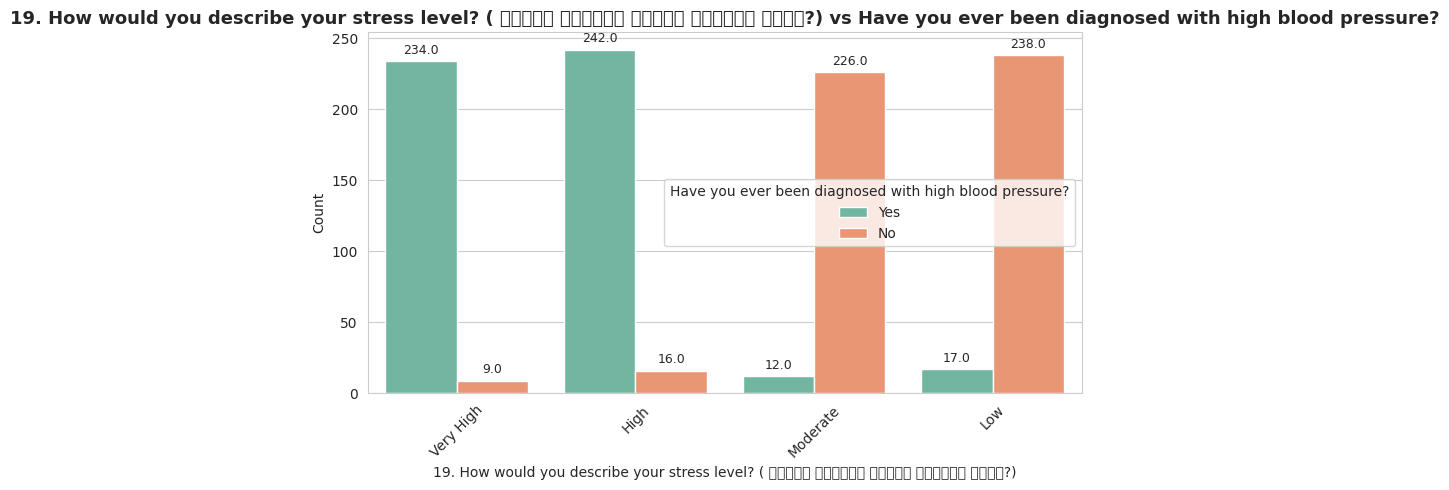

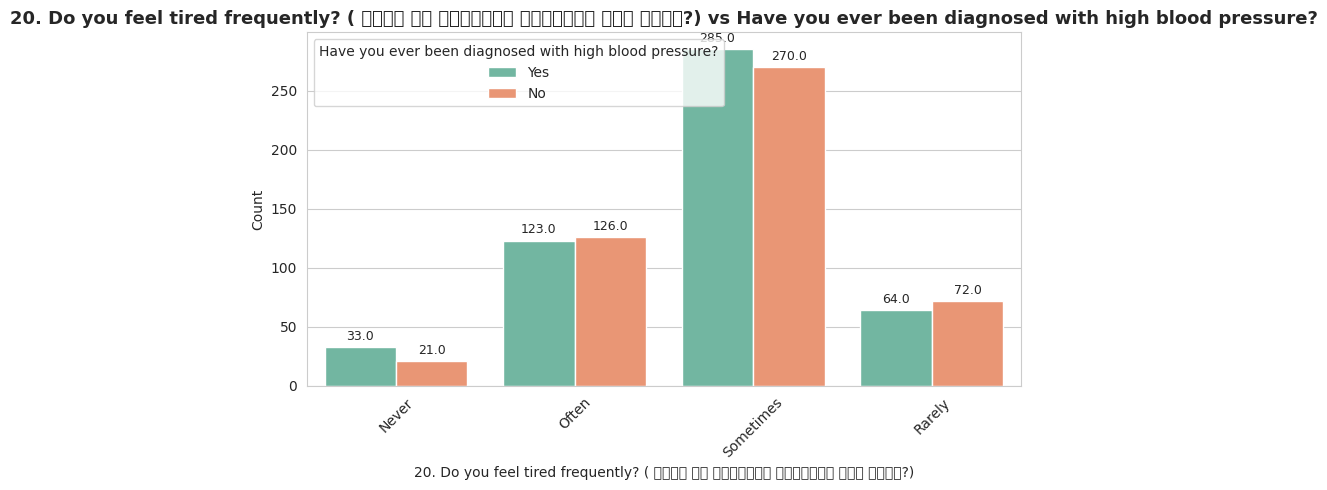

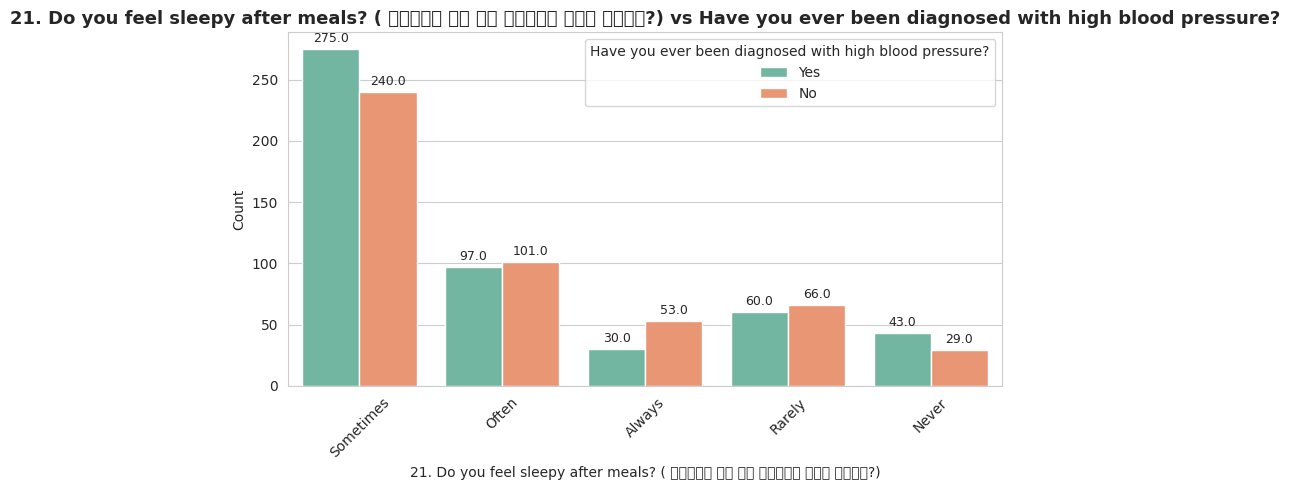

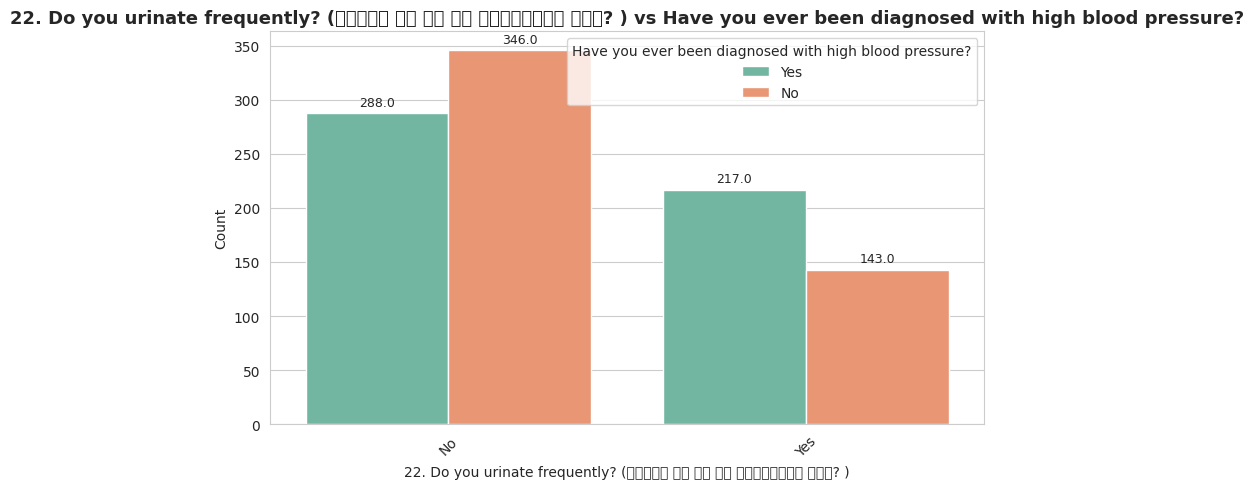

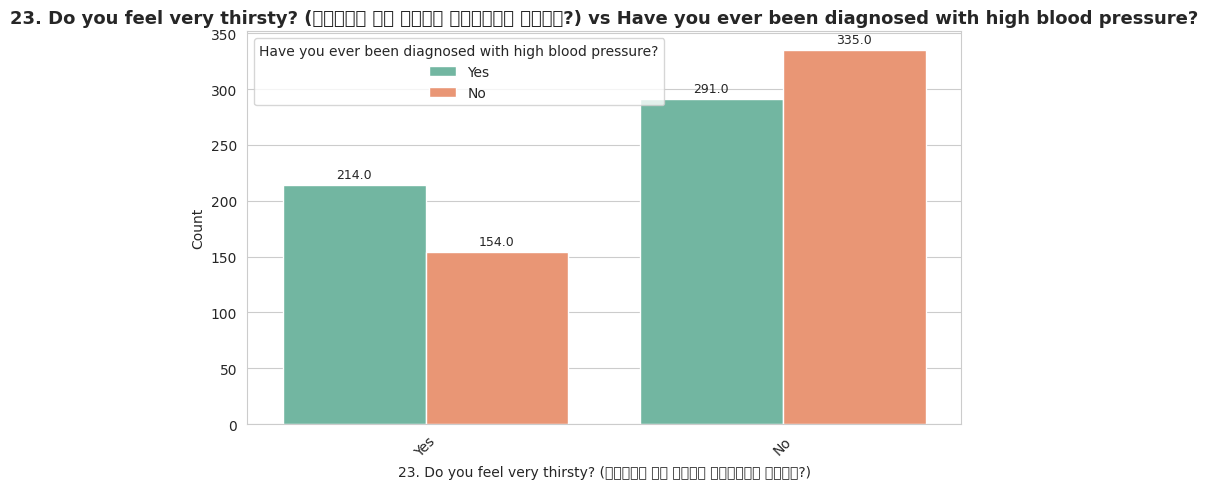

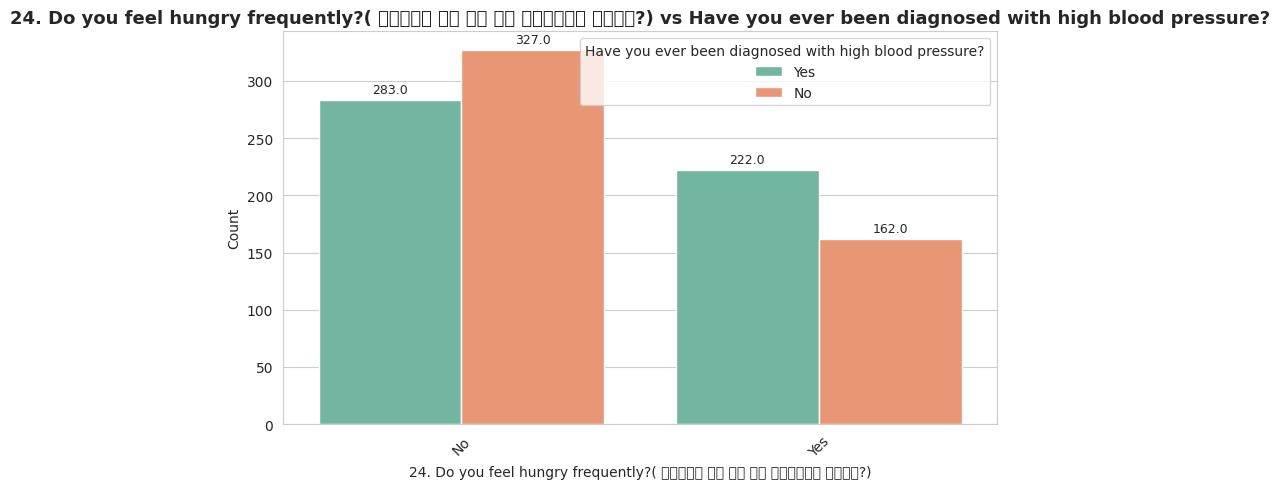

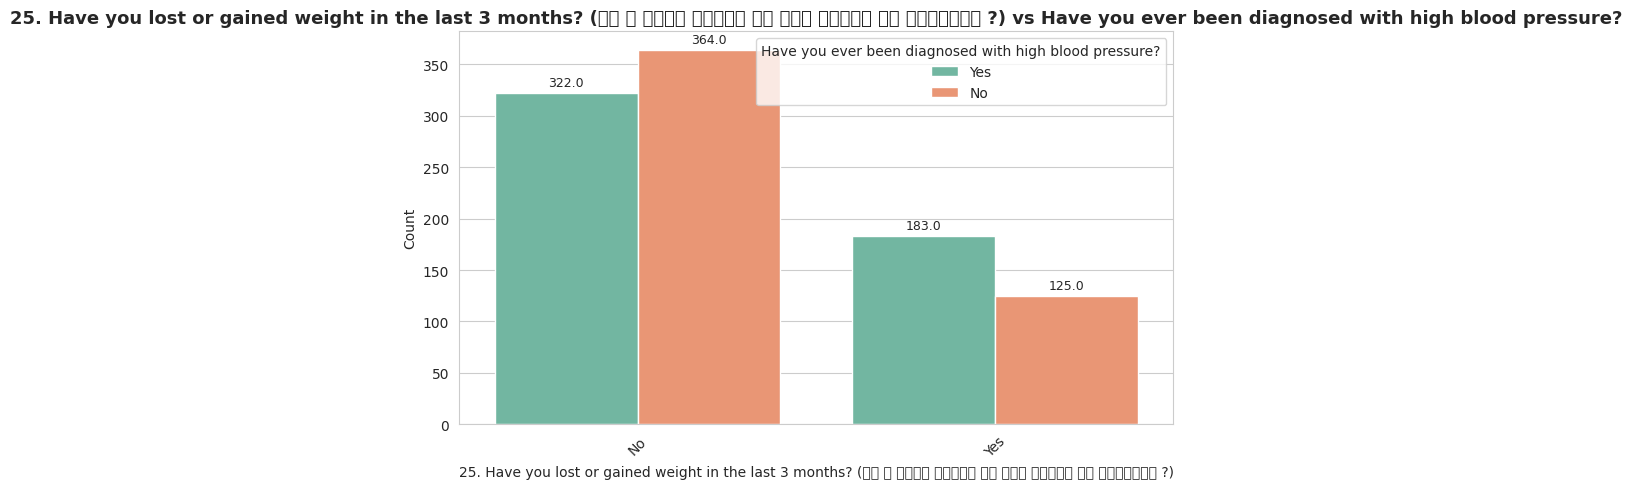

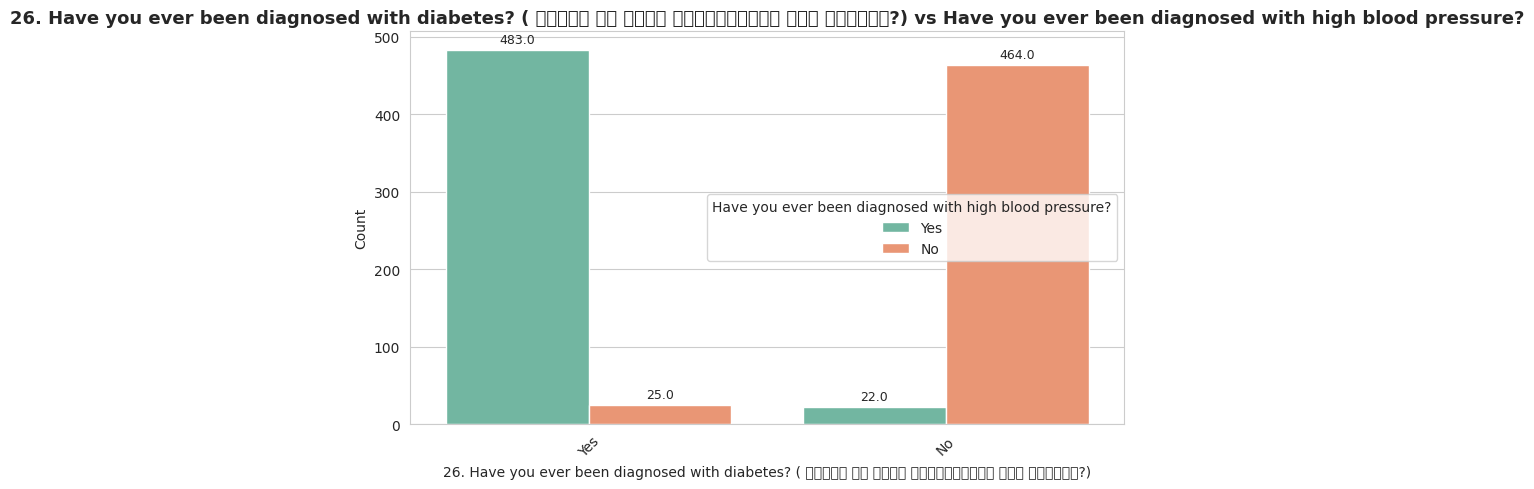

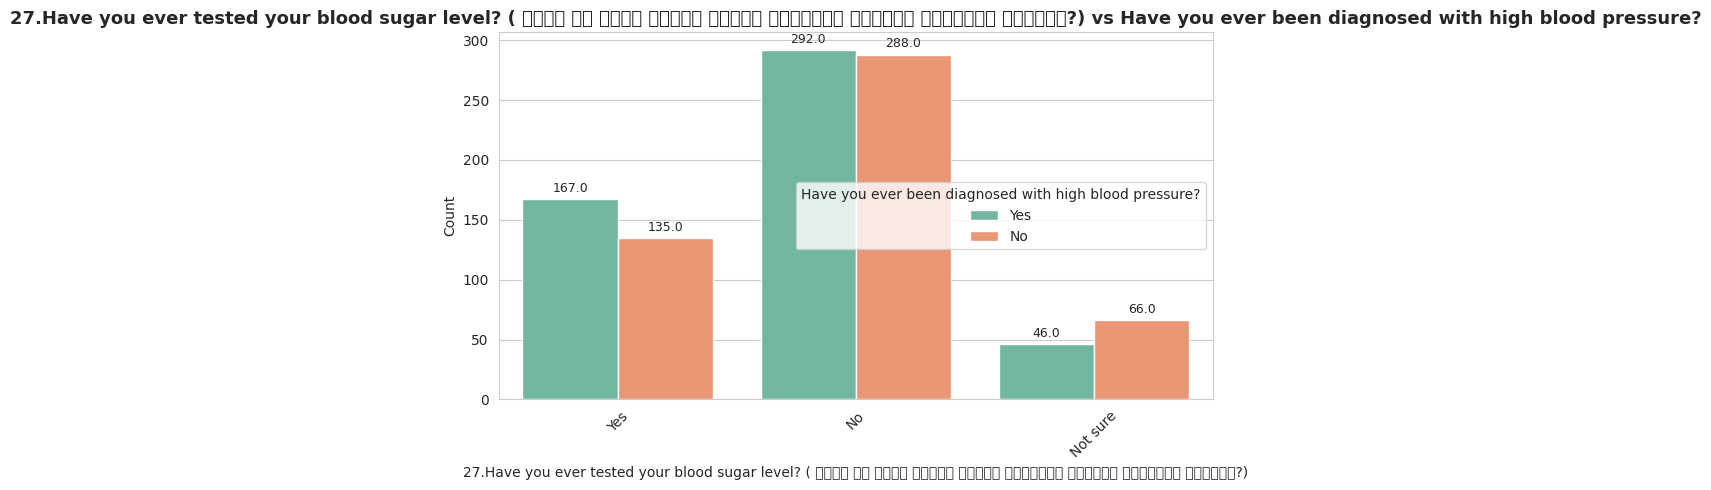

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

for col in categorical_cols:
    plt.figure(figsize=(8,5))

    ax = sns.countplot(
        x=col,
        hue='17. Have you ever been diagnosed with high blood pressure? ( আপনার কি কখনো উচ্চ রক্তচাপ ধরা পড়েছে? )',
        data=df,
        palette="Set2"
    )

    # Add count labels on top
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(
                f'{height}',  # <-- just the count
                (p.get_x() + p.get_width()/2., height),
                ha='center',
                va='bottom',
                fontsize=9,
                xytext=(0,3),
                textcoords='offset points'
            )

    plt.xticks(rotation=45)
    plt.title(f"{col} vs Have you ever been diagnosed with high blood pressure?", fontsize=13, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.legend(title="Have you ever been diagnosed with high blood pressure?")

    plt.tight_layout()
    plt.show()


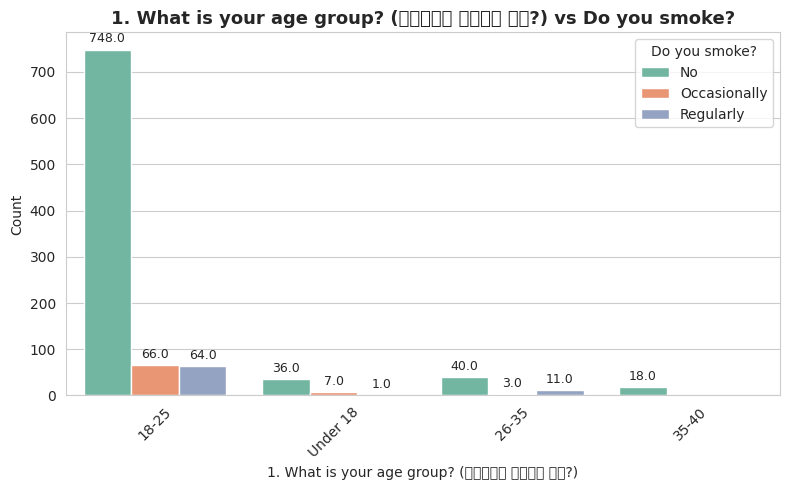

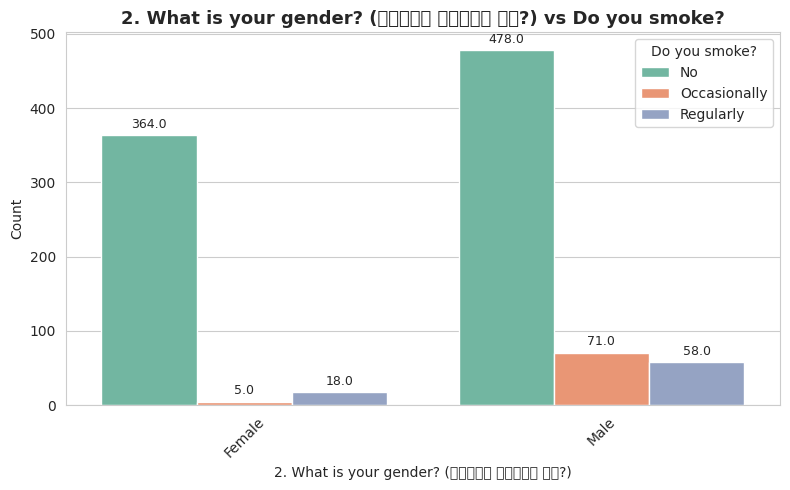

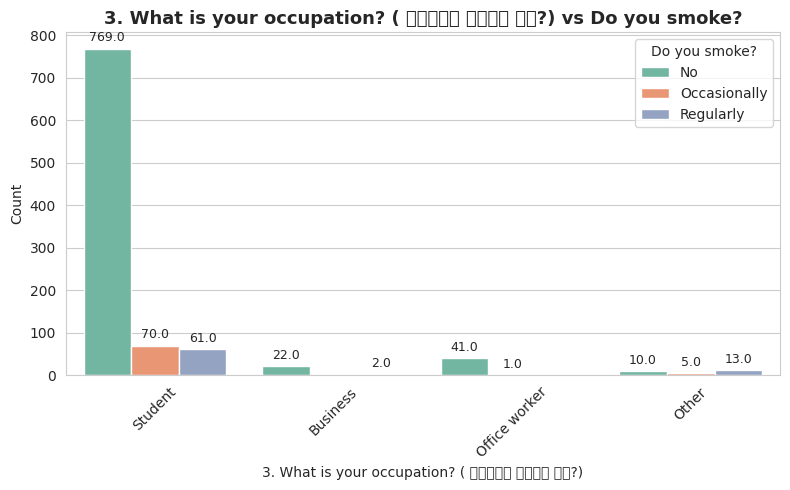

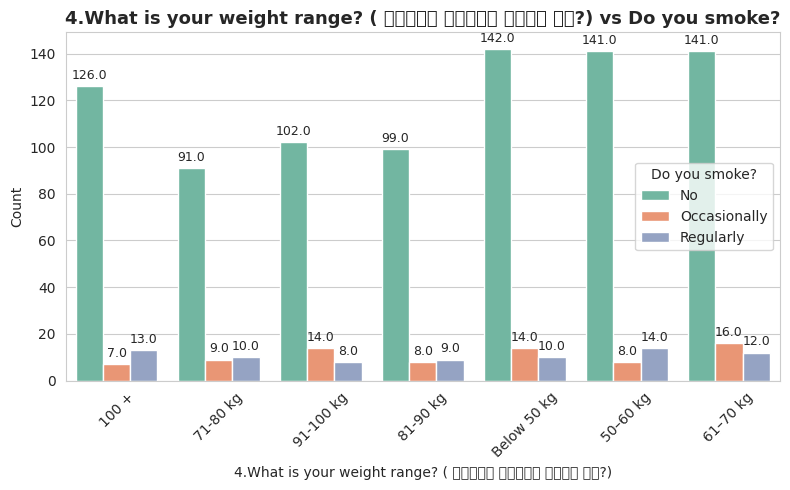

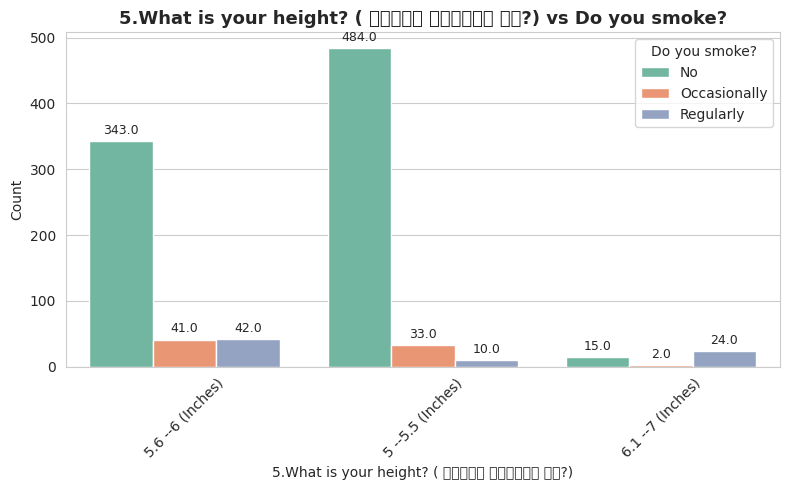

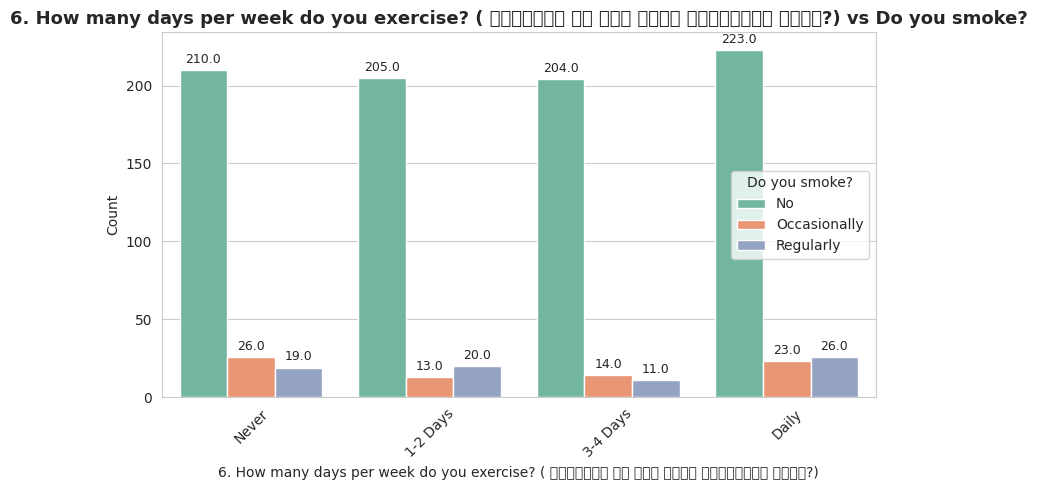

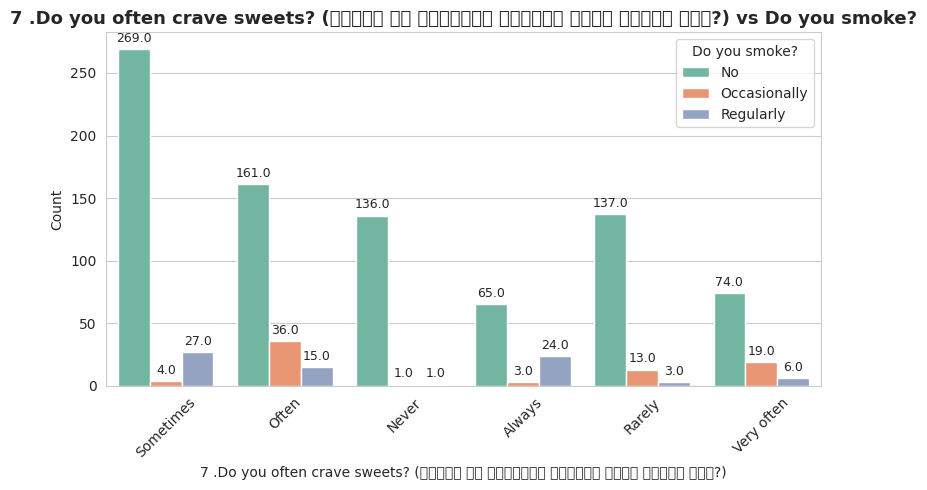

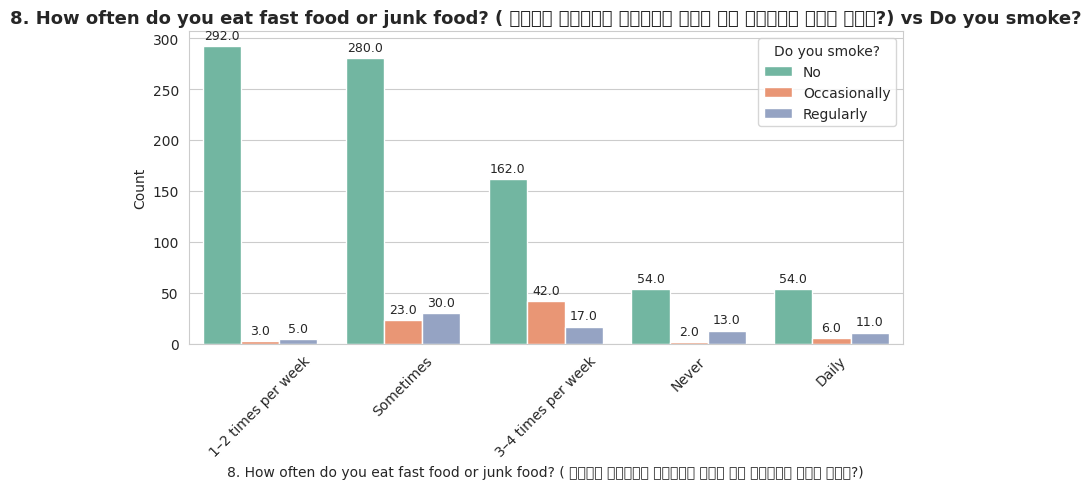

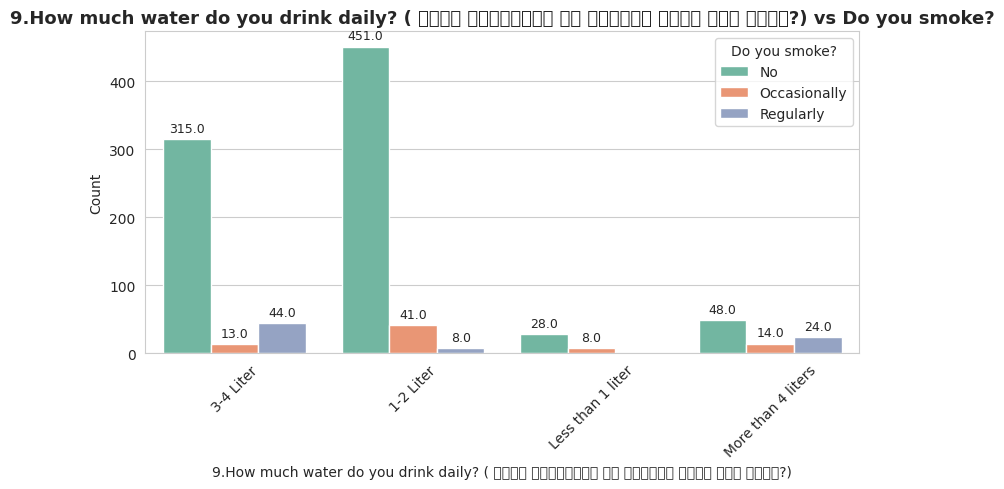

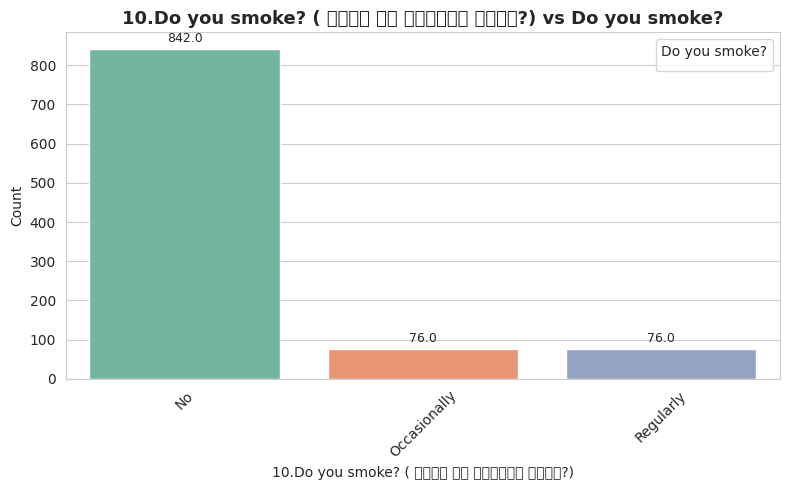

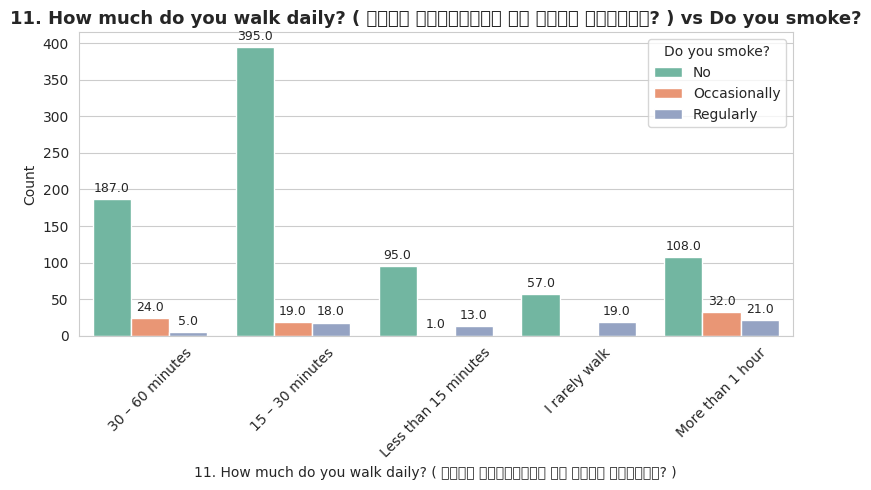

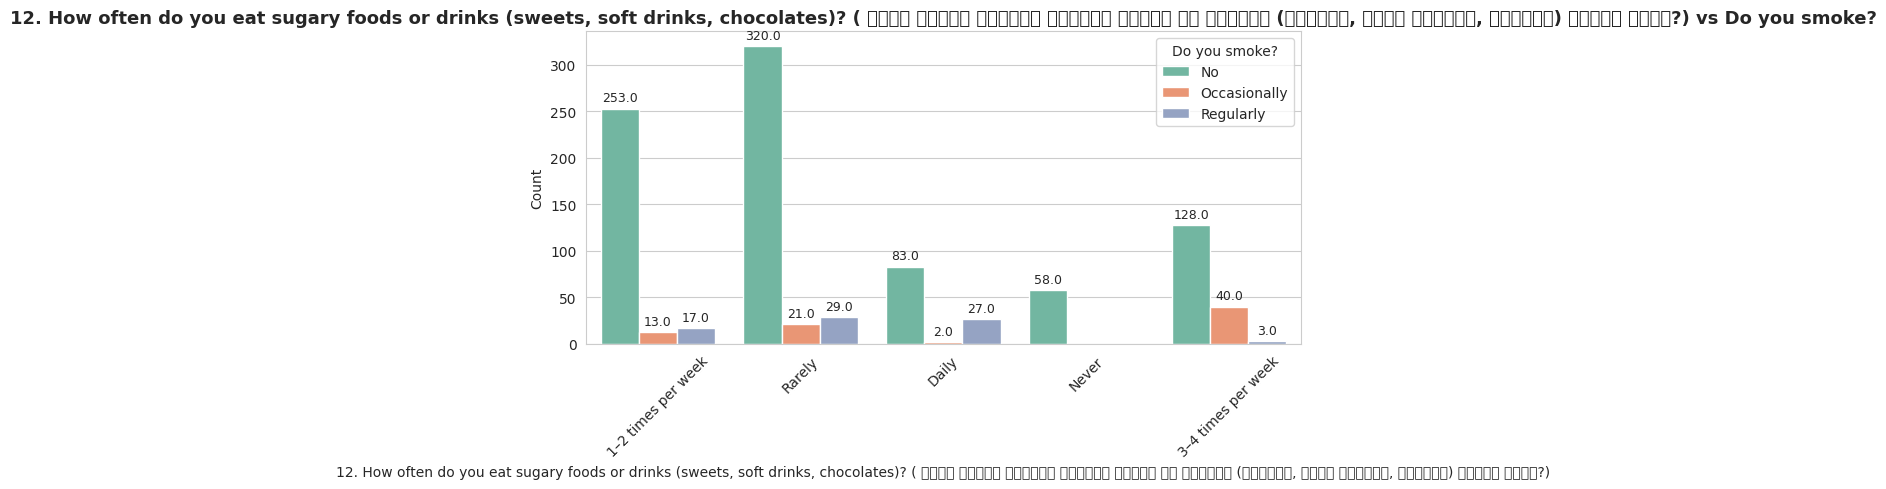

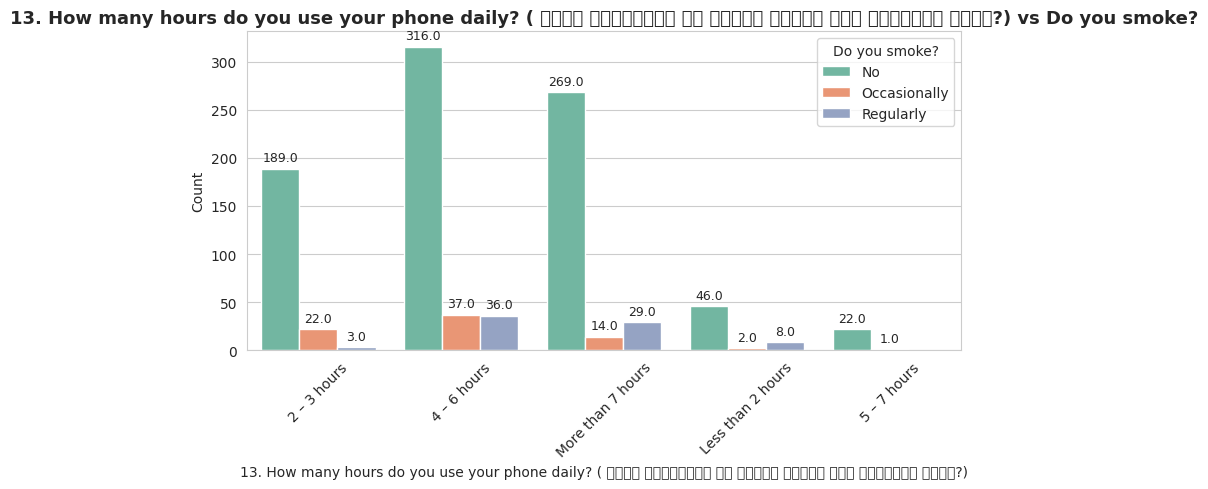

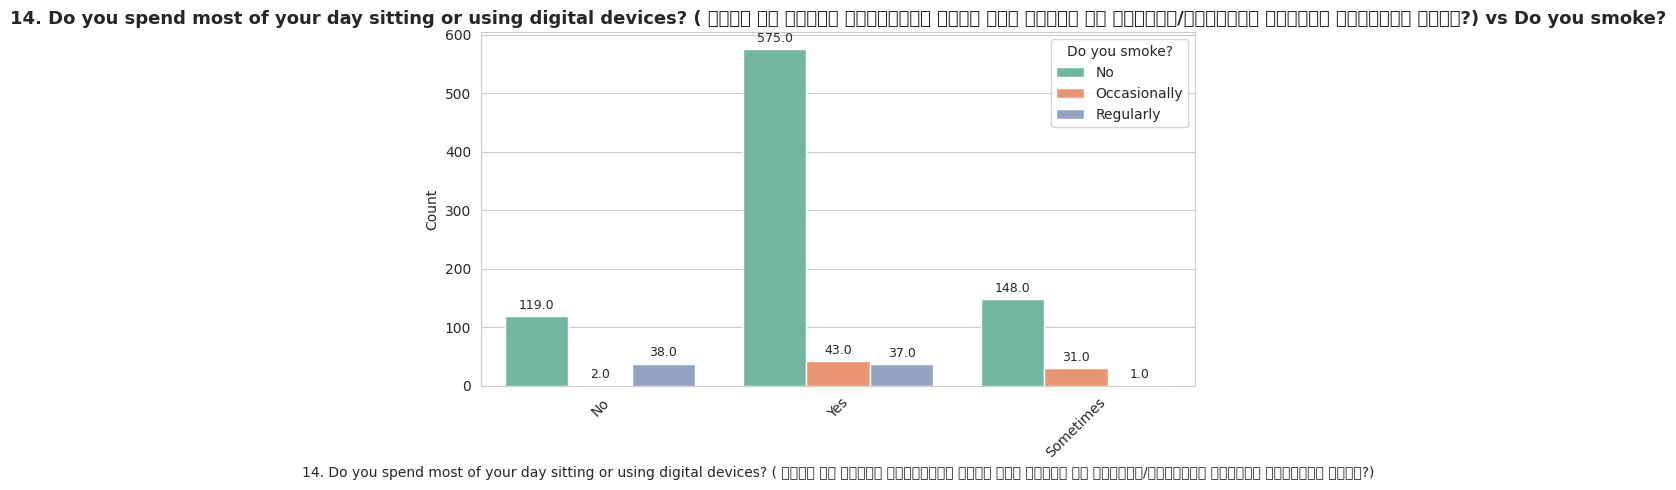

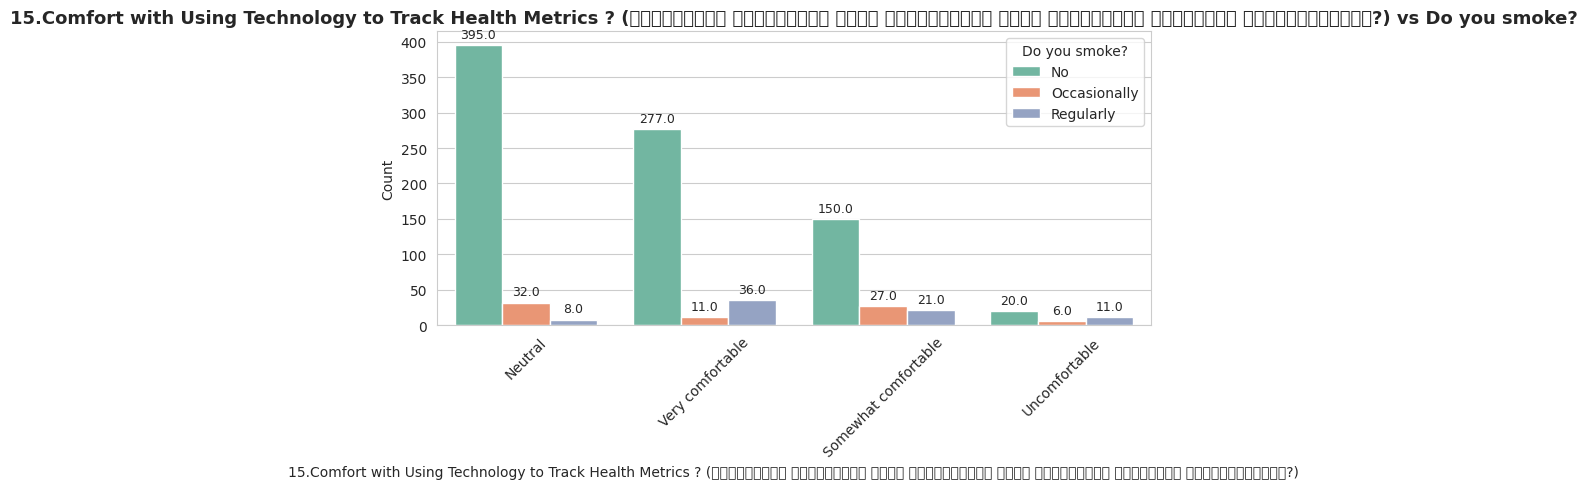

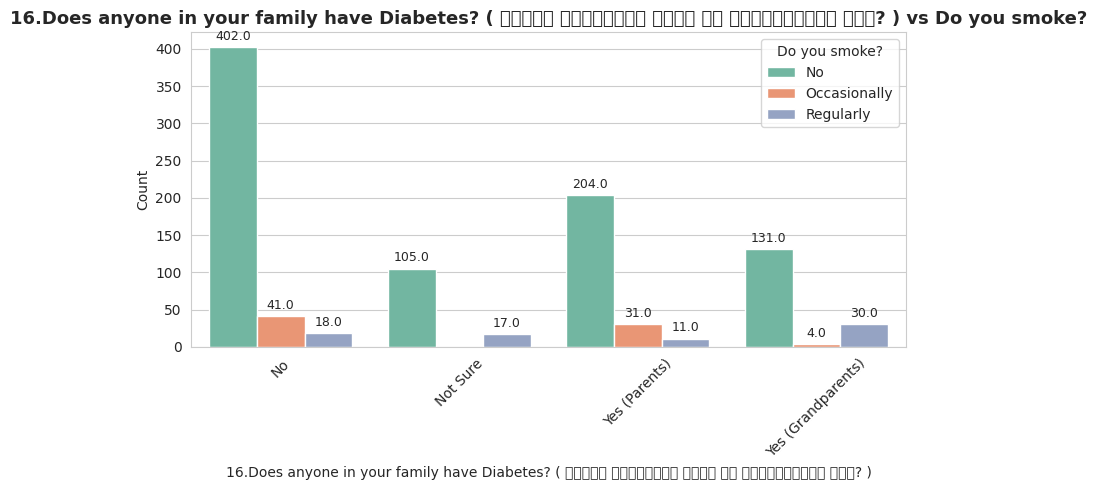

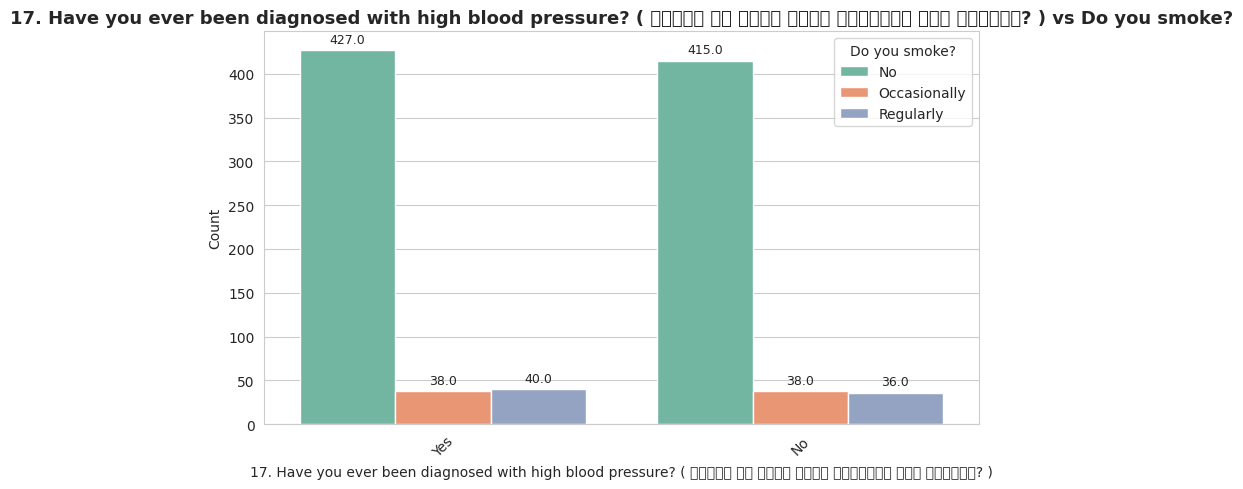

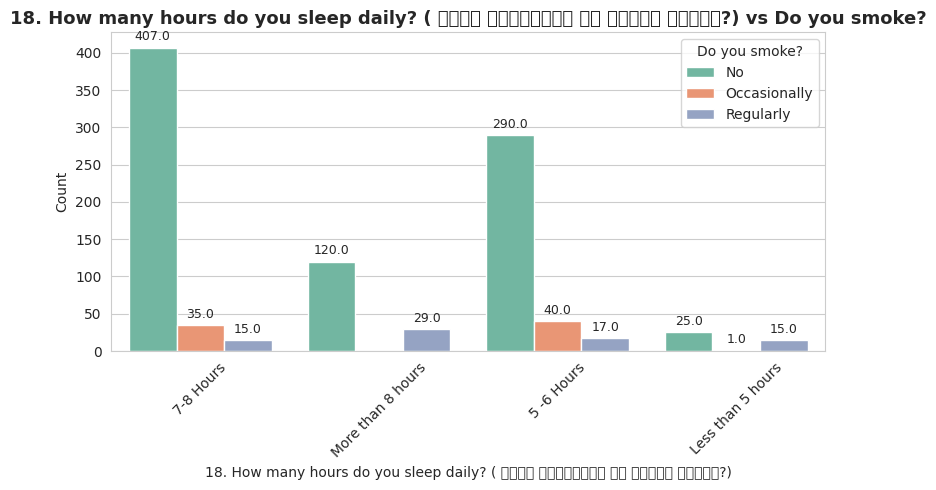

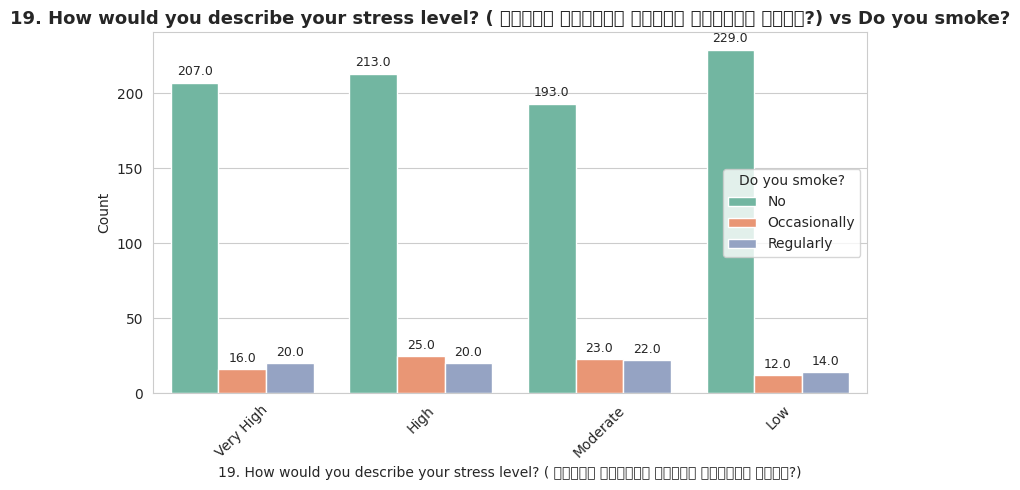

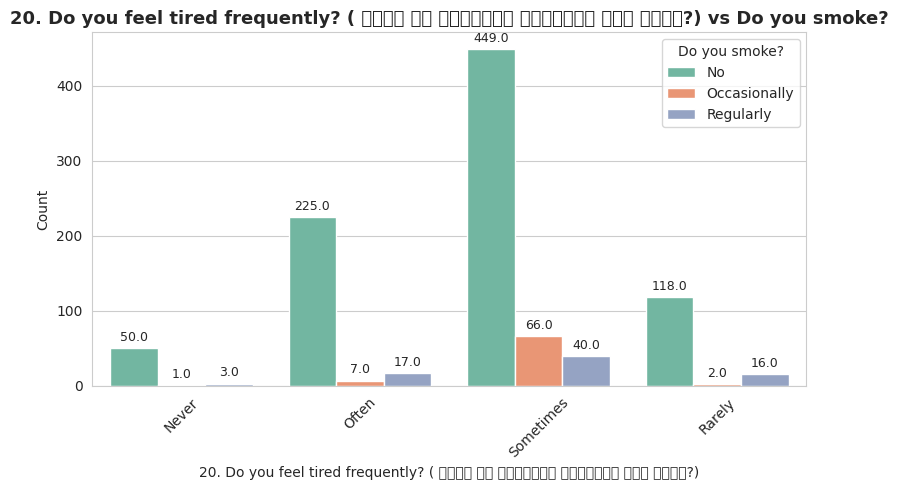

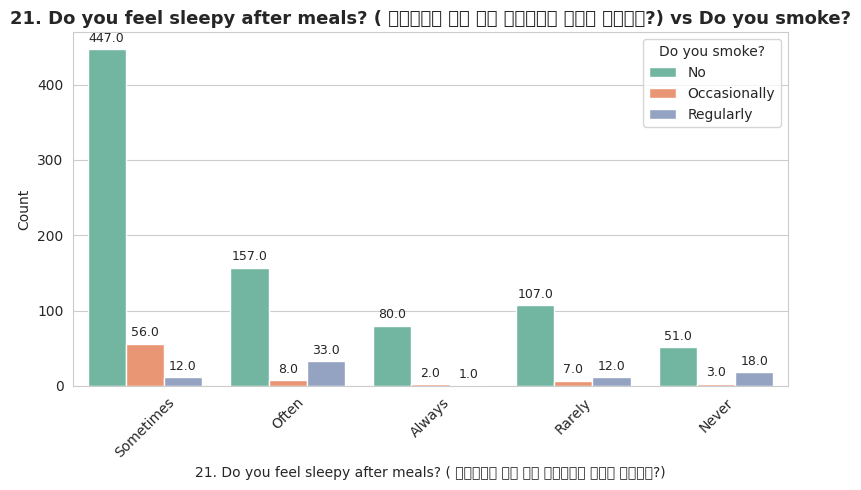

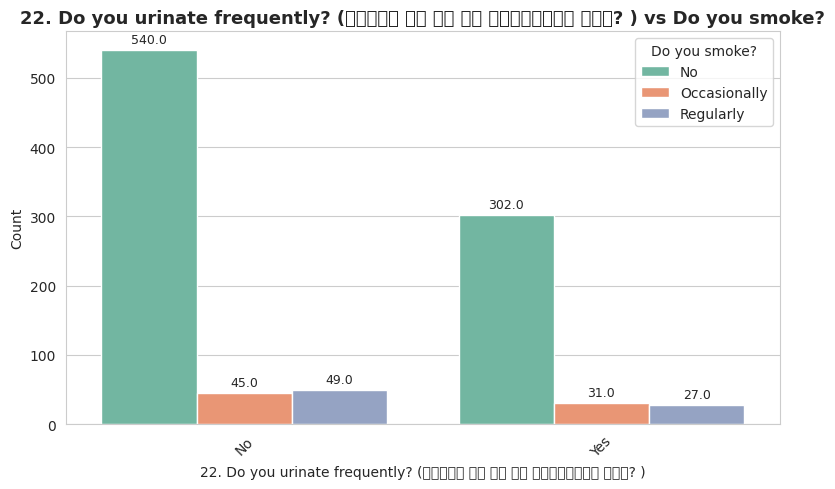

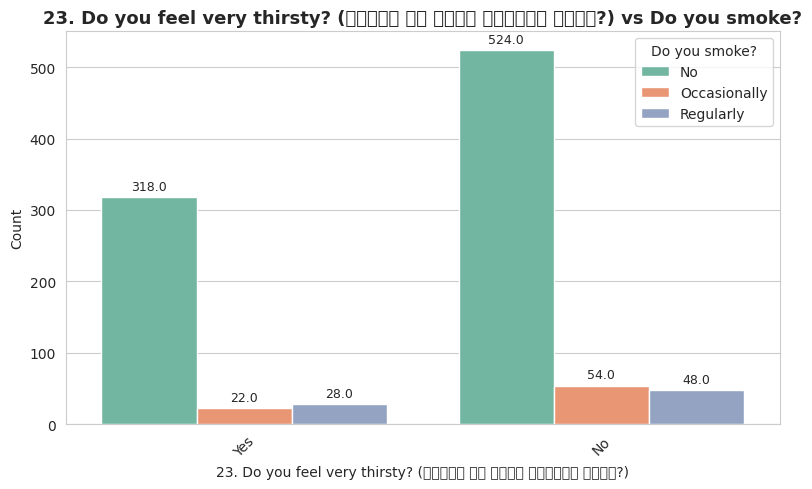

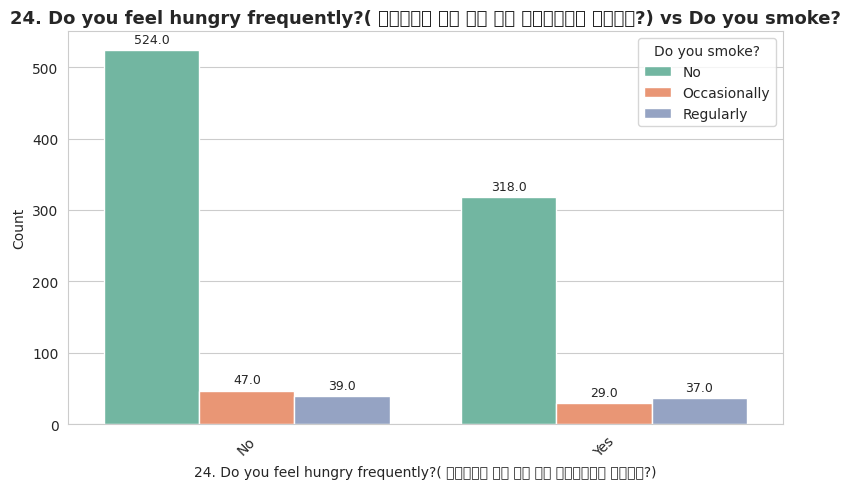

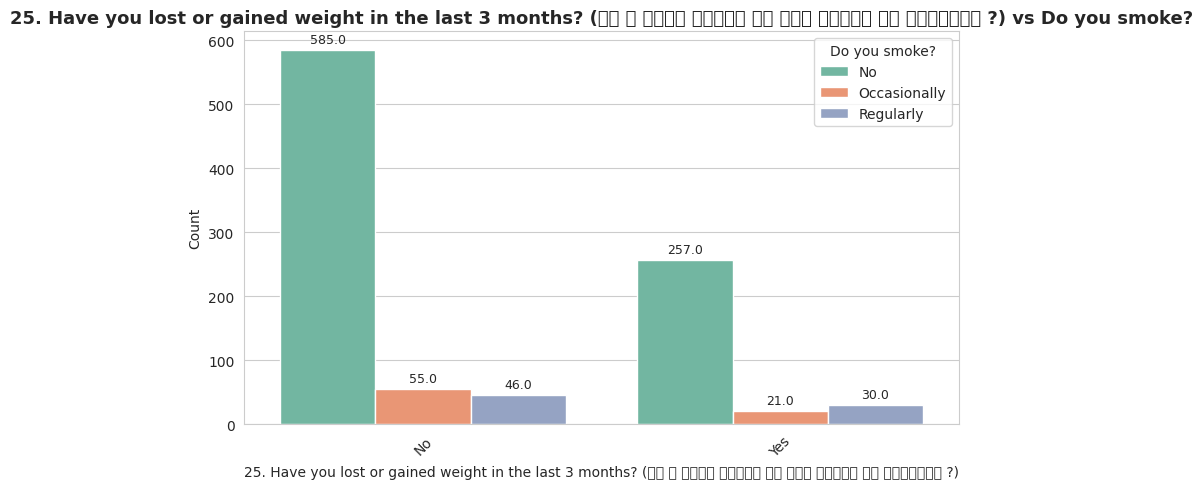

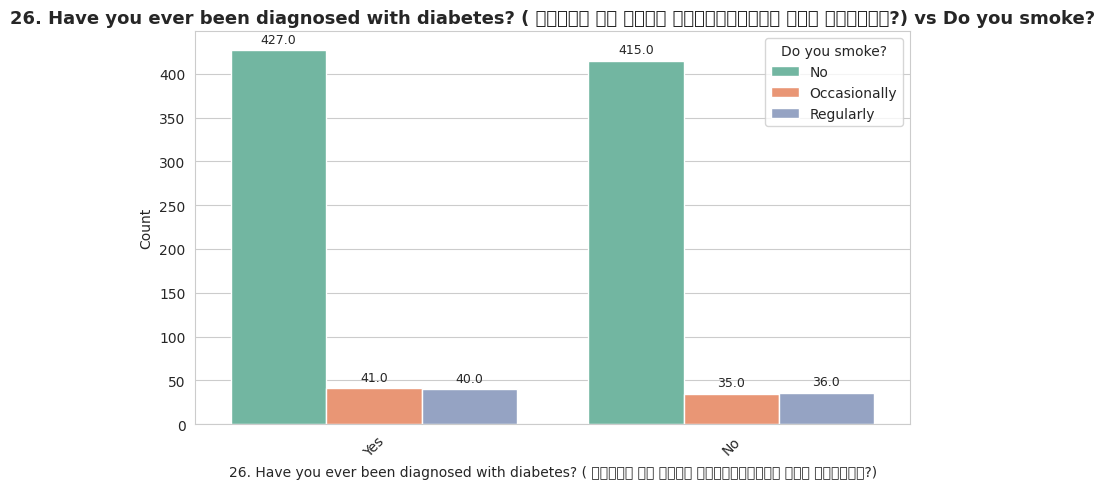

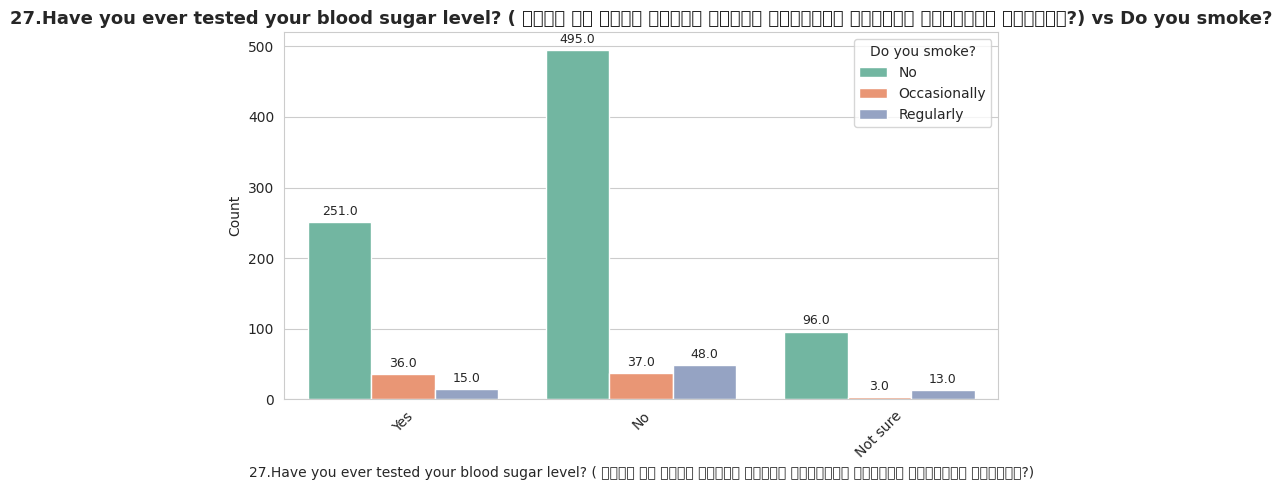

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

for col in categorical_cols:
    plt.figure(figsize=(8,5))

    ax = sns.countplot(
        x=col,
        hue='10.Do you smoke? ( আপনি কি ধূমপান করেন?)',
        data=df,
        palette="Set2"
    )

    # Add count labels on top
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(
                f'{height}',  # <-- just the count
                (p.get_x() + p.get_width()/2., height),
                ha='center',
                va='bottom',
                fontsize=9,
                xytext=(0,3),
                textcoords='offset points'
            )

    plt.xticks(rotation=45)
    plt.title(f"{col} vs Do you smoke?", fontsize=13, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.legend(title="Do you smoke?")

    plt.tight_layout()
    plt.show()


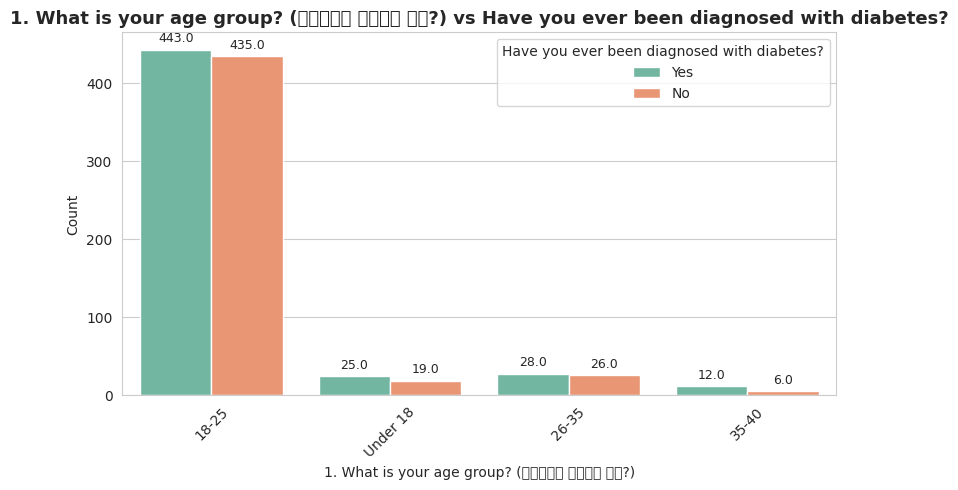

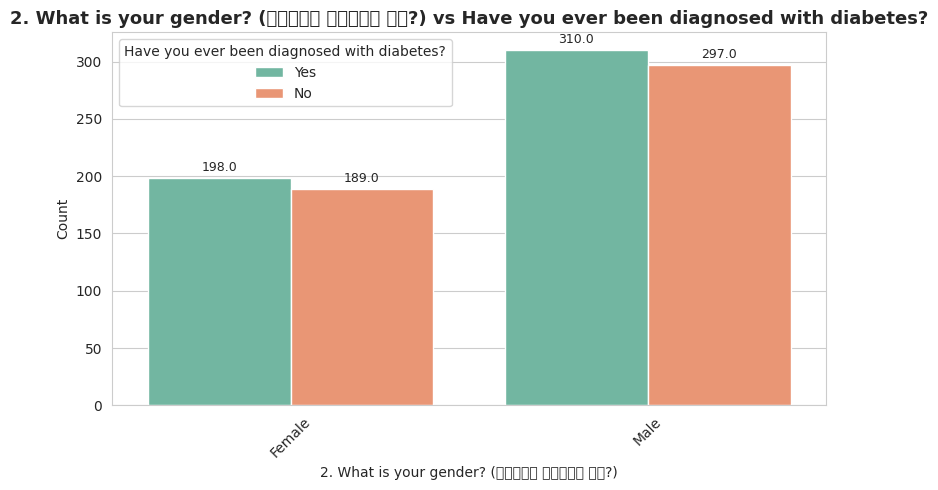

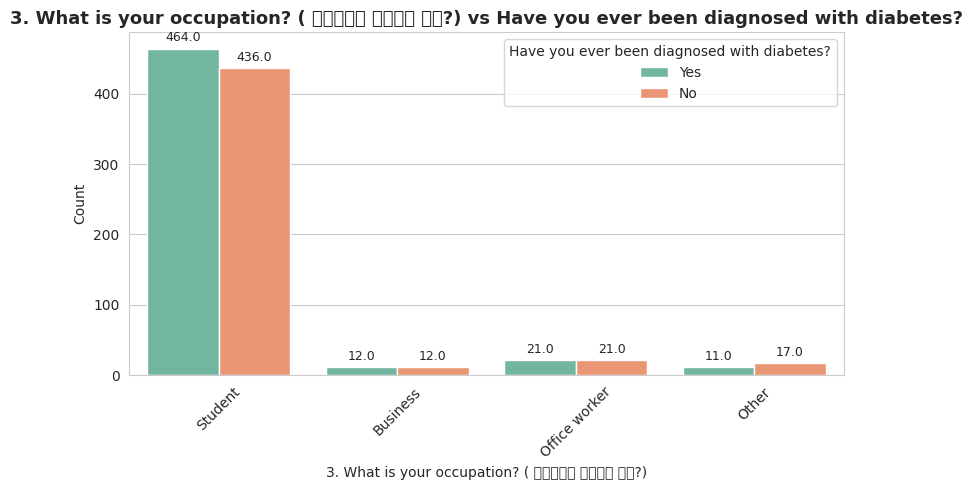

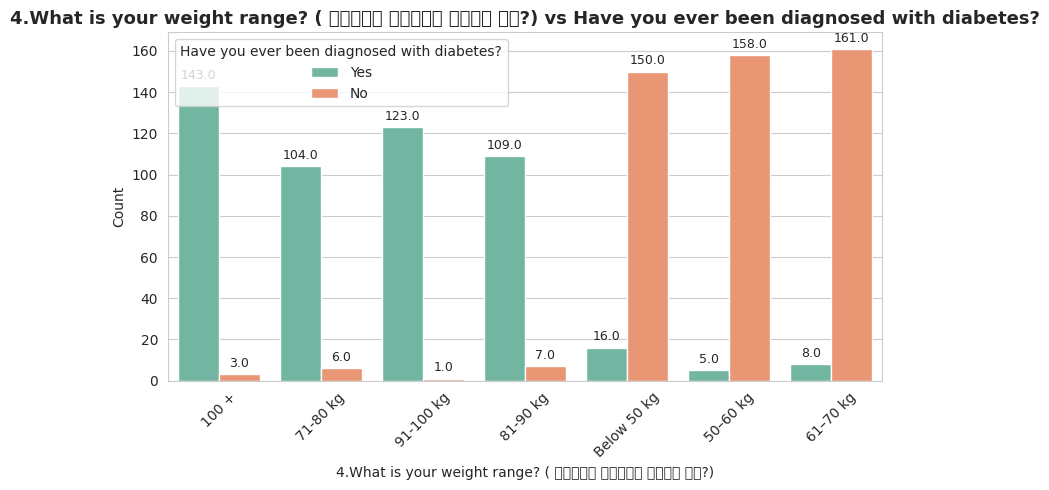

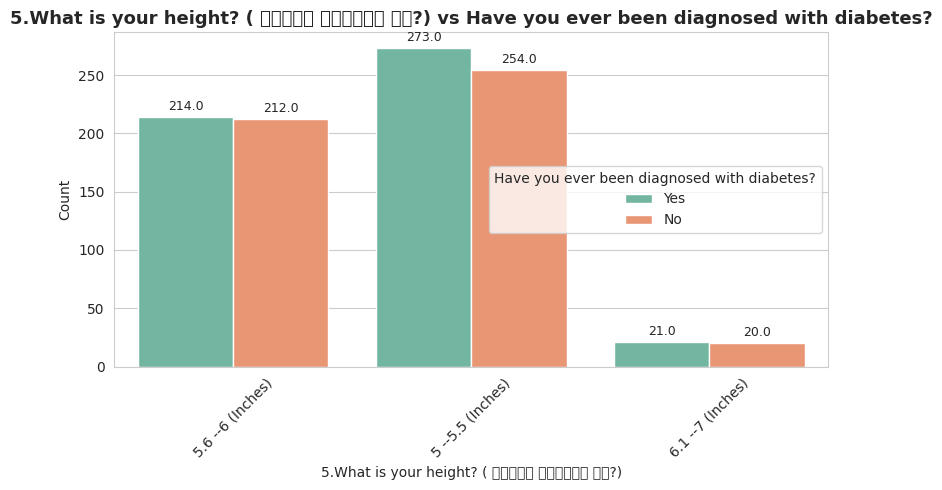

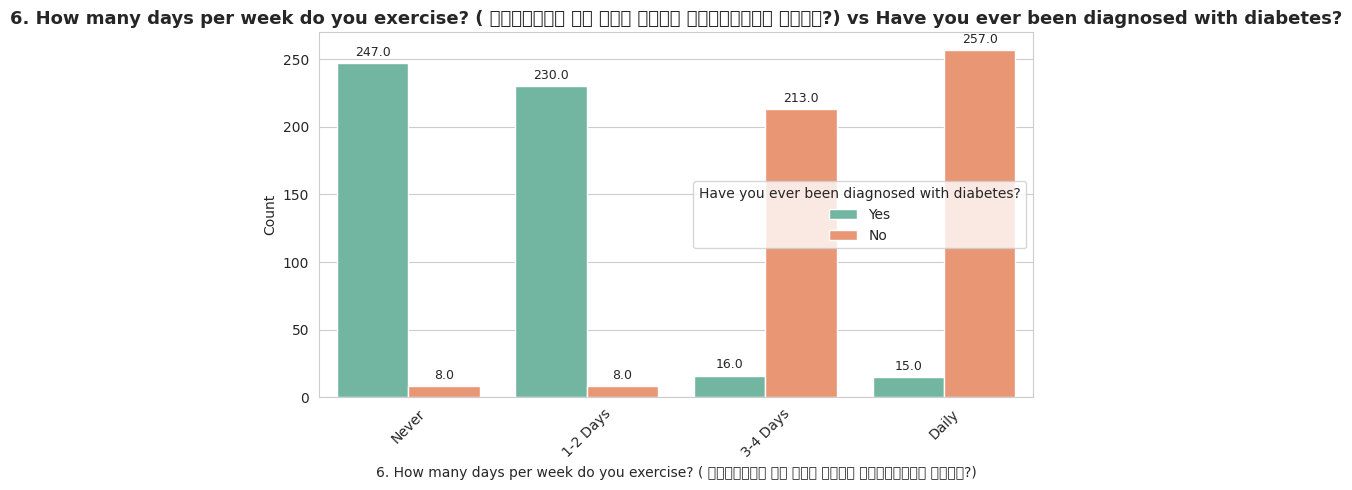

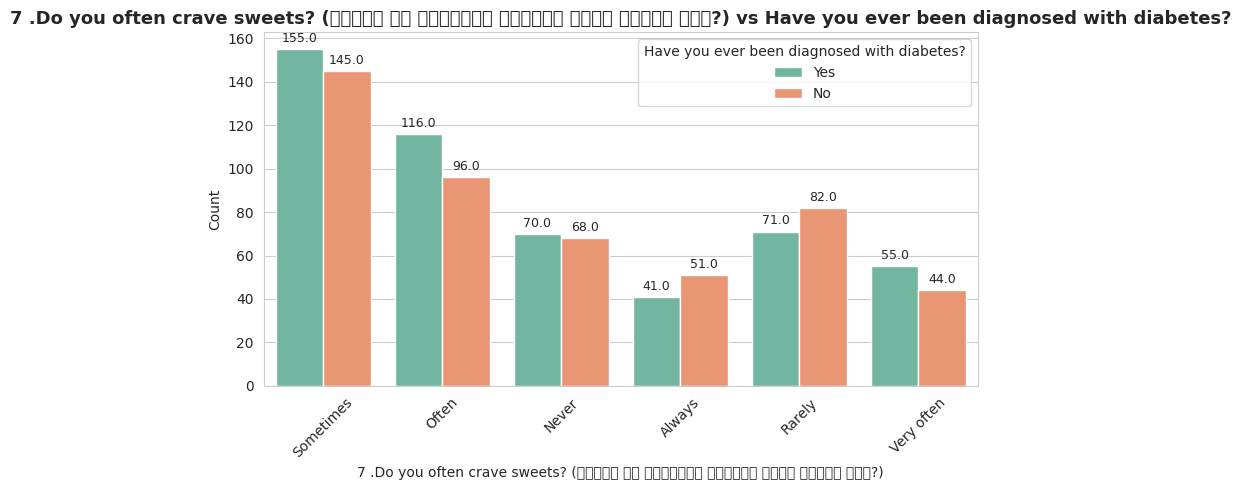

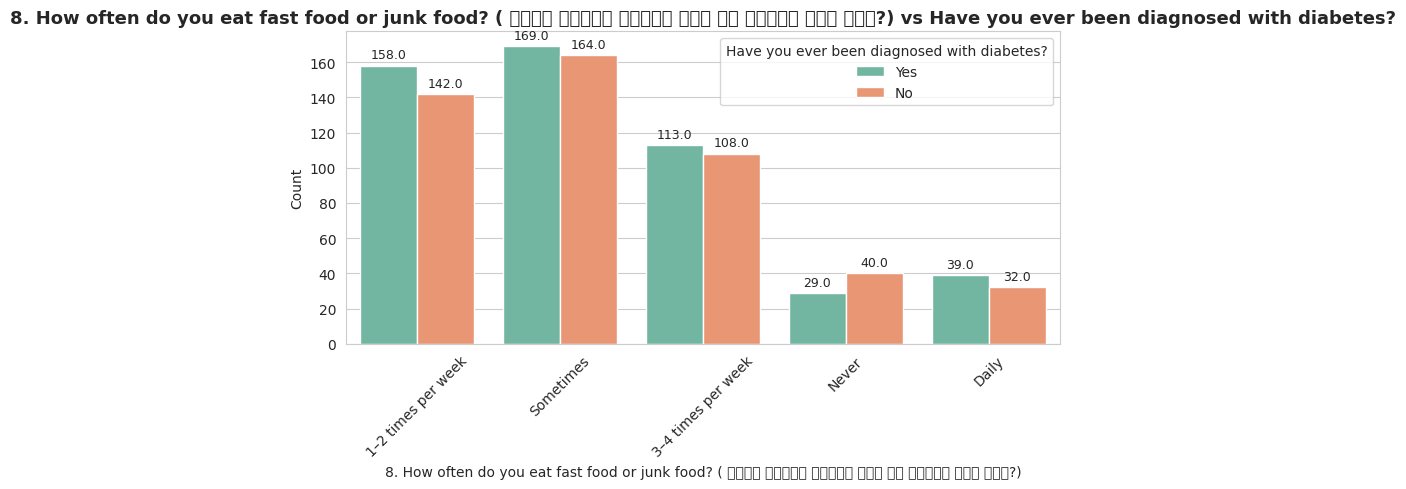

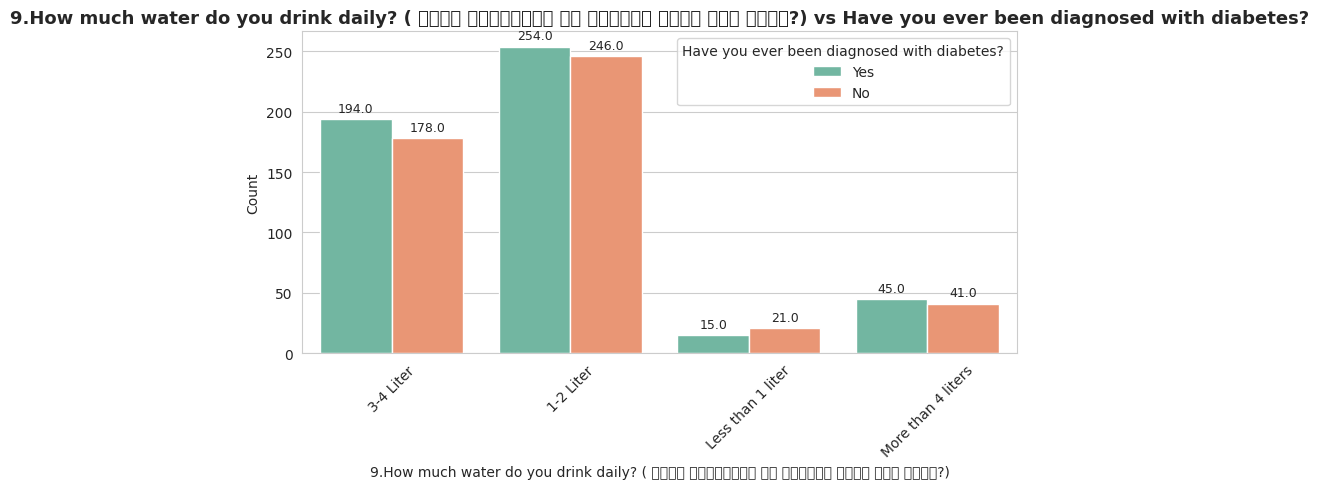

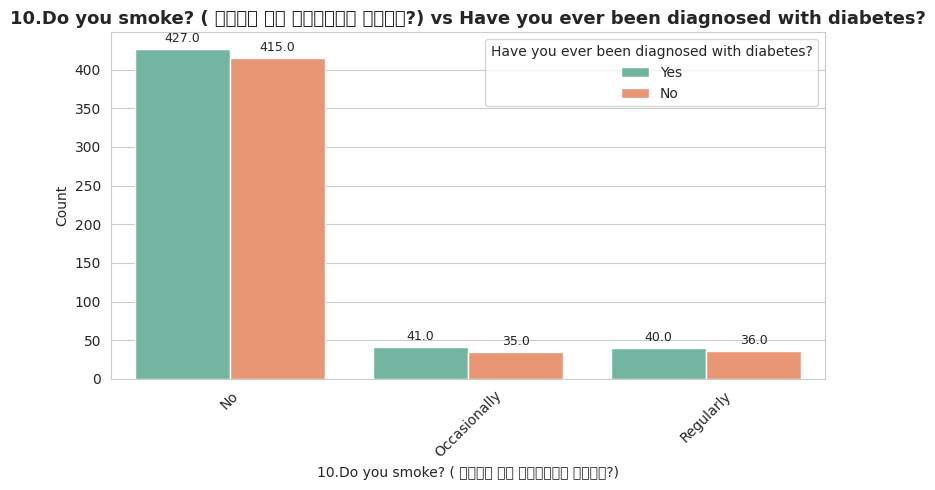

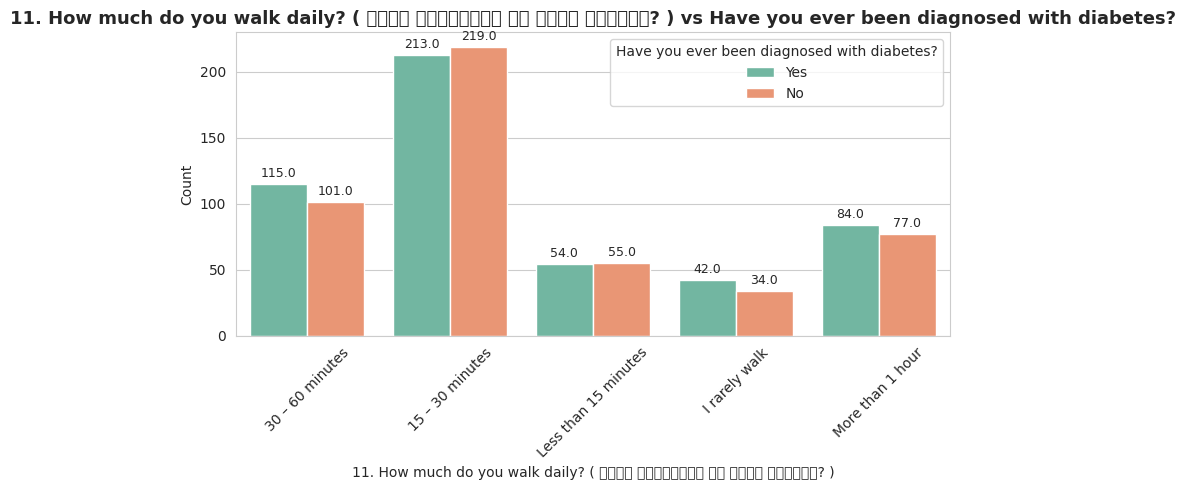

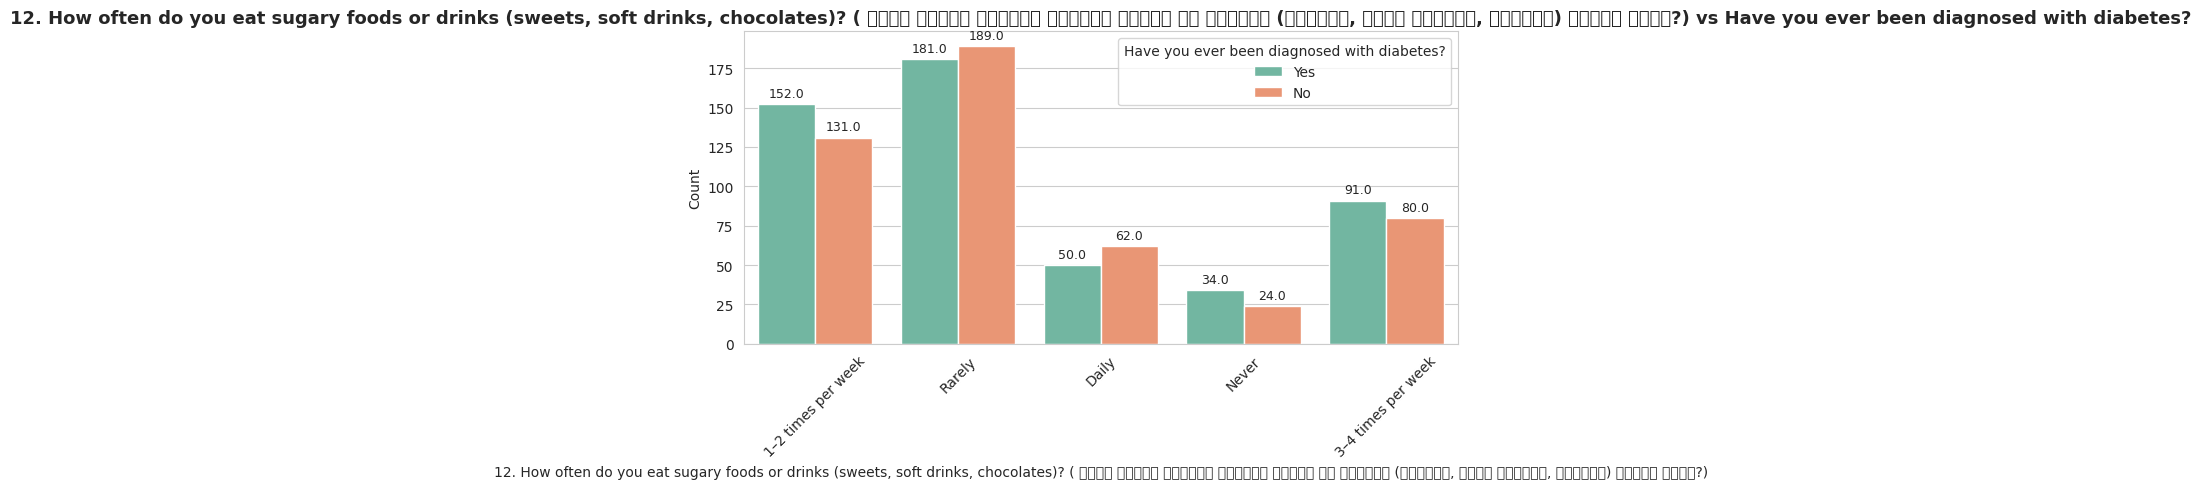

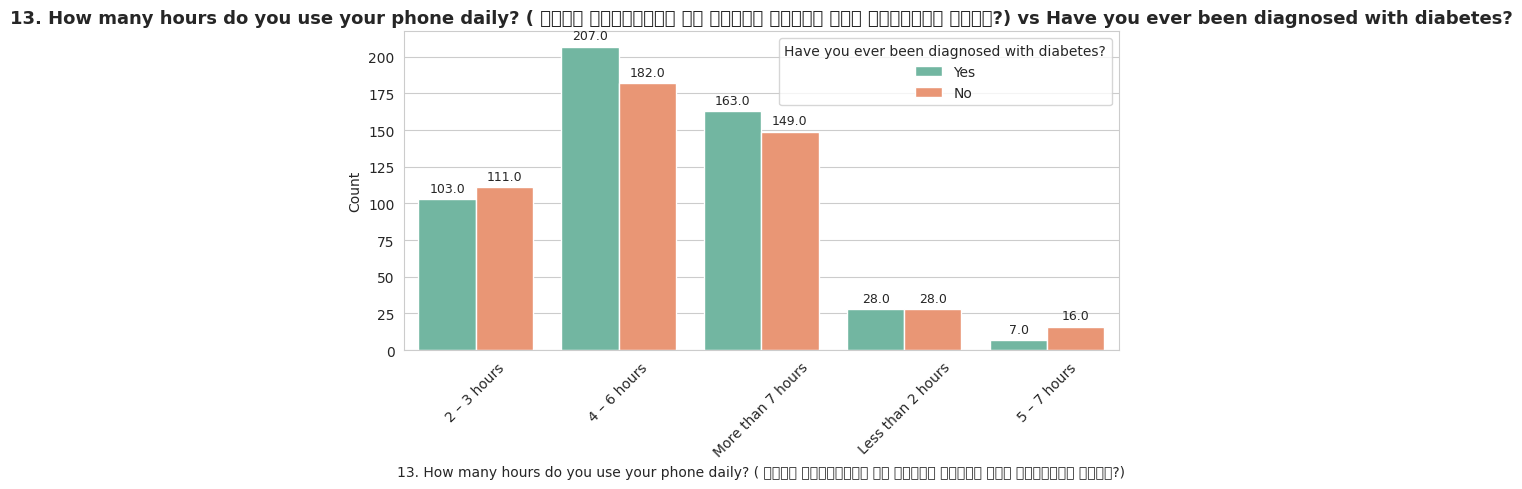

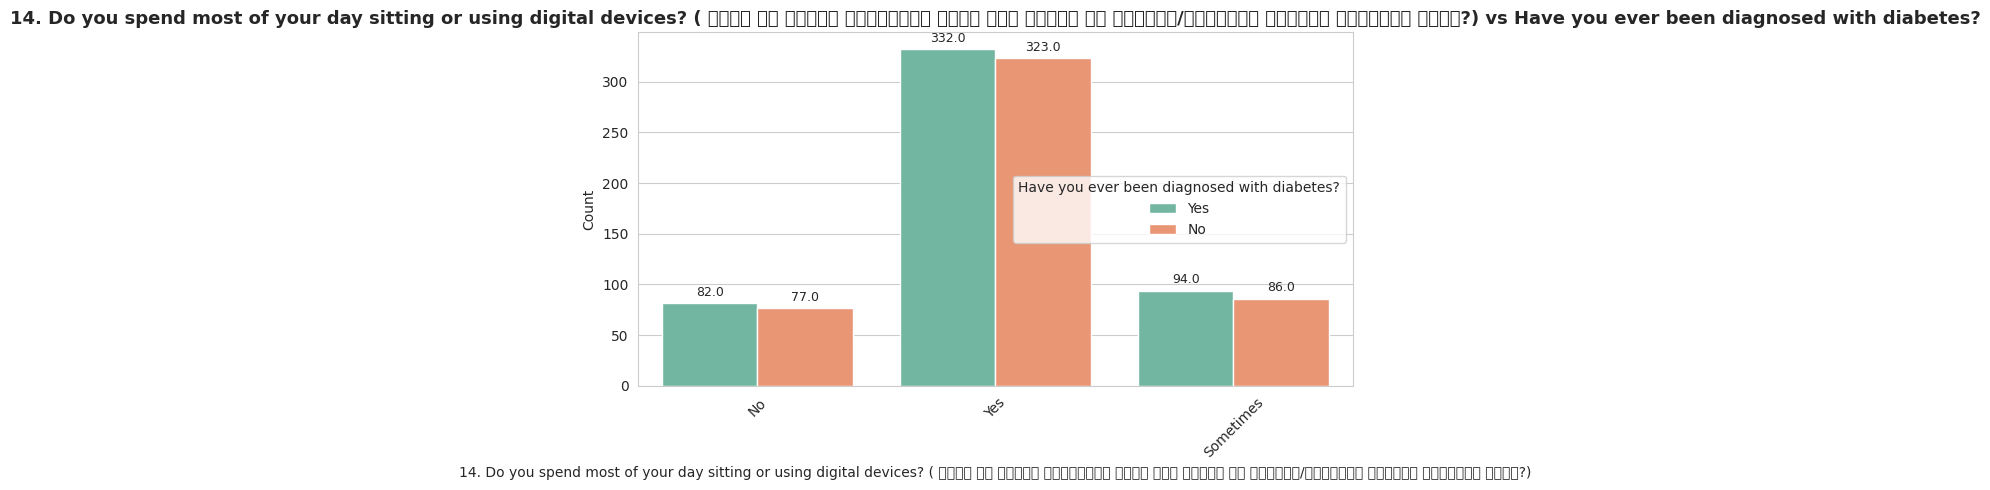

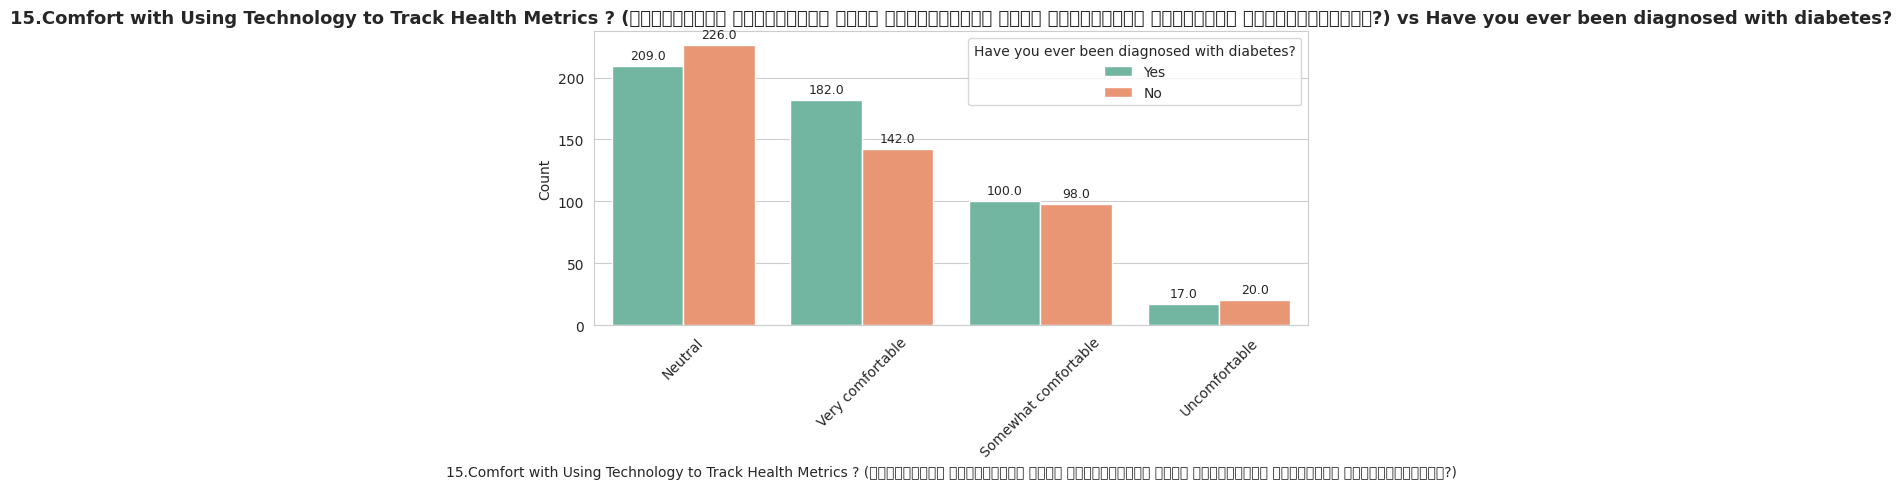

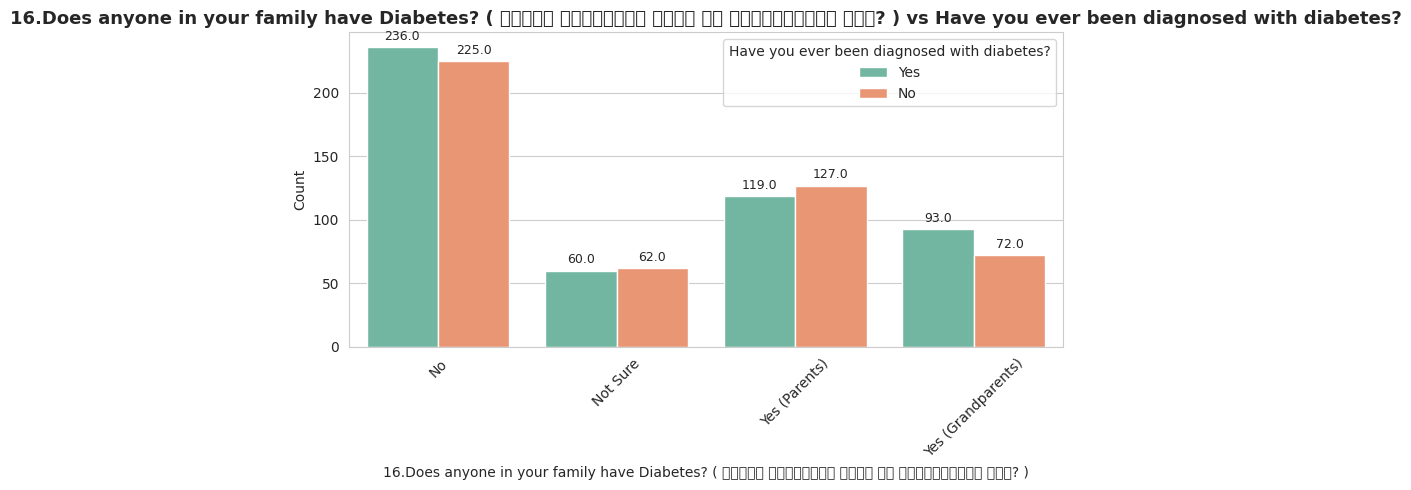

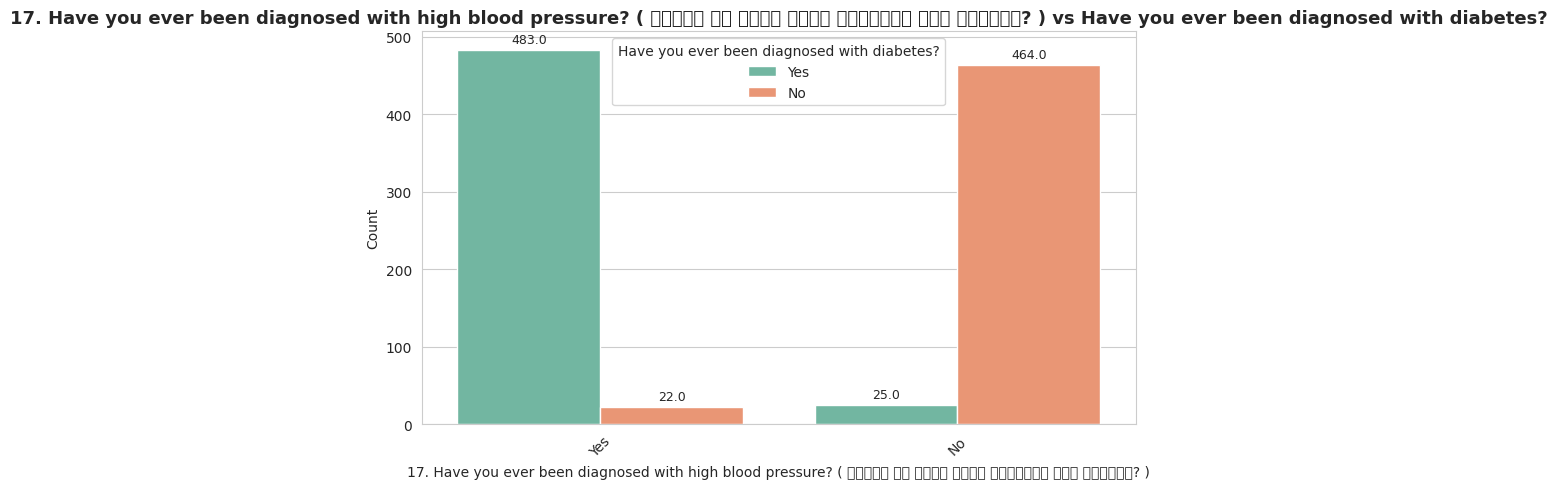

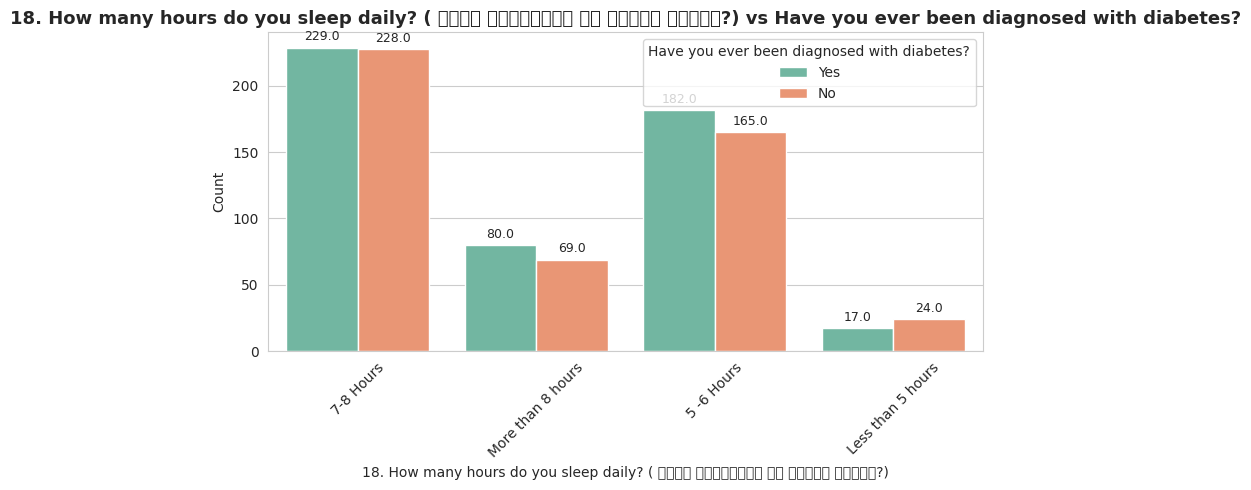

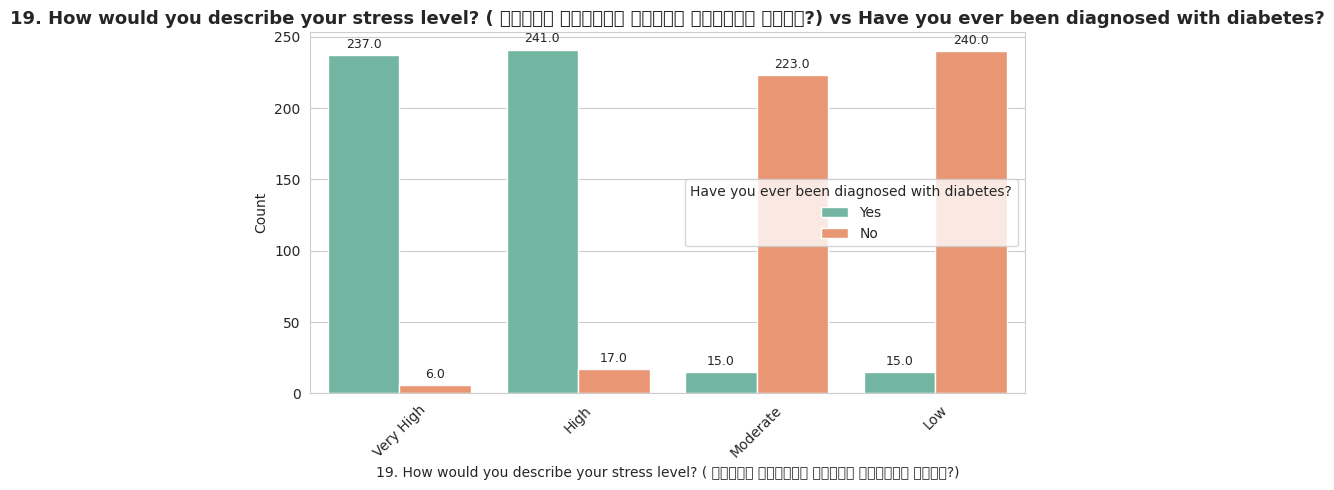

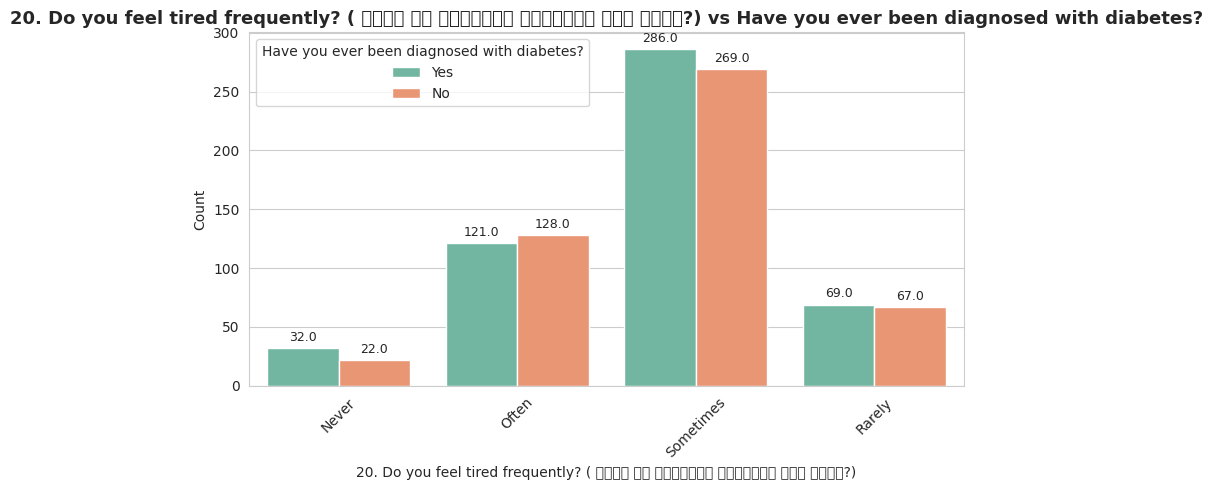

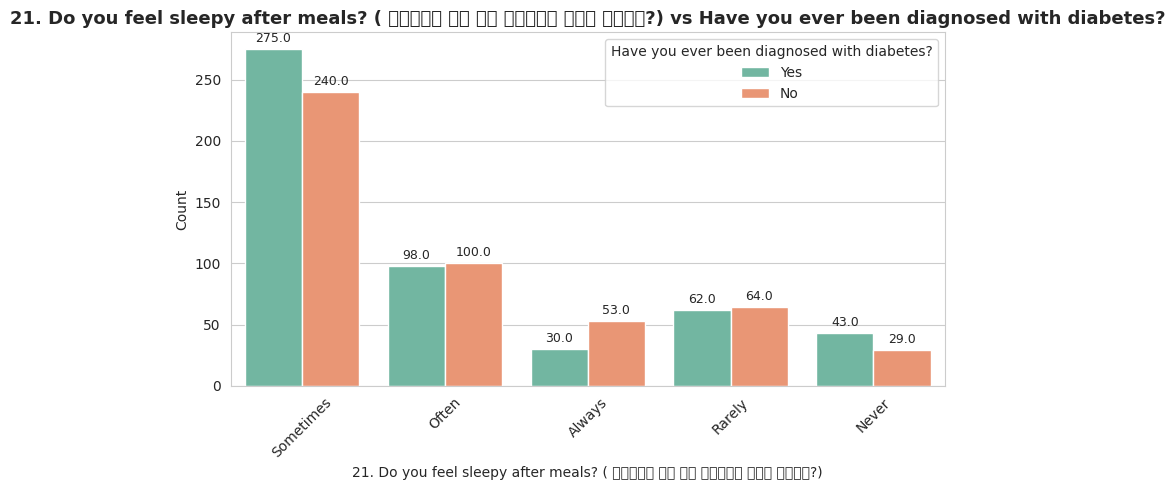

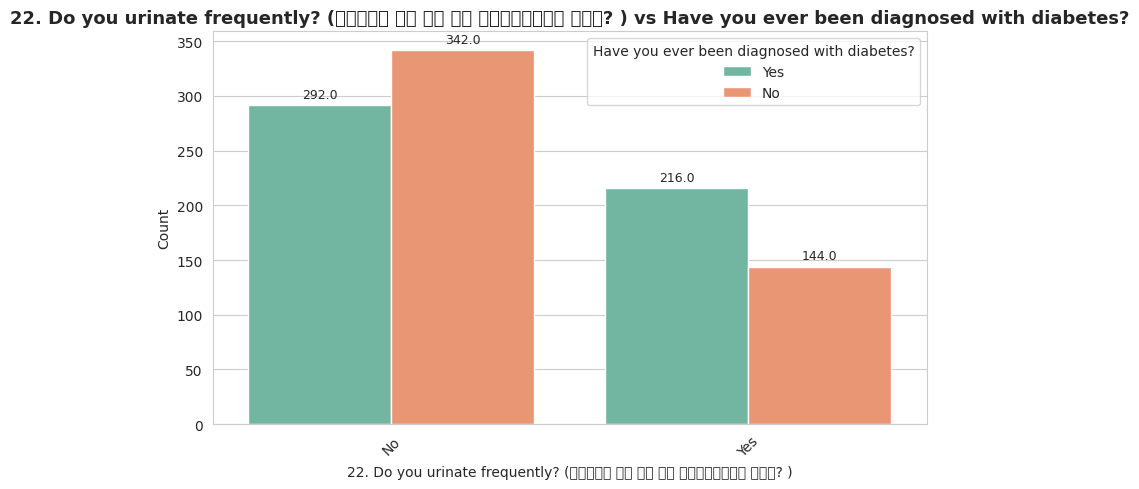

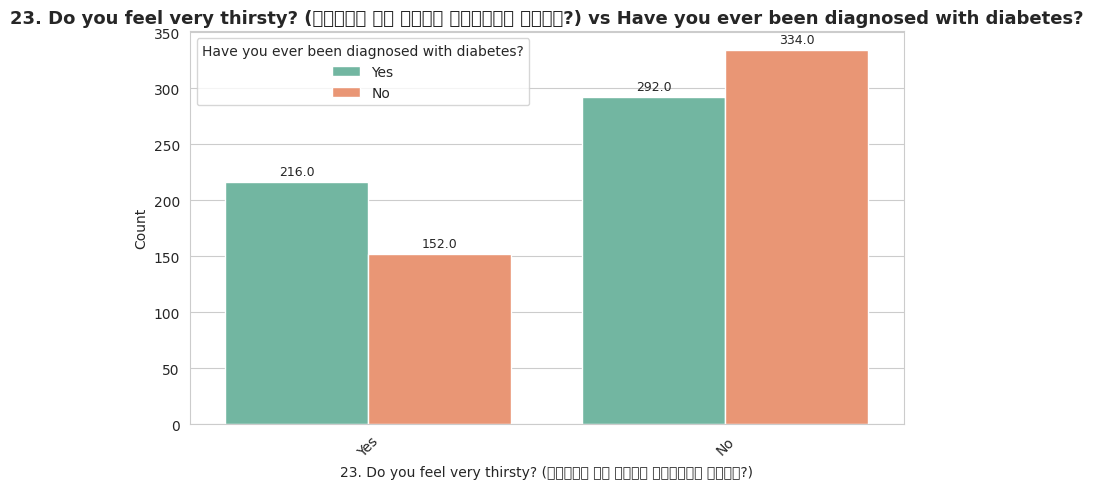

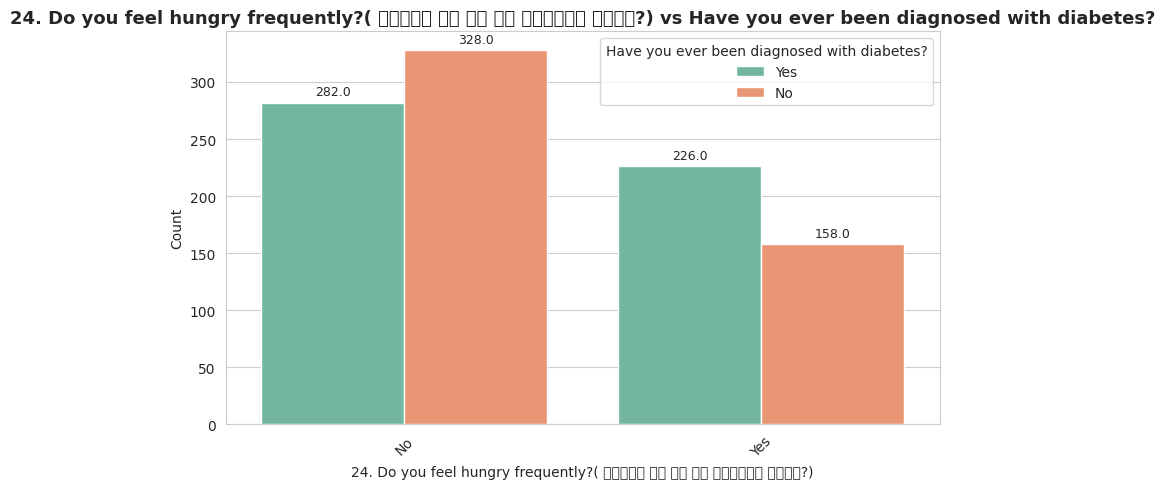

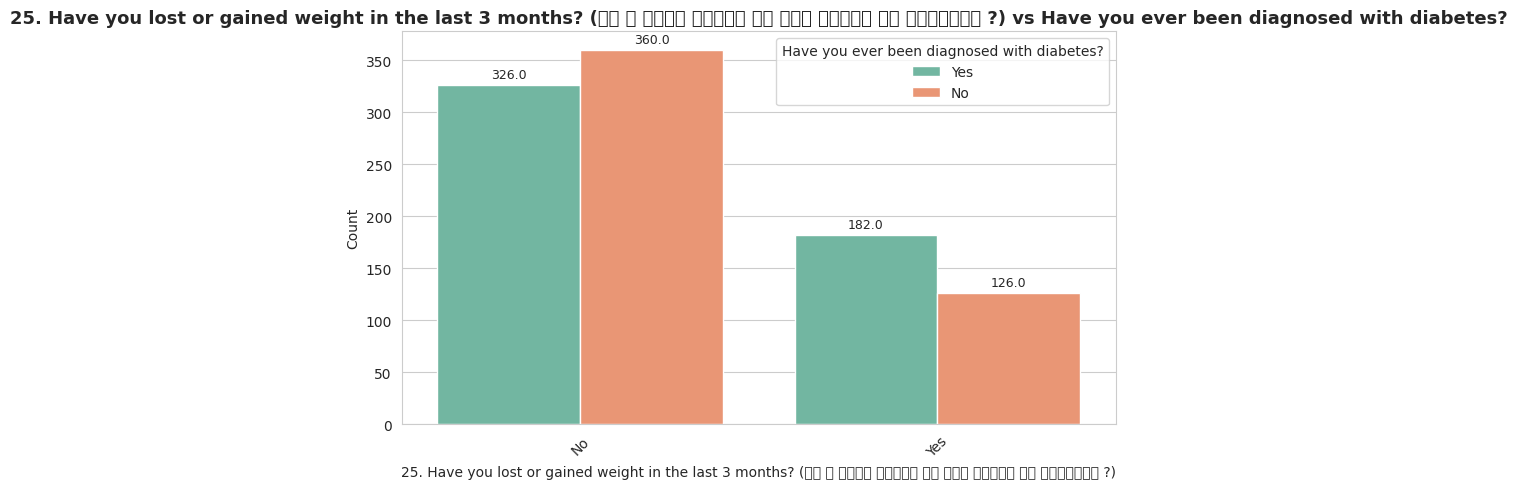

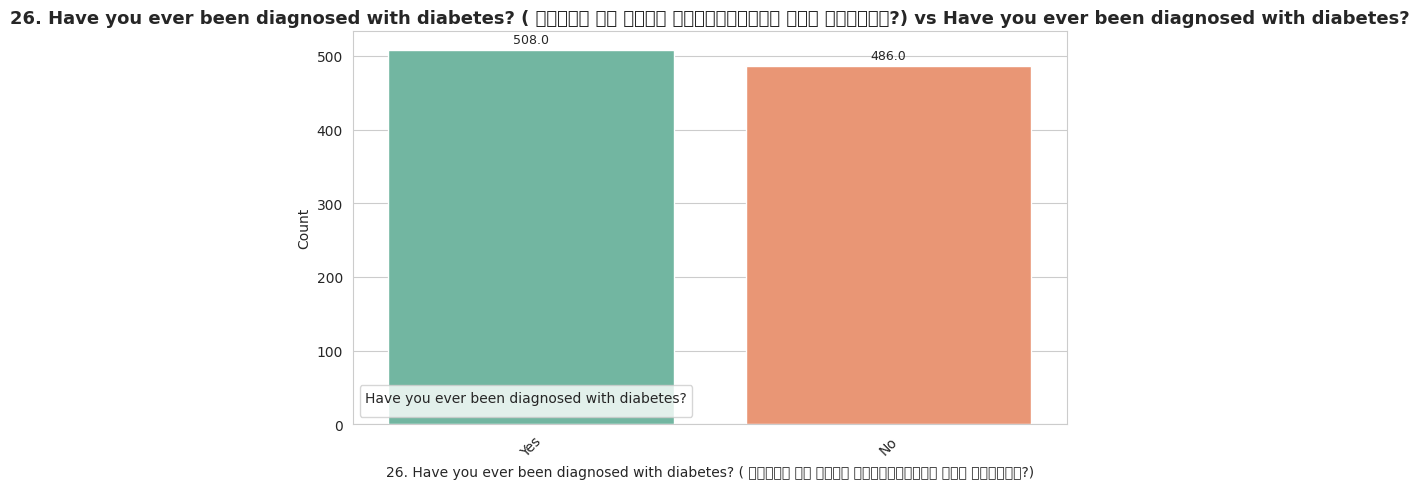

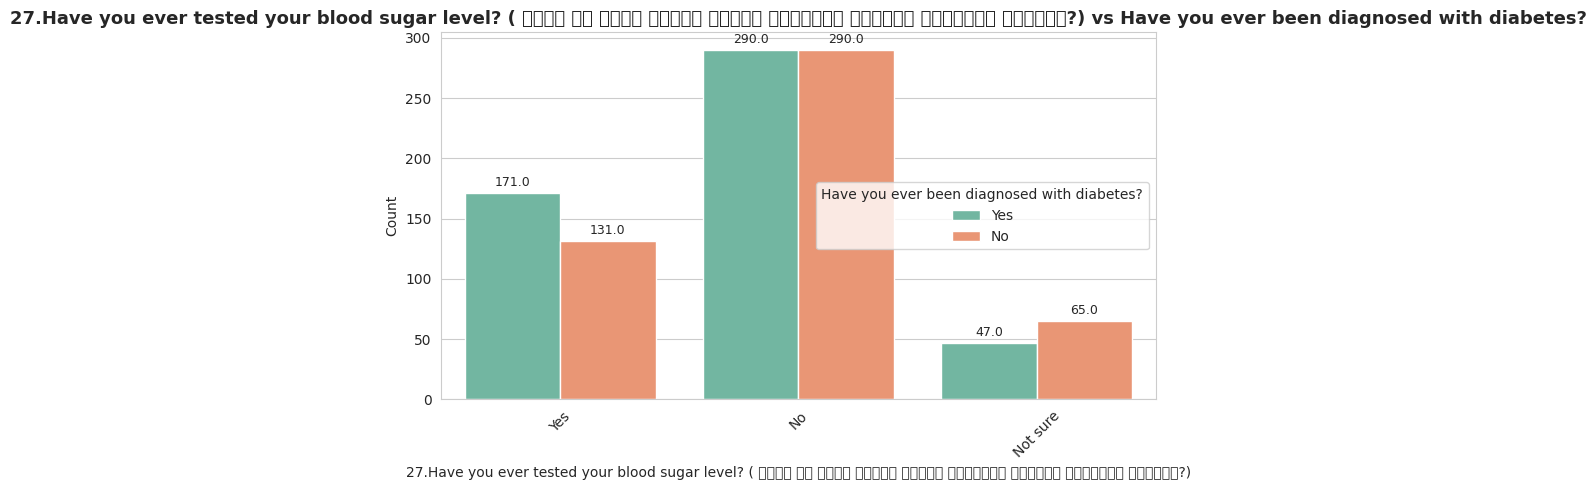

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

for col in categorical_cols:
    plt.figure(figsize=(8,5))

    ax = sns.countplot(
        x=col,
        hue='26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?)',
        data=df,
        palette="Set2"
    )

    # Add count labels on top
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(
                f'{height}',  # <-- just the count
                (p.get_x() + p.get_width()/2., height),
                ha='center',
                va='bottom',
                fontsize=9,
                xytext=(0,3),
                textcoords='offset points'
            )

    plt.xticks(rotation=45)
    plt.title(f"{col} vs Have you ever been diagnosed with diabetes?", fontsize=13, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.legend(title="Have you ever been diagnosed with diabetes?")

    plt.tight_layout()
    plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


Label encoding

In [ ]:
df.columns

Index(['1. What is your age group? (আপনার বয়স কত?)',
       '2. What is your gender? (আপনার লিঙ্গ কী?)',
       '3. What is your occupation? ( আপনার পেশা কী?)',
       '4.What is your weight range? ( আপনার ওজনের সীমা কত?)',
       '5.What is your height? ( আপনার উচ্চতা কত?)',
       '6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)',
       '7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)',
       '8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)',
       '9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)',
       '10.Do you smoke? ( আপনি কি ধূমপান করেন?)',
       '11. How much do you walk daily? ( আপনি প্রতিদিন কত সময় হাঁটেন? )',
       '12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)? ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)',
       '13. How many hours do you use your phone daily

In [ ]:
# =========================
# Find Target Column
# =========================

target_col = None

for col in df.columns:
    if "diagnosed with diabetes" in col.lower():
        target_col = col
        break

print("Target Column:", target_col)

Target Column: 26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?)


In [ ]:
# checking the seasions
df['26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?)'].nunique()

2

In [ ]:
# checking the how many values of the each soil type
df['26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?)'].value_counts()

,count
26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?),
Yes,508
No,486


In [ ]:
# =========================
# Clean Target
# =========================

df = df[df[target_col].notna()]

df[target_col] = df[target_col].astype(str)

df[target_col] = df[target_col].replace({
    "Yes":1,
    "yes":1,
    "Yes, normal":1,
    "Yes,High":1,
    "Yes,High":1,
    "No":0,
    "no":0
})

# remove remaining invalid labels
df = df[df[target_col].isin([0,1])]

# =========================
# Encode Features
# =========================

encoders = {}

for col in df.columns:

    if col == target_col:
        continue

    le = LabelEncoder()

    df[col] = le.fit_transform(df[col].astype(str))

    encoders[col] = le

Split dataset

In [ ]:
# =========================
# X and y
# =========================

X = df.drop(target_col, axis=1)

y = df[target_col]

# =========================
# Train Test Split
# =========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (795, 26)
Test : (199, 26)


In [ ]:
print("Training feature shape :", X_train.shape)
print("Testing feature shape  :", X_test.shape)
print("Training label shape   :", y_train.shape)
print("Testing label shape    :", y_test.shape)


Training feature shape : (795, 26)
Testing feature shape  : (199, 26)
Training label shape   : (795,)
Testing label shape    : (199,)


In [ ]:
print("Training Features (X_train):")
display(X_train.head())

print("Training Labels (y_train):")
display(y_train.head())


Training Features (X_train):


,1. What is your age group? (আপনার বয়স কত?),2. What is your gender? (আপনার লিঙ্গ কী?),3. What is your occupation? ( আপনার পেশা কী?),4.What is your weight range? ( আপনার ওজনের সীমা কত?),5.What is your height? ( আপনার উচ্চতা কত?),6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?),7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?),8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?),9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?),10.Do you smoke? ( আপনি কি ধূমপান করেন?),...,17. Have you ever been diagnosed with high blood pressure? ( আপনার কি কখনো উচ্চ রক্তচাপ ধরা পড়েছে? ),18. How many hours do you sleep daily? ( আপনি প্রতিদিন কত ঘন্টা ঘুমান?),19. How would you describe your stress level? ( আপনার মানসিক চাপের মাত্রা কেমন?),20. Do you feel tired frequently? ( আপনি কি প্রায়ই ক্লান্ত বোধ করেন?),21. Do you feel sleepy after meals? ( খাবার পর কি আপনার ঘুম পায়?),22. Do you urinate frequently? (আপনার কি ঘন ঘন প্রস্রাব হয়? ),23. Do you feel very thirsty? (আপনার কি বেশি পিপাসা লাগে?),24. Do you feel hungry frequently?( আপনার কি ঘন ঘন ক্ষুধা লাগে?),25. Have you lost or gained weight in the last 3 months? (গত ৩ মাসে আপনার কি ওজন কমেছে বা বেড়েছে ?),27.Have you ever tested your blood sugar level? ( আপনি কি কখনো আপনার রক্তে শর্করার মাত্রা পরীক্ষা করেছেন?)
555,0,1,3,2,1,2,3,4,1,0,...,0,1,2,3,2,1,0,0,0,2
841,0,0,3,2,0,2,2,0,0,0,...,0,1,2,1,2,0,0,0,0,0
576,0,0,3,6,0,1,5,1,1,0,...,0,1,1,1,4,0,0,0,0,2
959,0,0,3,2,0,2,2,4,0,0,...,0,0,2,3,1,0,0,0,0,0
145,0,0,3,0,0,3,3,0,1,0,...,1,0,0,3,4,1,1,0,0,0


Training Labels (y_train):


,26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?)
555,0
841,0
576,0
959,0
145,1


In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


Models

Naive bayes


========== Naive Bayes ==========
Train Accuracy : 0.9534591194968554
Test Accuracy  : 0.949748743718593
Precision      : 0.9505265263476403
Recall         : 0.949748743718593
F1 Score       : 0.9497538196030657

Classification Report

              precision    recall  f1-score   support

           0       0.93      0.97      0.95        97
           1       0.97      0.93      0.95       102

    accuracy                           0.95       199
   macro avg       0.95      0.95      0.95       199
weighted avg       0.95      0.95      0.95       199



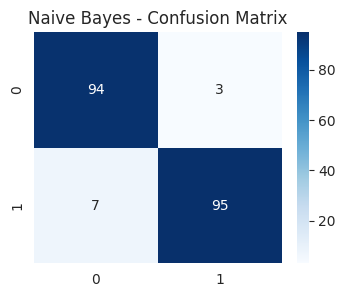

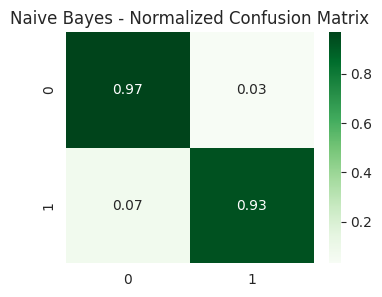

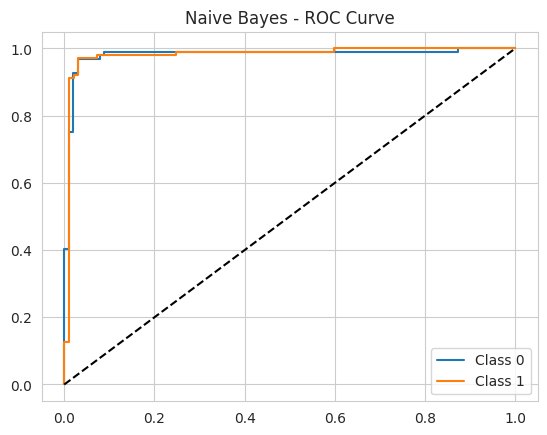

In [ ]:
comparison_results = []

def evaluate_model(model, name):
    print(f"\n========== {name} ==========")

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average='weighted')
    recall    = recall_score(y_test, y_test_pred, average='weighted')
    f1        = f1_score(y_test, y_test_pred, average='weighted')

    # ---- STORE RESULTS ----
    comparison_results.append([
        name, train_acc, test_acc, precision, recall, f1
    ])

    print("Train Accuracy :", train_acc)
    print("Test Accuracy  :", test_acc)
    print("Precision      :", precision)
    print("Recall         :", recall)
    print("F1 Score       :", f1)

    print("\nClassification Report\n")
    print(classification_report(y_test, y_test_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_test_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

    plt.figure(figsize=(4,3))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens')
    plt.title(f"{name} - Normalized Confusion Matrix")
    plt.show()

    # ROC Curve (Multiclass)
    ovr = OneVsRestClassifier(model)
    y_score = ovr.fit(X_train, y_train).predict_proba(X_test)

    plt.figure()
    for i in range(len(np.unique(y_train))):
        fpr, tpr, _ = roc_curve(y_test == i, y_score[:, i])
        plt.plot(fpr, tpr, label=f'Class {i}')

    plt.plot([0,1],[0,1],'k--')
    plt.legend()
    plt.title(f"{name} - ROC Curve")
    plt.show()


evaluate_model(GaussianNB(), "Naive Bayes")

XGB Classifier

In [ ]:
from sklearn.linear_model import LogisticRegression, LinearRegression
# ==============================
# Basic Libraries
# ==============================
import numpy as np
import pandas as pd

# ==============================
# Scikit-Learn Models
# ==============================
from sklearn.linear_model import (
    LogisticRegression,
    SGDClassifier,
    PassiveAggressiveClassifier,
    RidgeClassifier,
    Perceptron
)

from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    BernoulliNB
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.svm import (
    SVC,
    LinearSVC
)

from sklearn.neural_network import MLPClassifier

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)

# ==============================
# XGBoost
# ==============================
from xgboost import XGBClassifier

# ==============================
# LightGBM
# ==============================
from lightgbm import LGBMClassifier

# ==============================
# CatBoost
# ==============================


# ==============================
# Evaluation
# ==============================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split, cross_val_score


========== XG Boost Classifier ==========
Train Accuracy : 0.9987421383647799
Test Accuracy  : 0.949748743718593
Precision      : 0.949748743718593
Recall         : 0.949748743718593
F1 Score       : 0.949748743718593

Classification Report

              precision    recall  f1-score   support

           0       0.95      0.95      0.95        97
           1       0.95      0.95      0.95       102

    accuracy                           0.95       199
   macro avg       0.95      0.95      0.95       199
weighted avg       0.95      0.95      0.95       199



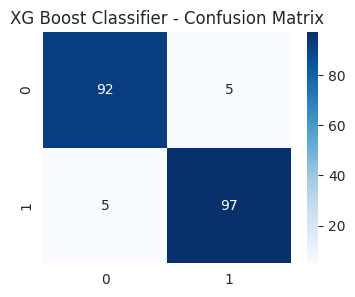

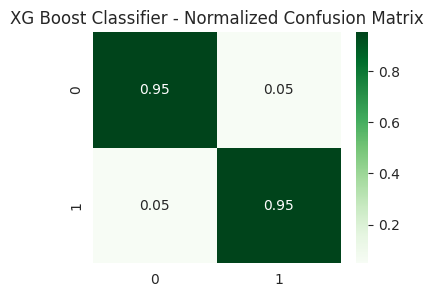

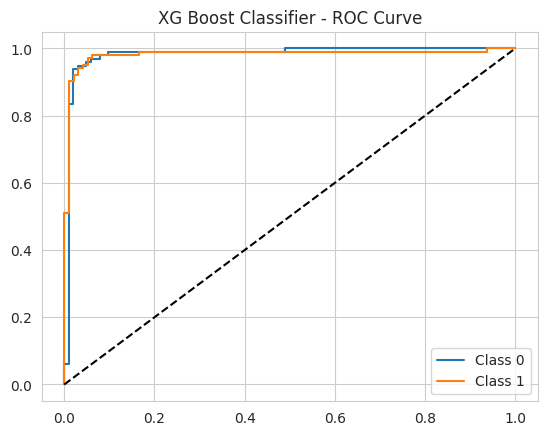

In [ ]:

def evaluate_model(model, name):
    print(f"\n========== {name} ==========")

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average='weighted')
    recall    = recall_score(y_test, y_test_pred, average='weighted')
    f1        = f1_score(y_test, y_test_pred, average='weighted')

    # ---- STORE RESULTS ----
    comparison_results.append([
        name, train_acc, test_acc, precision, recall, f1
    ])

    print("Train Accuracy :", train_acc)
    print("Test Accuracy  :", test_acc)
    print("Precision      :", precision)
    print("Recall         :", recall)
    print("F1 Score       :", f1)

    print("\nClassification Report\n")
    print(classification_report(y_test, y_test_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_test_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

    plt.figure(figsize=(4,3))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens')
    plt.title(f"{name} - Normalized Confusion Matrix")
    plt.show()

    # ROC Curve (Multiclass)
    ovr = OneVsRestClassifier(model)
    y_score = ovr.fit(X_train, y_train).predict_proba(X_test)

    plt.figure()
    for i in range(len(np.unique(y_train))):
        fpr, tpr, _ = roc_curve(y_test == i, y_score[:, i])
        plt.plot(fpr, tpr, label=f'Class {i}')

    plt.plot([0,1],[0,1],'k--')
    plt.legend()
    plt.title(f"{name} - ROC Curve")
    plt.show()


evaluate_model(
   XGBClassifier(

),
    "XG Boost Classifier"
)

RandomForestClassifier


========== Random ForestClassifier ==========
Train Accuracy : 0.9987421383647799
Test Accuracy  : 0.964824120603015
Precision      : 0.9652733363788639
Recall         : 0.964824120603015
F1 Score       : 0.9648294506855059

Classification Report

              precision    recall  f1-score   support

           0       0.95      0.98      0.96        97
           1       0.98      0.95      0.97       102

    accuracy                           0.96       199
   macro avg       0.96      0.97      0.96       199
weighted avg       0.97      0.96      0.96       199



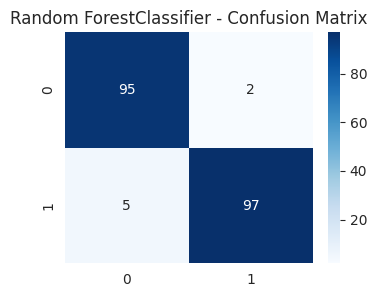

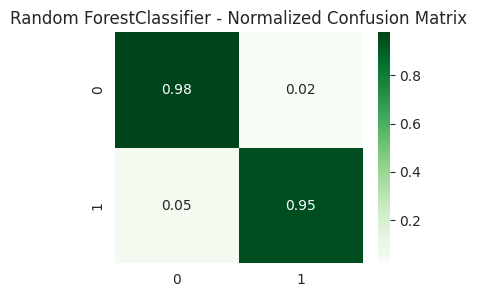

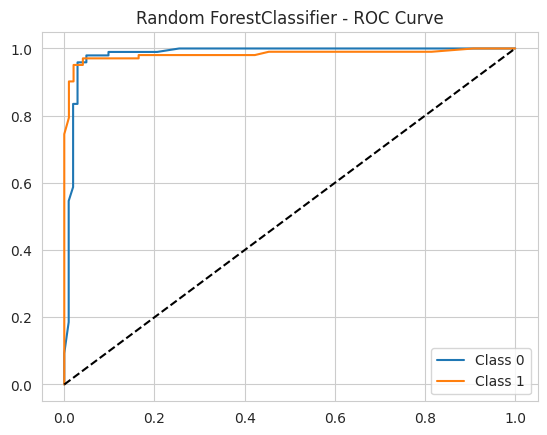

In [ ]:

def evaluate_model(model, name):
    print(f"\n========== {name} ==========")

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average='weighted')
    recall    = recall_score(y_test, y_test_pred, average='weighted')
    f1        = f1_score(y_test, y_test_pred, average='weighted')

    # ---- STORE RESULTS ----
    comparison_results.append([
        name, train_acc, test_acc, precision, recall, f1
    ])

    print("Train Accuracy :", train_acc)
    print("Test Accuracy  :", test_acc)
    print("Precision      :", precision)
    print("Recall         :", recall)
    print("F1 Score       :", f1)

    print("\nClassification Report\n")
    print(classification_report(y_test, y_test_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_test_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

    plt.figure(figsize=(4,3))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens')
    plt.title(f"{name} - Normalized Confusion Matrix")
    plt.show()

    # ROC Curve (Multiclass)
    ovr = OneVsRestClassifier(model)
    y_score = ovr.fit(X_train, y_train).predict_proba(X_test)

    plt.figure()
    for i in range(len(np.unique(y_train))):
        fpr, tpr, _ = roc_curve(y_test == i, y_score[:, i])
        plt.plot(fpr, tpr, label=f'Class {i}')

    plt.plot([0,1],[0,1],'k--')
    plt.legend()
    plt.title(f"{name} - ROC Curve")
    plt.show()


evaluate_model(
    RandomForestClassifier(
        n_estimators=100,
        criterion='gini',
        random_state=42
    ),
    "Random ForestClassifier"
)


AdaBoostClassifier

In [ ]:
from sklearn.preprocessing import label_binarize


========== AdaBoostClassifier ==========
Train Accuracy : 0.9635220125786164
Test Accuracy  : 0.964824120603015
Precision      : 0.9648799666142391
Recall         : 0.964824120603015
F1 Score       : 0.9648276750685346

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.97      0.96        97
           1       0.97      0.96      0.97       102

    accuracy                           0.96       199
   macro avg       0.96      0.96      0.96       199
weighted avg       0.96      0.96      0.96       199



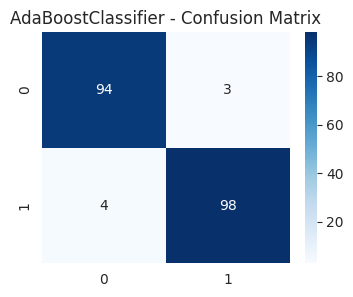

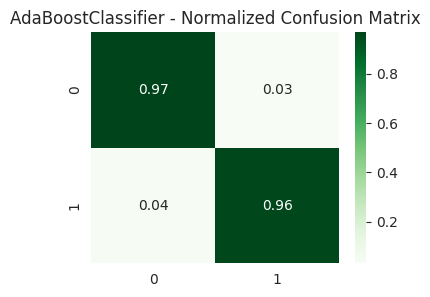

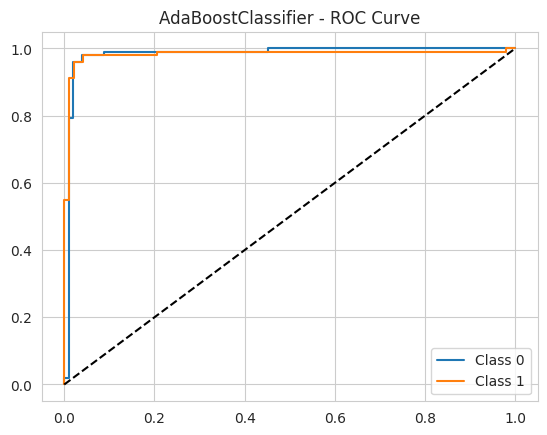

In [ ]:

def evaluate_model(model, name):
    print(f"\n========== {name} ==========")

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average='weighted')
    recall    = recall_score(y_test, y_test_pred, average='weighted')
    f1        = f1_score(y_test, y_test_pred, average='weighted')

    # ---- STORE RESULTS ----
    comparison_results.append([
        name, train_acc, test_acc, precision, recall, f1
    ])

    print("Train Accuracy :", train_acc)
    print("Test Accuracy  :", test_acc)
    print("Precision      :", precision)
    print("Recall         :", recall)
    print("F1 Score       :", f1)

    print("\nClassification Report\n")
    print(classification_report(y_test, y_test_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_test_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

    plt.figure(figsize=(4,3))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens')
    plt.title(f"{name} - Normalized Confusion Matrix")
    plt.show()

    # ROC Curve (Multiclass)
    ovr = OneVsRestClassifier(model)
    y_score = ovr.fit(X_train, y_train).predict_proba(X_test)

    plt.figure()
    for i in range(len(np.unique(y_train))):
        fpr, tpr, _ = roc_curve(y_test == i, y_score[:, i])
        plt.plot(fpr, tpr, label=f'Class {i}')

    plt.plot([0,1],[0,1],'k--')
    plt.legend()
    plt.title(f"{name} - ROC Curve")
    plt.show()


evaluate_model(
    AdaBoostClassifier(),
    "AdaBoostClassifier"
)

Decision Tree Classifier


========== DecisionTreeClassifier ==========
Train Accuracy : 0.9987421383647799
Test Accuracy  : 0.914572864321608
Precision      : 0.914636325697999
Recall         : 0.914572864321608
F1 Score       : 0.9145814965950124

Classification Report

              precision    recall  f1-score   support

           0       0.91      0.92      0.91        97
           1       0.92      0.91      0.92       102

    accuracy                           0.91       199
   macro avg       0.91      0.91      0.91       199
weighted avg       0.91      0.91      0.91       199



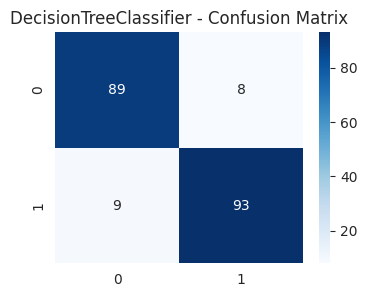

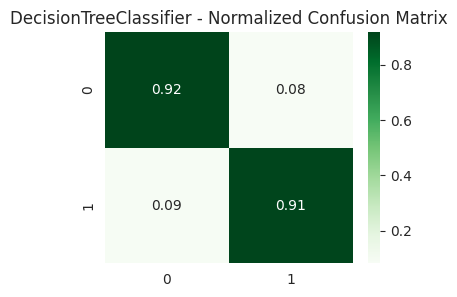

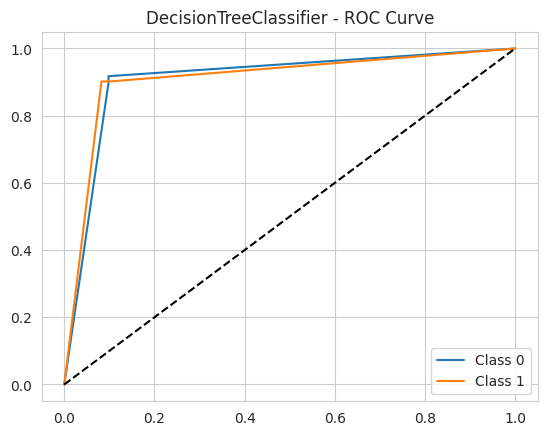

In [ ]:

def evaluate_model(model, name):
    print(f"\n========== {name} ==========")

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average='weighted')
    recall    = recall_score(y_test, y_test_pred, average='weighted')
    f1        = f1_score(y_test, y_test_pred, average='weighted')

    # ---- STORE RESULTS ----
    comparison_results.append([
        name, train_acc, test_acc, precision, recall, f1
    ])

    print("Train Accuracy :", train_acc)
    print("Test Accuracy  :", test_acc)
    print("Precision      :", precision)
    print("Recall         :", recall)
    print("F1 Score       :", f1)

    print("\nClassification Report\n")
    print(classification_report(y_test, y_test_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_test_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

    plt.figure(figsize=(4,3))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens')
    plt.title(f"{name} - Normalized Confusion Matrix")
    plt.show()

    # ROC Curve (Multiclass)
    ovr = OneVsRestClassifier(model)
    y_score = ovr.fit(X_train, y_train).predict_proba(X_test)

    plt.figure()
    for i in range(len(np.unique(y_train))):
        fpr, tpr, _ = roc_curve(y_test == i, y_score[:, i])
        plt.plot(fpr, tpr, label=f'Class {i}')

    plt.plot([0,1],[0,1],'k--')
    plt.legend()
    plt.title(f"{name} - ROC Curve")
    plt.show()


evaluate_model(
    DecisionTreeClassifier(),
    "DecisionTreeClassifier")


Model comparison

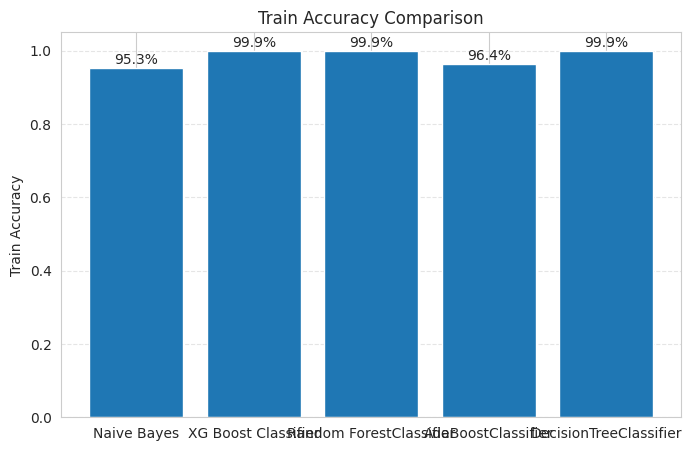

In [ ]:
results = np.array(comparison_results, dtype=object)

models     = results[:, 0]
train_acc  = results[:, 1].astype(float)


def plot_metric(values, title, ylabel):
    plt.figure(figsize=(8,5))
    bars = plt.bar(models, values)

    for bar in bars:
        h = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.01,
            f"{h*100:.1f}%",
            ha='center',
            fontsize=10
        )

    plt.ylim(0,1.05)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()
plot_metric(train_acc, "Train Accuracy Comparison", "Train Accuracy")



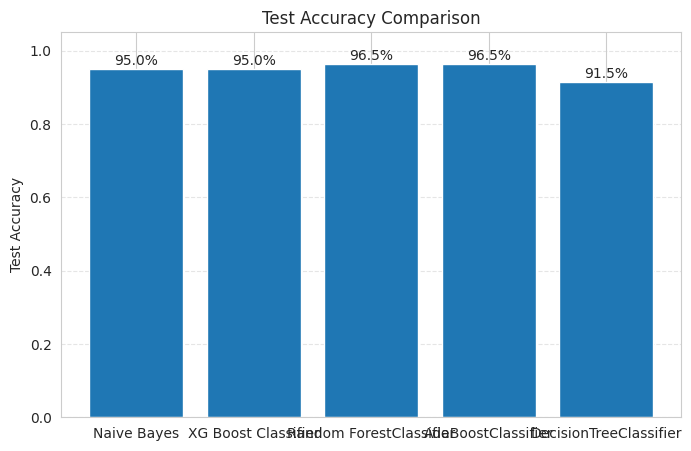

In [ ]:
results = np.array(comparison_results, dtype=object)

models     = results[:, 0]
test_acc   = results[:, 2].astype(float)


def plot_metric(values, title, ylabel):
    plt.figure(figsize=(8,5))
    bars = plt.bar(models, values)

    for bar in bars:
        h = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.01,
            f"{h*100:.1f}%",
            ha='center',
            fontsize=10
        )

    plt.ylim(0,1.05)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

plot_metric(test_acc,  "Test Accuracy Comparison",  "Test Accuracy")


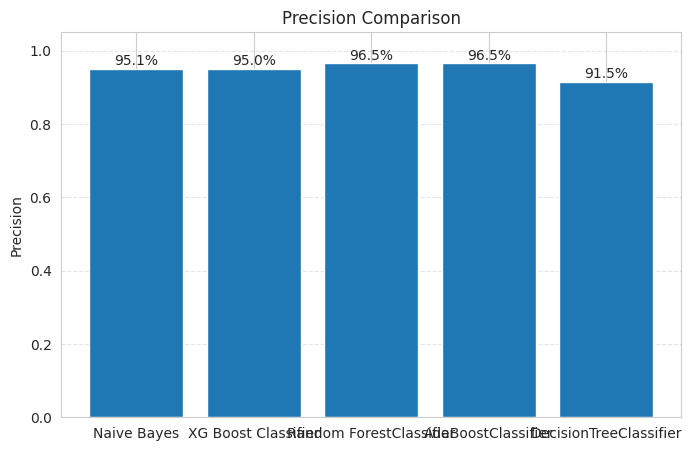

In [ ]:
results = np.array(comparison_results, dtype=object)

models     = results[:, 0]

precision  = results[:, 3].astype(float)


def plot_metric(values, title, ylabel):
    plt.figure(figsize=(8,5))
    bars = plt.bar(models, values)

    for bar in bars:
        h = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.01,
            f"{h*100:.1f}%",
            ha='center',
            fontsize=10
        )

    plt.ylim(0,1.05)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

plot_metric(precision, "Precision Comparison",      "Precision")



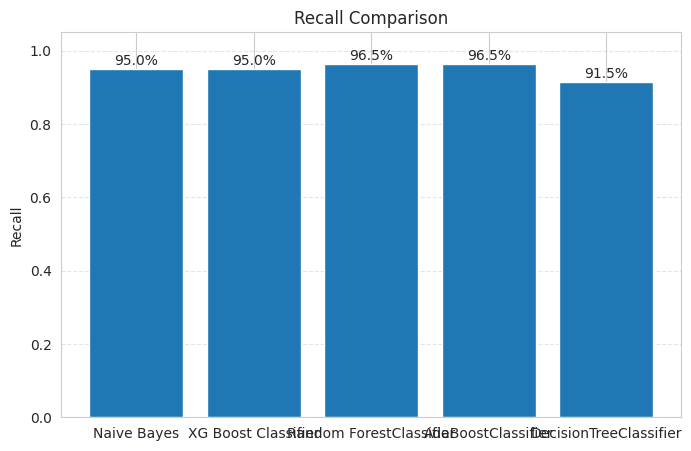

In [ ]:
results = np.array(comparison_results, dtype=object)

models     = results[:, 0]

recall     = results[:, 4].astype(float)


def plot_metric(values, title, ylabel):
    plt.figure(figsize=(8,5))
    bars = plt.bar(models, values)

    for bar in bars:
        h = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.01,
            f"{h*100:.1f}%",
            ha='center',
            fontsize=10
        )

    plt.ylim(0,1.05)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

plot_metric(recall,    "Recall Comparison",         "Recall")



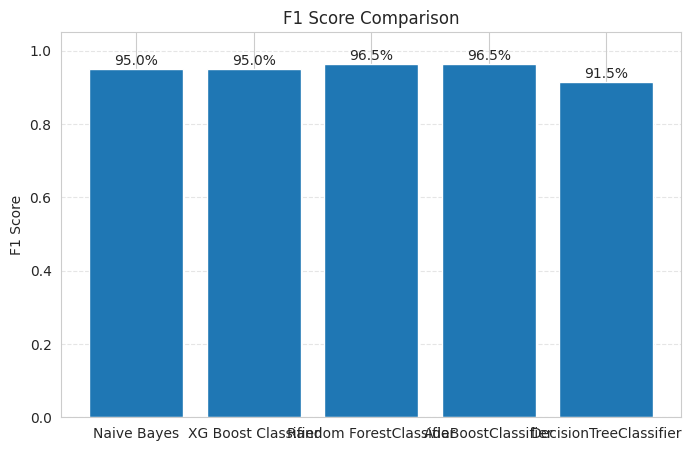

In [ ]:
results = np.array(comparison_results, dtype=object)

models     = results[:, 0]
f1_score_v = results[:, 5].astype(float)

def plot_metric(values, title, ylabel):
    plt.figure(figsize=(8,5))
    bars = plt.bar(models, values)

    for bar in bars:
        h = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.01,
            f"{h*100:.1f}%",
            ha='center',
            fontsize=10
        )

    plt.ylim(0,1.05)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

plot_metric(f1_score_v,"F1 Score Comparison",       "F1 Score")


🏆 BEST MODEL
Model             Random ForestClassifier
Train Accuracy                   0.998742
Test Accuracy                    0.964824
Precision                        0.965273
Recall                           0.964824
F1 Score                         0.964829
Name: 0, dtype: object


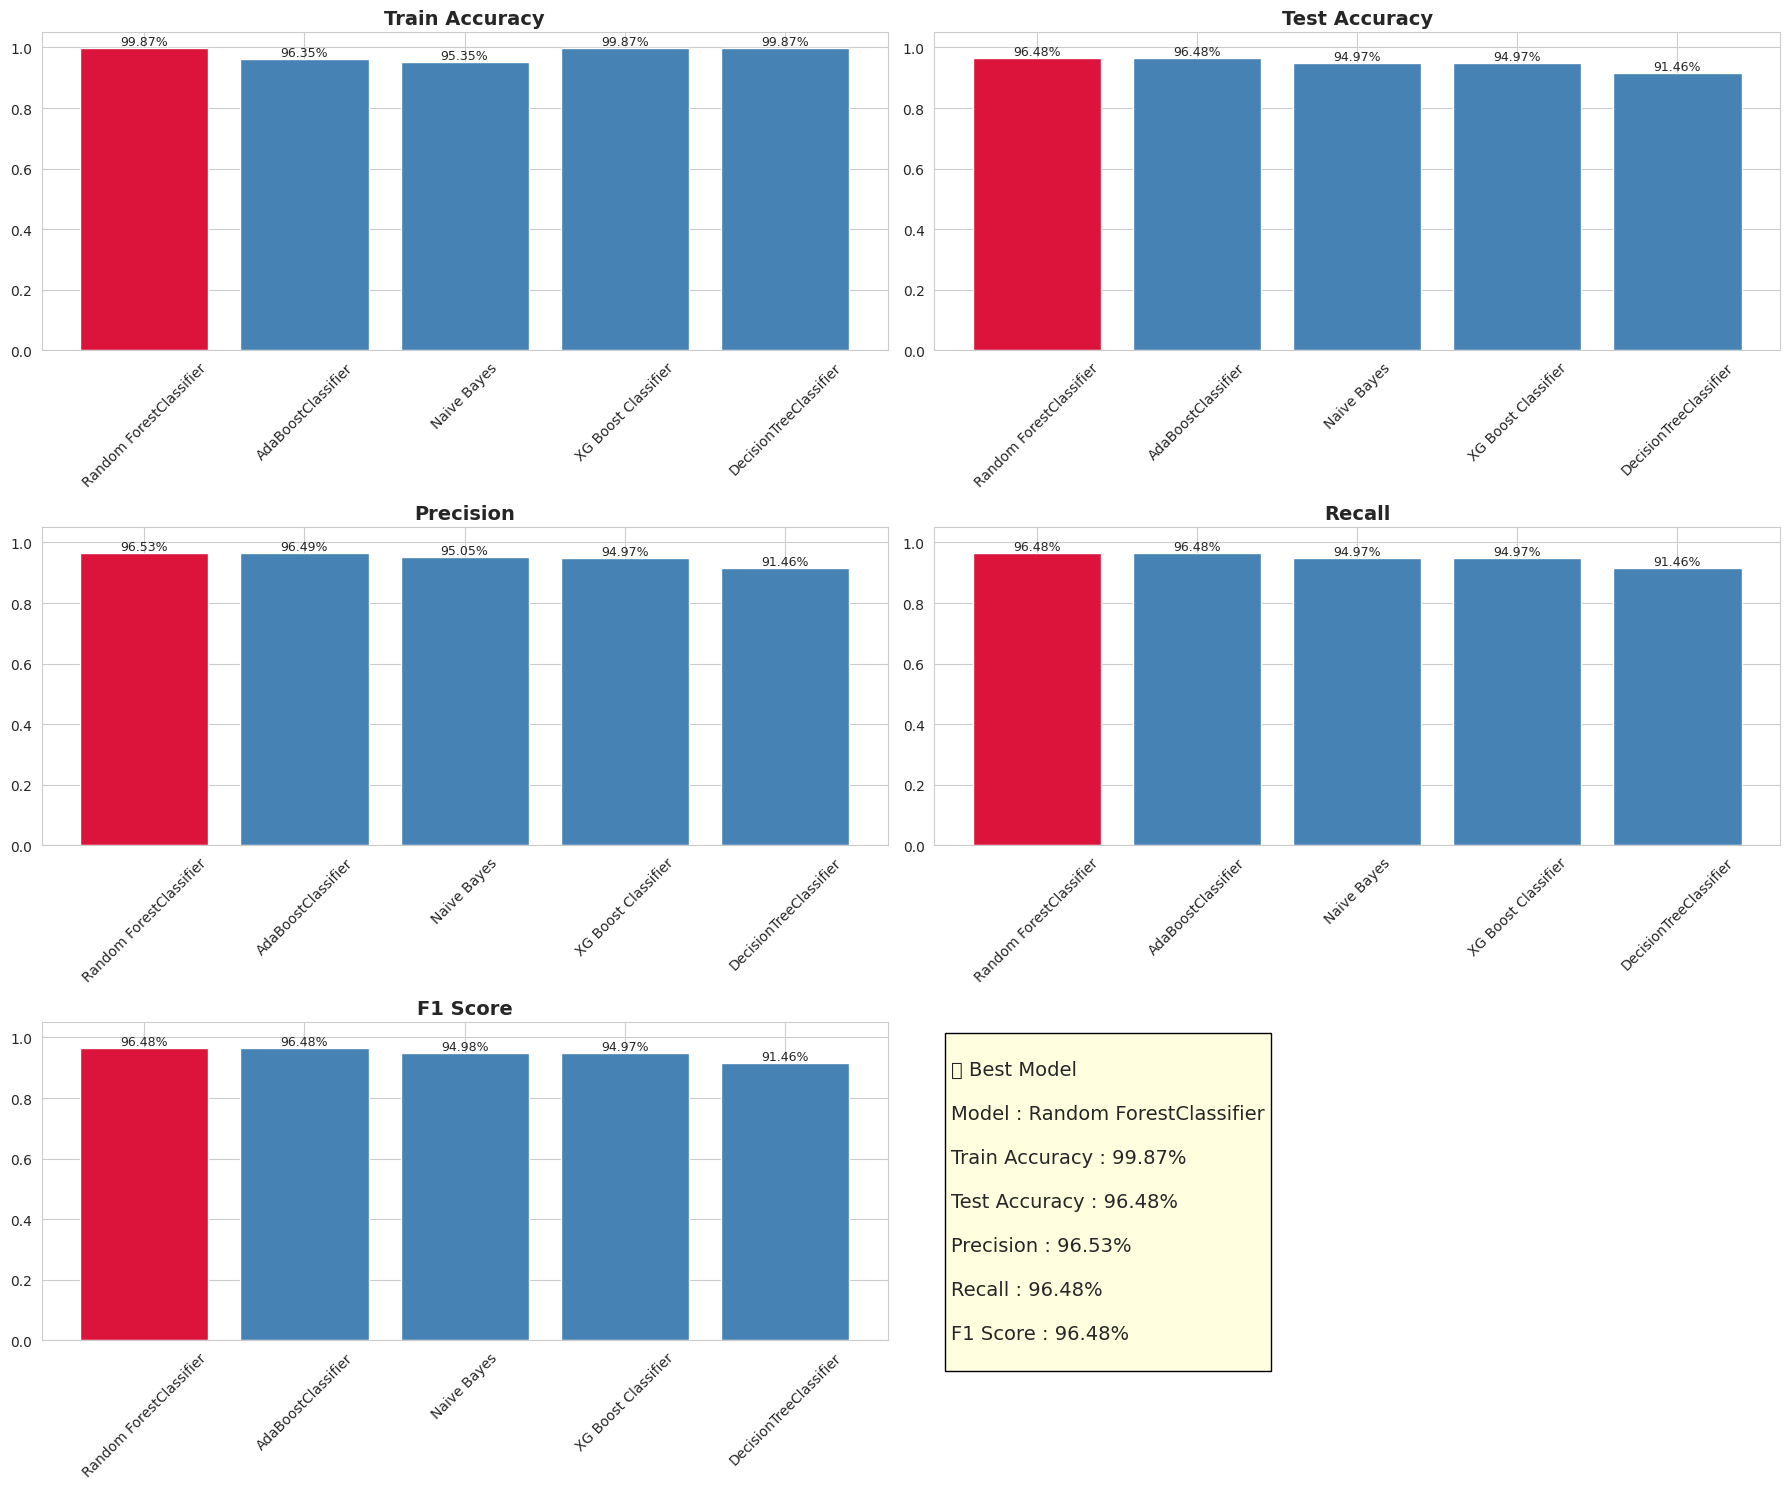

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Random ForestClassifier,0.998742,0.964824,0.965273,0.964824,0.964829
1,AdaBoostClassifier,0.963522,0.964824,0.964880,0.964824,0.964828
2,Naive Bayes,0.953459,0.949749,0.950527,0.949749,0.949754
3,XG Boost Classifier,0.998742,0.949749,0.949749,0.949749,0.949749
4,DecisionTreeClassifier,0.998742,0.914573,0.914636,0.914573,0.914581


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ===========================
# Results DataFrame
# ===========================

results_df = pd.DataFrame(
    comparison_results,
    columns=[
        "Model",
        "Train Accuracy",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

# Convert to float
for col in results_df.columns[1:]:
    results_df[col] = results_df[col].astype(float)

# Sort by Test Accuracy
results_df = results_df.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

# Highest model
best_model = results_df.iloc[0]

print("="*60)
print("🏆 BEST MODEL")
print("="*60)
print(best_model)
print("="*60)

# ===========================
# Plot
# ===========================

metrics = [
    "Train Accuracy",
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

fig, axes = plt.subplots(3, 2, figsize=(18, 15))
axes = axes.flatten()

for idx, metric in enumerate(metrics):

    colors = ["steelblue"] * len(results_df)
    colors[0] = "crimson"      # Highlight best model

    bars = axes[idx].bar(
        results_df["Model"],
        results_df[metric],
        color=colors
    )

    axes[idx].set_ylim(0, 1.05)
    axes[idx].set_title(metric, fontsize=14, weight='bold')
    axes[idx].tick_params(axis='x', rotation=45)

    for bar in bars:
        h = bar.get_height()
        axes[idx].text(
            bar.get_x() + bar.get_width()/2,
            h + 0.01,
            f"{h*100:.2f}%",
            ha="center",
            fontsize=9
        )

# ===========================
# Best Model Summary
# ===========================

axes[5].axis("off")

summary = f"""
🏆 Best Model

Model : {best_model['Model']}

Train Accuracy : {best_model['Train Accuracy']*100:.2f}%

Test Accuracy : {best_model['Test Accuracy']*100:.2f}%

Precision : {best_model['Precision']*100:.2f}%

Recall : {best_model['Recall']*100:.2f}%

F1 Score : {best_model['F1 Score']*100:.2f}%
"""

axes[5].text(
    0.02,
    0.95,
    summary,
    fontsize=14,
    verticalalignment="top",
    bbox=dict(facecolor="lightyellow", edgecolor="black")
)

plt.tight_layout()
plt.show()

# ===========================
# Final Comparison Table
# ===========================

display(results_df)

In [ ]:
df.columns

Index(['1. What is your age group? (আপনার বয়স কত?)',
       '2. What is your gender? (আপনার লিঙ্গ কী?)',
       '3. What is your occupation? ( আপনার পেশা কী?)',
       '4.What is your weight range? ( আপনার ওজনের সীমা কত?)',
       '5.What is your height? ( আপনার উচ্চতা কত?)',
       '6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)',
       '7 .Do you often crave sweets? (আপনার কি প্রায়ই মিষ্টি খেতে ইচ্ছা করে?)',
       '8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)',
       '9.How much water do you drink daily? ( আপনি প্রতিদিন কী পরিমাণ পানি পান করেন?)',
       '10.Do you smoke? ( আপনি কি ধূমপান করেন?)',
       '11. How much do you walk daily? ( আপনি প্রতিদিন কত সময় হাঁটেন? )',
       '12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)? ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)',
       '13. How many hours do you use your phone daily

In [ ]:
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


# ==========================
# Load Dataset
# ==========================

df = pd.read_csv(
    "/content/drive/MyDrive/Diabetics/dataset Update.csv"
)


# ==========================
# Remove Unnecessary Columns
# ==========================

drop_cols = [
    "Timestamp"
]

# Clean column names
df.columns = (
    df.columns
    .str.replace('\xa0', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

for col in drop_cols:
    if col in df.columns:
        df.drop(col, axis=1, inplace=True)



# ==========================
# Target Column
# ==========================

target_col = (
"26. Have you ever been diagnosed with diabetes? ( আপনার কি কখনো ডায়াবেটিস ধরা পড়েছে?)"
)



# ==========================
# Select Important 10 Features
# ==========================

features = [

 "1. What is your age group? (আপনার বয়স কত?)",

    "4.What is your weight range? ( আপনার ওজনের সীমা কত?)",

    "16.Does anyone in your family have Diabetes? ( আপনার পরিবারের কারো কি ডায়াবেটিস আছে? )",

    "17. Have you ever been diagnosed with high blood pressure? ( আপনার কি কখনো উচ্চ রক্তচাপ ধরা পড়েছে? )",

    "6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)",

    "12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)? ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)",

    "8. How often do you eat fast food or junk food? ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)",

    "11. How much do you walk daily? ( আপনি প্রতিদিন কত সময় হাঁটেন? )",

    "18. How many hours do you sleep daily? ( আপনি প্রতিদিন কত ঘন্টা ঘুমান?)",

    "20. Do you feel tired frequently? ( আপনি কি প্রায়ই ক্লান্ত বোধ করেন?)",

    "2. What is your gender? (আপনার লিঙ্গ কী?)"


]



# Feature and Target

X = df[features]

y = df[target_col]



# ==========================
# Encode Target
# ==========================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)



# ==========================
# Preprocessing
# ==========================

categorical_cols = X.columns.tolist()


preprocessor = ColumnTransformer(
    transformers=[

        (
            "cat",

            Pipeline([

                (
                "imputer",
                SimpleImputer(strategy="most_frequent")
                ),

                (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore"
                )
                )

            ]),

            categorical_cols
        )
    ]
)



# ==========================
# Random Forest Model
# ==========================

rf = RandomForestClassifier(

    n_estimators=300,

    max_depth=12,

    random_state=42

)



model = Pipeline([

    ("preprocessor", preprocessor),

    ("classifier", rf)

])



# ==========================
# Train Test Split
# ==========================

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)



# ==========================
# Training
# ==========================

model.fit(
    X_train,
    y_train
)




# ==========================
# Save Model
# ==========================


joblib.dump(
    model,
    "diabetes_10feature_model.pkl"
)


joblib.dump(
    label_encoder,
    "diabetes_label_encoder.pkl"
)



print("\nModel Saved Successfully!")


Model Saved Successfully!


In [ ]:
import joblib
import pandas as pd


# ==============================
# Load Model
# ==============================

model = joblib.load("diabetes_10feature_model.pkl")
label_encoder = joblib.load("diabetes_label_encoder.pkl")



# ==============================
# User Input Function
# ==============================

def diabetes_input():

    data = {}

    print("\n🩺 ===== Diabetes Risk Prediction =====\n")


    data["1.What is your age group?   (আপনার বয়স কত?)"] = input(
        """
১. আপনার বয়সের গ্রুপ নির্বাচন করুন:
   Options: Under 18 / 18-25 / 26-35 / 35-40

Your Input: """
    )


    data["2.What is your gender?  (আপনার লিঙ্গ কী?)"] = input(
        """
২. আপনার লিঙ্গ কী?
   Options: Female / Male

Your Input: """
    )


    data["  4.What is your weight range?  (  আপনার ওজনের সীমা কত?)"] = input(
        """
৩. আপনার ওজনের সীমা নির্বাচন করুন:
   Options:
   Below 50 kg / 50–60 kg / 61–70 kg /
   71-80 kg / 81-90 kg / 91-100 kg / 100 +

Your Input: """
    )


    data["16.Does anyone in your family have Diabetes? ( আপনার পরিবারের কারো কি ডায়াবেটিস আছে? )  "] = input(
        """
৪. আপনার পরিবারের কারো Diabetes আছে কি?
   Options:
   No / Not Sure / Yes (Parents) / Yes (Grandparents)

Your Input: """
    )


    data["17. Have you ever been diagnosed with high blood pressure? ( আপনার কি কখনো উচ্চ রক্তচাপ ধরা পড়েছে?  )"] = input(
        """
৫. আপনার কি উচ্চ রক্তচাপ আছে?
   Options: Yes / No

Your Input: """
    )


    data["6. How many days per week do you exercise? ( সপ্তাহে কত দিন আপনি ব্যায়াম করেন?)"] = input(
        """
৬. সপ্তাহে কত দিন ব্যায়াম করেন?
   Options:
   Never / 1-2 Days / 3-4 Days / Daily

Your Input: """
    )


    data["12. How often do you eat sugary foods or drinks (sweets, soft drinks, chocolates)?  ( আপনি কতবার মিষ্টি জাতীয় খাবার বা পানীয় (মিষ্টি, কোমল পানীয়, চকোলেট) গ্রহণ করেন?)"] = input(
        """
৭. আপনি কতবার মিষ্টি বা চিনিযুক্ত খাবার/পানীয় খান?
   Options:
   Never / Rarely / 1–2 times per week /
   3–4 times per week / Daily

Your Input: """
    )


    data["8. How often do you eat fast food or junk food?  ( আপনি কতবার ফাস্ট ফুড বা জাঙ্ক ফুড খান?)"] = input(
        """
৮. আপনি কতবার Fast Food বা Junk Food খান?
   Options:
   Never / Sometimes / 1–2 times per week /
   3–4 times per week / Daily

Your Input: """
    )


    data["11.  How much do you walk daily?  ( আপনি প্রতিদিন কত সময় হাঁটেন? )"] = input(
        """
৯. প্রতিদিন কত সময় হাঁটেন?
   Options:
   I rarely walk /
   Less than 15 minutes /
   15 – 30 minutes /
   30 – 60 minutes /
   More than 1 hour

Your Input: """
    )


    data["18. How many hours do you sleep daily?  (  আপনি প্রতিদিন কত ঘন্টা ঘুমান?)"] = input(
        """
১০. প্রতিদিন কত ঘণ্টা ঘুমান?
   Options:
   Less than 5 hours /
   5 -6 Hours /
   7-8 Hours /
   More than 8 hours

Your Input: """
    )


    data["20. Do you feel tired frequently?  ( আপনি কি প্রায়ই ক্লান্ত বোধ করেন?)"] = input(
        """
১১. আপনি কি প্রায়ই ক্লান্ত অনুভব করেন?
   Options:
   Never / Rarely / Sometimes / Often

Your Input: """
    )


    return pd.DataFrame([data])



# ==============================
# Prediction
# ==============================

user_data = diabetes_input()



prediction = model.predict(user_data)



result = label_encoder.inverse_transform(prediction)[0]



print("\n==============================")
print("🩺 ডায়াবেটিস পূর্বাভাস ফলাফল")
print("==============================")


if result == "Yes":

    print("⚠️ ঝুঁকি: ডায়াবেটিসের সম্ভাবনা রয়েছে")

else:

    print("✅ ঝুঁকি: ডায়াবেটিসের সম্ভাবনা কম")



# Confidence Score

if hasattr(model, "predict_proba"):

    confidence = model.predict_proba(user_data).max()*100

    print(
        "বিশ্বাসযোগ্যতা:",
        round(confidence,2),
        "%"
    )


print("==============================")


🩺 ===== Diabetes Risk Prediction =====


১. আপনার বয়সের গ্রুপ নির্বাচন করুন:
   Options: Under 18 / 18-25 / 26-35 / 35-40

Your Input: 18-25

২. আপনার লিঙ্গ কী?
   Options: Female / Male

Your Input: Male

৩. আপনার ওজনের সীমা নির্বাচন করুন:
   Options:
   Below 50 kg / 50–60 kg / 61–70 kg /
   71-80 kg / 81-90 kg / 91-100 kg / 100 +

Your Input: 50-60 kg

৪. আপনার পরিবারের কারো Type 2 Diabetes আছে কি?
   Options:
   No / Not Sure / Yes (Parents) / Yes (Grandparents)

Your Input: Not Sure

৫. আপনার কি উচ্চ রক্তচাপ আছে?
   Options: Yes / No

Your Input: No

৬. সপ্তাহে কত দিন ব্যায়াম করেন?
   Options:
   Never / 1-2 Days / 3-4 Days / Daily

Your Input: Never

৭. আপনি কতবার মিষ্টি বা চিনিযুক্ত খাবার/পানীয় খান?
   Options:
   Never / Rarely / 1–2 times per week /
   3–4 times per week / Daily

Your Input: Never

৮. আপনি কতবার Fast Food বা Junk Food খান?
   Options:
   Never / Sometimes / 1–2 times per week /
   3–4 times per week / Daily

Your Input: 3-4 times per week

৯. প্রতিদিন কত সময় 

END